# 09 · Softmax Regression: Multi-class Classification
*AI Foundations · Notebook 09 of 19*

Logistic regression answers yes/no questions. Many interesting questions have more than two
possible answers: Which digit is in this image? Which language is this sentence written in?
Which of three outfits should a weather app recommend today? **Softmax regression** (also called
*multinomial logistic regression*) is the natural extension of logistic regression to $K$ classes.
It gives every class its own linear score, turns the $K$ scores into a probability distribution
with the **softmax function**, and is trained by minimizing the **cross-entropy** with gradient
descent. It is also exactly the last layer of almost every neural-network classifier, so
everything you learn here carries straight over to deep learning.

**What you will learn**
- why $K$ independent yes/no classifiers make a poor multi-class model, and which properties a good one needs.
- the softmax function inside out: positivity, normalization, monotonicity, shift invariance,
  temperature, its link to the sigmoid, and how to compute it without overflow (log-sum-exp, log-softmax).
- the model $\mathbf z = \mathbf W\mathbf x + \mathbf b$: shapes, decision regions with piecewise-linear
  boundaries, and why its parameters are not unique.
- categorical cross-entropy as a negative log-likelihood.
- the full gradient derivation (softmax Jacobian, $\partial\mathcal L/\partial\mathbf z = \mathbf p-\mathbf y$
  derived two ways, $\partial\mathcal L/\partial\mathbf W$ and $\partial\mathcal L/\partial\mathbf b$ in matrix form),
  checked with finite differences and PyTorch autograd.
- batch gradient descent: one epoch by hand, an *exact* table over 100,000 epochs, what happens on
  separable data, and L2 regularization.
- a complete digit classifier from scratch (mini-batch GD, learning-rate and regularization studies,
  confusion matrix, precision/recall, weight templates), cross-checked against scikit-learn and PyTorch.
- calibration, temperature scaling and top-$k$ accuracy.

**Prerequisites:** logistic regression (sigmoid, binary cross-entropy, gradient descent), NumPy arrays
and broadcasting, matrix–vector products, the chain rule.      **Estimated time:** ~4 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. From two classes to $K$ classes
2. The softmax function
3. The softmax regression model
4. The loss: categorical cross-entropy
5. The gradient, step by step
6. Batch gradient descent on a toy problem, by hand and by code
7. Watching softmax regression learn in 2D
8. Real data: handwritten digits
9. Top-$k$ accuracy, calibration and temperature scaling
10. More practice: the wine dataset
11. Quiz
12. Summary and going further

In [1]:
# ---- Setup: imports, reproducibility, plotting style, a tiny test harness ----
import math
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import scipy
from scipy.special import softmax as scipy_softmax, log_softmax as scipy_log_softmax
from scipy.optimize import minimize, minimize_scalar
import sklearn
from sklearn.datasets import load_digits, load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, top_k_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# This notebook only uses datasets that ship with scikit-learn or are generated in code: nothing is downloaded.
DATA_DIR = Path("data")

# One colour + one marker per class for the 3-class pictures (a colour-blind-safe trio, and the marker
# shapes make the classes distinguishable even in grayscale).
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
CLASS_MARKERS = ["o", "s", "^"]
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#104281", "#5598e7", "#f0efec", "#e66767", "#a8302f"])

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"Matplotlib {matplotlib.__version__}")
print(f"SciPy {scipy.__version__} | scikit-learn {sklearn.__version__} | PyTorch {torch.__version__}")


def clean(a, decimals=4):
    """Round numbers for printing and turn -0.0 into 0.0 (works for scalars, arrays and DataFrames)."""
    return np.round(a, decimals) + 0.0


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet: fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | NumPy 2.5.3 | pandas 2.3.3 | Matplotlib 3.11.2
SciPy 1.18.1 | scikit-learn 1.9.1 | PyTorch 2.14.1+cu130


## 1. From two classes to $K$ classes

### 1.1 Multi-class problems and the words we will use

In **multi-class classification** every example belongs to exactly one of $K \ge 3$ classes.
Examples: recognizing a handwritten digit ($K = 10$), identifying the language of a sentence,
tagging each word of a sentence as noun/verb/adjective/..., or deciding which of three outfits a
weather app should recommend.

That last one will be our **running example**. From a single number, the temperature, the app
recommends a **coat** (class 0), a **sweater** (class 1) or a **t-shirt** (class 2). It is small
enough to compute by hand, yet it already shows every idea of this notebook.

Vocabulary (we will meet each term properly, and this table is for reference):

| Term | Meaning in this notebook |
|---|---|
| class / label | one of the $K$ possible answers, numbered $0, 1, \dots, K-1$ |
| multi-class classification | predict which **one** of $K$ mutually exclusive classes an example belongs to |
| multi-label classification | (*not* this notebook) an example may carry several labels at once, e.g. a photo showing a cat **and** a dog |
| logit (score) | a real number $z_k \in (-\infty, \infty)$ saying how strongly the model favors class $k$ |
| softmax function | turns a vector of $K$ logits into $K$ positive probabilities that sum to 1 |
| softmax regression | one linear score per class followed by softmax (a.k.a. multinomial logistic regression) |
| one-hot vector | the label $y$ written as a length-$K$ vector with a single 1 at position $y$ |
| categorical cross-entropy | the loss $-\log(\text{probability of the correct class})$, averaged over samples |
| gradient descent (GD) | repeat: compute the gradient of the loss, take a small step against it |
| batch / mini-batch / stochastic GD | gradient computed from all $N$ samples / from a small random subset / from one sample |
| epoch | one full pass over the training set |
| learning rate $\eta$ | the step size of gradient descent |
| hyperparameter | a setting you choose rather than learn: $\eta$, the number of epochs, the batch size, the regularization strength $\lambda$ |

Notation, with the **shape** of every object (we use column vectors, as in most textbooks):

| Symbol | Shape | Meaning |
|---|---|---|
| $N,\ K,\ D$ | numbers | number of samples, classes, features |
| $\mathbf x_i$ | $D\times 1$ | feature vector of sample $i$ |
| $y_i$ | integer | true class of sample $i$, $y_i\in\{0,\dots,K-1\}$ |
| $\mathbf y_i$ | $K\times 1$ | one-hot version of $y_i$. For $K=3$, $y_i=1 \Rightarrow \mathbf y_i=(0,1,0)^\top$ |
| $\mathbf W$ | $K\times D$ | weight matrix. **Row** $k$ is $\mathbf w_k^\top$, the weights of class $k$ |
| $\mathbf b$ | $K\times 1$ | bias vector. $b_k$ is the bias of class $k$ |
| $\mathbf z_i=\mathbf W\mathbf x_i+\mathbf b$ | $K\times 1$ | logits of sample $i$. $z_{ik}=\mathbf w_k^\top\mathbf x_i+b_k$ |
| $\mathbf p_i=\hat{\mathbf y}_i=\operatorname{softmax}(\mathbf z_i)$ | $K\times 1$ | predicted probabilities. $p_{ik}=P(y_i=k\mid\mathbf x_i)$ |
| $\mathcal L$ | number | average cross-entropy over the $N$ samples |
| $\nabla_{\mathbf W}\mathcal L,\ \nabla_{\mathbf b}\mathcal L$ | $K\times D$, $K\times 1$ | gradients: always the same shape as the parameter |
| $\eta,\ \lambda$ | numbers | learning rate, L2-regularization strength |
| $\mathbf X,\ \mathbf Z,\ \mathbf P,\ \mathbf Y$ | $N\times D$, $N\times K$, $N\times K$, $N\times K$ | the same objects for a whole batch, **one sample per row** |

The predicted probability vector is often written $\hat{\mathbf y}$, but we will mostly write
$\mathbf p$ because it is shorter and reminds us that it holds probabilities.

### 1.2 Recap: logistic regression in five lines

For two classes, logistic regression computes one score and squashes it with the sigmoid $\sigma$:

$$
z = \mathbf w^\top\mathbf x + b,\qquad
p = \sigma(z) = \frac{1}{1+e^{-z}} = P(y=1\mid\mathbf x),\qquad
P(y=0\mid\mathbf x) = 1-p .
$$

It is trained by minimizing the binary cross-entropy $\ell = -[\,y\log p + (1-y)\log(1-p)\,]$, whose
gradient has the famous "prediction minus target" form

$$
\frac{\partial \ell}{\partial z} = p - y,\qquad
\frac{\partial \ell}{\partial \mathbf w} = (p-y)\,\mathbf x,\qquad
\frac{\partial \ell}{\partial b} = p-y .
$$

Keep this pattern in mind: we will find *exactly* the same structure for $K$ classes.

The whole construction rests on one trick: with two classes, a single probability $p$ determines
the other one as $1-p$. With $K \ge 3$ classes there is no "the other class", so we need $K$
scores and a way to turn them into $K$ probabilities that are consistent with each other.

### 1.3 Why not just train $K$ separate yes/no classifiers?

A tempting shortcut called **one-vs-rest (OvR)**: train one logistic regression per class
("coat or not?", "sweater or not?", "t-shirt or not?") and read $\sigma(z_k)$ as the probability of
class $k$. Each classifier is trained on its own, ignoring the others. Let us try it on a
year-like sample of 150 days, where people's outfit depends on the temperature they *feel*
(the thermometer reading plus some personal noise).

In [2]:
def make_wardrobe_data(n, rng):
    """Temperatures (in units of 10 °C) and outfit labels: 0 = coat, 1 = sweater, 2 = t-shirt."""
    temp_c = rng.uniform(-10, 35, size=n)                 # thermometer reading in °C
    felt_c = temp_c + rng.normal(0, 2.5, size=n)          # people feel temperatures differently
    y = np.digitize(felt_c, [10, 20])                     # coat < 10 °C <= sweater < 20 °C <= t-shirt
    return temp_c / 10, y                                 # x = temperature / 10 keeps the feature near 1

CLASS_NAMES = ["coat", "sweater", "t-shirt"]
x_days, y_days = make_wardrobe_data(150, rng)
print("days per class:", {name: int(c) for name, c in zip(CLASS_NAMES, np.bincount(y_days))})

# One-vs-rest: three independent binary logistic regressions ("class k" vs "everything else")
ovr_models = [LogisticRegression(C=10.0, max_iter=1000).fit(x_days[:, None], (y_days == k).astype(int))
              for k in range(3)]
# Softmax regression (scikit-learn's default for >2 classes) as a preview. We build our own later.
softmax_model = LogisticRegression(C=10.0, max_iter=1000).fit(x_days[:, None], y_days)

x_grid = np.linspace(-1.0, 3.5, 451)[:, None]              # -10 °C ... 35 °C
P_ovr = np.column_stack([m.predict_proba(x_grid)[:, 1] for m in ovr_models])
P_soft = softmax_model.predict_proba(x_grid)

rows = []
for t in [-5, 5, 15, 25, 35]:
    i = int(np.argmin(np.abs(x_grid[:, 0] * 10 - t)))
    rows.append([t, *P_ovr[i], P_ovr[i].sum(), *P_soft[i]])
cols = pd.MultiIndex.from_tuples([("", "temp °C")] + [("one-vs-rest", c) for c in CLASS_NAMES + ["SUM"]]
                                 + [("softmax", c) for c in CLASS_NAMES])
display(pd.DataFrame(rows, columns=cols).round(3))
print(f"one-vs-rest: sum of the three 'probabilities' ranges from {P_ovr.sum(1).min():.2f} "
      f"to {P_ovr.sum(1).max():.2f} over the grid")
no_yes = (P_ovr > 0.5).sum(axis=1) == 0
print(f"no classifier says 'yes' (all three below 0.5) between {x_grid[no_yes, 0].min() * 10:.1f} °C "
      f"and {x_grid[no_yes, 0].max() * 10:.1f} °C")

days per class: {'coat': 66, 'sweater': 40, 't-shirt': 44}


one-vs-rest                        softmax                
  temp °C        coat sweater t-shirt    SUM    coat sweater t-shirt
0      -5       1.000   0.181   0.000  1.181   1.000   0.000   0.000
1       5       0.952   0.226   0.000  1.178   0.952   0.048   0.000
2      15       0.034   0.279   0.037  0.351   0.033   0.929   0.038
3      25       0.000   0.339   0.938  1.277   0.000   0.063   0.937
4      35       0.000   0.404   1.000  1.404   0.000   0.000   1.000

one-vs-rest: sum of the three 'probabilities' ranges from 0.35 to 1.40 over the grid
no classifier says 'yes' (all three below 0.5) between 9.8 °C and 20.4 °C


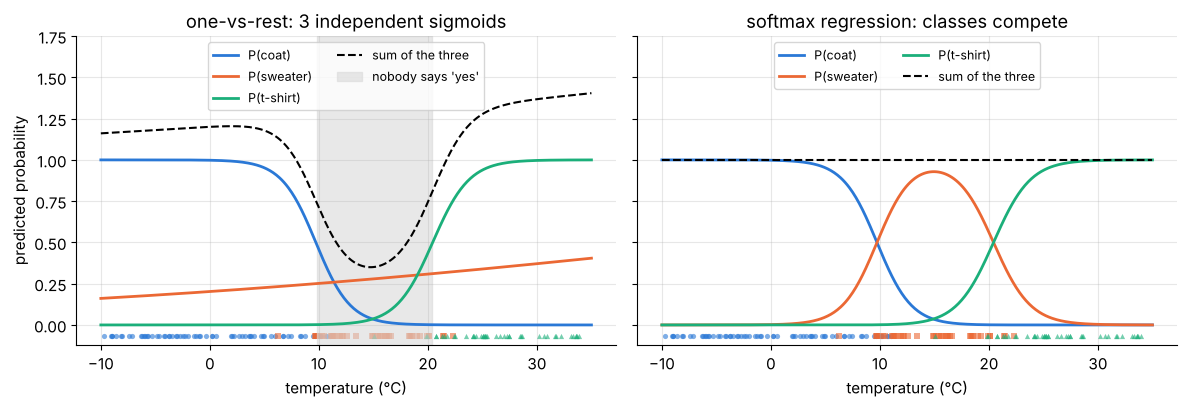

In [3]:
def rug(ax, x, y, y_level=-0.07):
    """Draw the training days as small class-coloured markers just below the curves."""
    for k in range(3):
        ax.scatter(x[y == k] * 10, np.full((y == k).sum(), y_level), s=14, marker=CLASS_MARKERS[k],
                   color=CLASS_COLORS[k], alpha=0.6, linewidths=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, P, title in [(axes[0], P_ovr, "one-vs-rest: 3 independent sigmoids"),
                     (axes[1], P_soft, "softmax regression: classes compete")]:
    for k in range(3):
        ax.plot(x_grid[:, 0] * 10, P[:, k], color=CLASS_COLORS[k], lw=2, label=f"P({CLASS_NAMES[k]})")
    ax.plot(x_grid[:, 0] * 10, P.sum(axis=1), "k--", lw=1.5, label="sum of the three")
    rug(ax, x_days, y_days)
    ax.set_title(title)
    ax.set_xlabel("temperature (°C)")
axes[0].axvspan(x_grid[no_yes, 0].min() * 10, x_grid[no_yes, 0].max() * 10, color="0.85", alpha=0.6,
                label="nobody says 'yes'")
axes[0].set_ylabel("predicted probability")
axes[0].set_ylim(-0.12, 1.75)
axes[0].legend(loc="upper center", fontsize=9, ncol=2)
axes[1].legend(loc="upper center", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

Three problems are visible at once:

1. **The "probabilities" do not sum to 1.** The sum swings from 0.35 at 15 °C to 1.40 at 35 °C.
   Each classifier was trained alone, so nothing forces them to agree.
2. **Thresholded decisions are inconsistent.** Between about 10 °C and 20 °C *no* classifier
   says "yes" (all three are below 0.5). With other data you can just as easily get regions
   where two classifiers say "yes". Taking the arg max hides the problem, but the numbers behind
   the decision remain meaningless.
3. **The middle class is "masked".** The sweater detector is $\sigma(w x + b)$, and a sigmoid of
   a linear function of one variable is *monotone* in $x$: it can say "the warmer, the more
   sweater" or "the colder, the more sweater", but never "medium temperatures mean sweater".
   Here it ends up claiming that a sweater is *most* likely at 35 °C (0.40), while at 15 °C, a
   typical sweater day, it only gives 0.28.

The softmax model on the right fixes all three: its curves always sum to exactly 1, and the
sweater probability rises to 0.93 at 15 °C and falls off on both sides. The reason is that the
three scores are trained *together* and compete for a fixed budget of probability.

> **Key idea.** In a multi-class problem the classes compete: evidence *for* one class is evidence
> *against* the others. A good model should build this competition in, instead of asking $K$
> independent questions.

> **Going deeper.** One-vs-rest is not useless. With rich nonlinear features it can work well
> (scikit-learn's `OneVsRestClassifier` also rescales the $K$ outputs so they sum to 1, which fixes
> problem 1 but not problem 3). And for **multi-label** problems, where an example may genuinely
> belong to several classes, independent sigmoids are exactly the right model.

### 1.4 A wish list for a multi-class model

We want a model that
1. computes **one score** $z_k$ per class (we keep the linear scores of logistic regression:
   $z_k = \mathbf w_k^\top\mathbf x + b_k$).
2. turns the scores into **positive** numbers $p_k > 0$ ...
3. ... that **sum to one**, $\sum_k p_k = 1$, so they form a probability distribution.
4. is **order-preserving**: a larger score always means a larger probability.
5. is **smooth** (differentiable), so we can train it with gradient descent.
6. reduces to ordinary **logistic regression when $K = 2$**.

The softmax function checks every box. Let us meet it.

## 2. The softmax function

### 2.1 Definition and a worked example

Given a vector of $K$ logits $\mathbf z = (z_0, \dots, z_{K-1})$, the softmax function returns the vector
$\mathbf p = \operatorname{softmax}(\mathbf z)$ with components

$$
p_k \;=\; \operatorname{softmax}(\mathbf z)_k \;=\; \frac{e^{z_k}}{\sum_{j=0}^{K-1} e^{z_j}},\qquad k = 0, \dots, K-1 .
$$

It works in two steps:
1. **exponentiate** every logit: this makes every number positive, whatever the sign of $z_k$.
2. **normalize**: divide by the total, so the numbers sum to 1.

> **Intuition.** Think of a raffle. Class $k$ buys $e^{z_k}$ tickets, and its probability of
> winning is its share of all tickets sold. Raising a score by 1 multiplies that class's tickets
> by $e \approx 2.718$. Every class always holds *some* tickets (so $p_k > 0$), and the shares
> of all classes add up to 100%.

**Worked example.** Suppose that for a 26 °C day the wardrobe model produces the logits
$\mathbf z = (-1.2,\ 0.9,\ 1.6)$ for (coat, sweater, t-shirt).

| class | logit $z_k$ | $e^{z_k}$ | $p_k = e^{z_k} / 7.7138$ |
|---|---|---|---|
| coat | $-1.2$ | $0.3012$ | $0.0390$ |
| sweater | $0.9$ | $2.4596$ | $0.3189$ |
| t-shirt | $1.6$ | $4.9530$ | $0.6421$ |
| **sum** | | $7.7138$ | $1.0000$ |

The t-shirt wins with 64%. Notice how the exponential stretches differences: the t-shirt logit is
only $0.7$ above the sweater logit, yet the t-shirt is $e^{0.7} \approx 2.01$ times as likely.

In [4]:
def softmax_naive(z):
    """Textbook softmax of a 1-D array (we will make it numerically safe in Section 2.4)."""
    e = np.exp(z)
    return e / e.sum()

z_day = np.array([-1.2, 0.9, 1.6])          # logits for (coat, sweater, t-shirt) on a 26 °C day
p_day = softmax_naive(z_day)
display(pd.DataFrame({"logit z": z_day, "exp(z)": np.exp(z_day), "p = softmax(z)": p_day},
                     index=CLASS_NAMES).round(4))
print(f"sum of exp(z) = {np.exp(z_day).sum():.4f},   sum of p = {p_day.sum():.4f}")
print(f"p(t-shirt) / p(sweater) = {p_day[2] / p_day[1]:.4f}   vs   exp(1.6 - 0.9) = {np.exp(0.7):.4f}")

,logit z,exp(z),p = softmax(z)
coat,-1.2,0.3012,0.0390
sweater,0.9,2.4596,0.3189
t-shirt,1.6,4.9530,0.6421


sum of exp(z) = 7.7138,   sum of p = 1.0000
p(t-shirt) / p(sweater) = 2.0138   vs   exp(1.6 - 0.9) = 2.0138


### 2.2 Six properties (each with a one-line proof)

**(P1) Positive.** $e^{z_k} > 0$ for every real $z_k$, so $p_k > 0$. Softmax never outputs an
exact 0 or 1: the model is never *completely* certain (in exact arithmetic).

**(P2) Sums to one.** $\displaystyle\sum_k p_k = \frac{\sum_k e^{z_k}}{\sum_j e^{z_j}} = 1$. Together with
(P1): $\mathbf p$ is a probability distribution over the $K$ classes.

**(P3) Order-preserving.** All $p_k$ share the same denominator and $e^t$ is increasing, so
$z_j > z_k \iff p_j > p_k$. In particular $\arg\max_k p_k = \arg\max_k z_k$: **to predict a class
you do not even need to compute the softmax**: the largest logit wins. Moreover, raising one logit
$z_k$ raises $p_k$ and lowers every other $p_j$ (we prove this with derivatives in Section 5).

**(P4) Ratios depend only on differences.**

$$
\frac{p_j}{p_k} = \frac{e^{z_j}}{e^{z_k}} = e^{z_j - z_k}
\qquad\Longleftrightarrow\qquad
\log\frac{p_j}{p_k} = z_j - z_k .
$$

The difference of two logits is the log-odds between those two classes, the same meaning a single
logit has in logistic regression.

**(P5) Shift invariance.** Adding the same constant $c$ to every logit changes nothing:

$$
\operatorname{softmax}(\mathbf z + c\mathbf 1)_k = \frac{e^{z_k+c}}{\sum_j e^{z_j+c}}
= \frac{e^{c}\,e^{z_k}}{e^{c}\sum_j e^{z_j}} = \operatorname{softmax}(\mathbf z)_k .
$$

Only *differences* between logits matter (as P4 already suggested). This innocent-looking fact has
two big consequences: a numerically safe implementation (Section 2.4) and the non-uniqueness of the
model's parameters (Section 3.3).

**(P6) Not scale invariant: temperature.** Multiplying the logits by a constant *does* change the
result. It is customary to write $\operatorname{softmax}(\mathbf z / T)$ with a **temperature** $T>0$:

- $T \to 0^+$: the distribution becomes **one-hot** on the largest logit (if it is unique), because
  $p_k = 1 \big/ \sum_j e^{(z_j - z_k)/T}$ and for the largest $z_k$ every exponent with $j\neq k$
  tends to $-\infty$.
- $T = 1$: the ordinary softmax.
- $T \to \infty$: all exponents tend to 0, so the distribution becomes **uniform**, $p_k \to 1/K$.

Lowering $T$ makes the largest probability grow and the smallest shrink (the middle ones can go
either way).

> **Key idea.** Why the name *softmax*? The "hard" function $\operatorname{argmax}$ returns a one-hot
> vector marking the winner. It is not differentiable and says nothing about the runners-up. Softmax is
> a smooth, differentiable "soft arg max" that keeps graded information about every class, and it
> turns into the hard version as $T \to 0$.

A close cousin is the **log-sum-exp** function $\operatorname{LSE}(\mathbf z) = \log\sum_j e^{z_j}$,
a smooth version of $\max$. Since $e^{\max_j z_j} \le \sum_j e^{z_j} \le K\,e^{\max_j z_j}$, taking logs gives

$$
\max_j z_j \;\le\; \operatorname{LSE}(\mathbf z) \;\le\; \max_j z_j + \log K ,
$$

and $T\cdot\operatorname{LSE}(\mathbf z/T) \to \max_j z_j$ as $T \to 0^+$. LSE will appear in the loss,
in its gradient, and in the stable implementation.

In [5]:
# Numerically verify P1-P5 on random logits
z_rand = rng.normal(0, 3, size=6)
p_rand = softmax_naive(z_rand)
print("P1 all positive:          ", bool(np.all(p_rand > 0)))
print("P2 sum to one:            ", np.isclose(p_rand.sum(), 1.0))
print("P3 same order as logits:  ", bool(np.array_equal(np.argsort(z_rand), np.argsort(p_rand))))
print("P4 p0/p1 == exp(z0 - z1): ", np.isclose(p_rand[0] / p_rand[1], np.exp(z_rand[0] - z_rand[1])))
print("P5 shift by c = 123.4:    ", np.allclose(softmax_naive(z_rand + 123.4), p_rand))
print("P6 scale by 2 changes p:  ", not np.allclose(softmax_naive(2 * z_rand), p_rand))

# Temperature on the 26 °C logits
temps = [0.1, 0.25, 0.5, 1, 2, 4, 10]
display(pd.DataFrame([softmax_naive(z_day / T) for T in temps], columns=CLASS_NAMES,
                     index=pd.Index(temps, name="temperature T")).round(4))
print("max(z) =", z_day.max(), "| T*LSE(z/T) for T = 1, 0.5, 0.25, 0.1:",
      [round(float(T * np.log(np.exp(z_day / T).sum())), 4) for T in [1, 0.5, 0.25, 0.1]])

P1 all positive:           True
P2 sum to one:             True
P3 same order as logits:   True
P4 p0/p1 == exp(z0 - z1):  True
P5 shift by c = 123.4:     True
P6 scale by 2 changes p:   True


,coat,sweater,t-shirt
temperature T,,,
0.10,0.0000,0.0009,0.9991
0.25,0.0000,0.0573,0.9427
0.50,0.0030,0.1972,0.7998
1.00,0.0390,0.3189,0.6421
2.00,0.1264,0.3611,0.5125
4.00,0.2126,0.3594,0.4281
10.00,0.2812,0.3468,0.3720


max(z) = 1.6 | T*LSE(z/T) for T = 1, 0.5, 0.25, 0.1: [2.043, 1.7117, 1.6148, 1.6001]


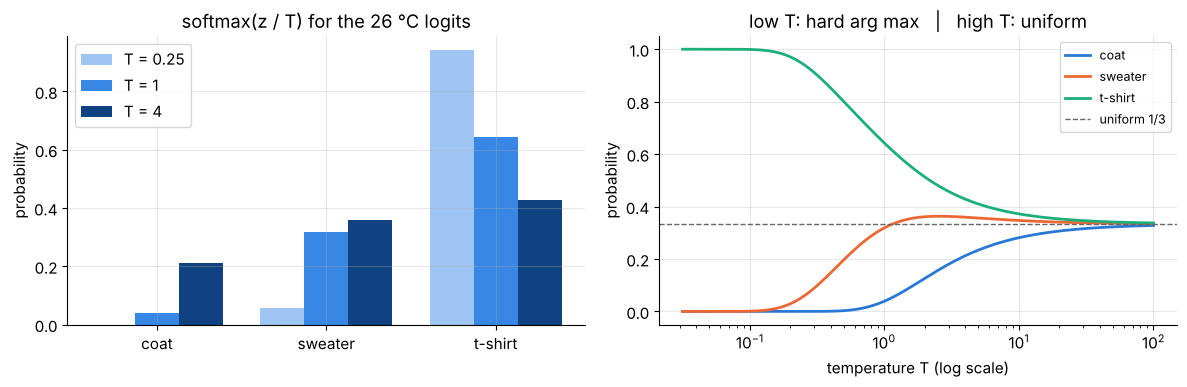

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bar_T = [0.25, 1, 4]
width = 0.26
for i, T in enumerate(bar_T):
    axes[0].bar(np.arange(3) + (i - 1) * width, softmax_naive(z_day / T), width=width,
                color=["#9ec5f4", "#3987e5", "#104281"][i], label=f"T = {T}")
axes[0].set_xticks(range(3), CLASS_NAMES)
axes[0].set_ylabel("probability")
axes[0].set_title("softmax(z / T) for the 26 °C logits")
axes[0].legend()

T_grid = np.logspace(-1.5, 2, 300)
P_T = np.array([softmax_naive(z_day / T) for T in T_grid])
for k in range(3):
    axes[1].plot(T_grid, P_T[:, k], color=CLASS_COLORS[k], lw=2, label=CLASS_NAMES[k])
axes[1].axhline(1 / 3, color="0.4", ls="--", lw=1, label="uniform 1/3")
axes[1].set_xscale("log")
axes[1].set_xlabel("temperature T (log scale)")
axes[1].set_ylabel("probability")
axes[1].set_title("low T: hard arg max   |   high T: uniform")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

### 2.3 Two classes: softmax is the sigmoid in disguise

With $K=2$ classes and logits $(z_0, z_1)$, divide numerator and denominator by $e^{z_1}$:

$$
p_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{e^{z_0 - z_1} + 1} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0),
\qquad p_0 = 1 - p_1 = \sigma(z_0 - z_1).
$$

So a 2-class softmax is exactly a sigmoid applied to the **difference** of the two logits. For softmax
regression, $z_1 - z_0 = (\mathbf w_1 - \mathbf w_0)^\top\mathbf x + (b_1 - b_0)$: it is logistic regression
with weight vector $\mathbf w = \mathbf w_1 - \mathbf w_0$ and bias $b = b_1 - b_0$. Only the difference is
determined by the data, a first glimpse of the non-uniqueness we will study in Section 3.3. This
completes item 6 of our wish list: softmax regression *generalizes* logistic regression rather than
replacing it.

In [7]:
def sigmoid(t):
    return 1.0 / (1.0 + np.exp(-t))

z_pairs = rng.normal(0, 4, size=(5, 2))                 # five random (z0, z1) pairs
p1_softmax = np.array([softmax_naive(zz)[1] for zz in z_pairs])
p1_sigmoid = sigmoid(z_pairs[:, 1] - z_pairs[:, 0])
print("softmax p1:          ", p1_softmax.round(6))
print("sigmoid(z1 - z0):    ", p1_sigmoid.round(6))
print("max abs difference:  ", np.abs(p1_softmax - p1_sigmoid).max())

softmax p1:           [0.0186 0.9986 0.99   0.0496 0.0054]
sigmoid(z1 - z0):     [0.0186 0.9986 0.99   0.0496 0.0054]
max abs difference:   1.1102230246251565e-16


### ✏️ Exercise 1: logistic regression as a 2-class softmax model

A trained logistic regression has weight vector $\mathbf w \in \mathbb R^D$ and bias $b$, and predicts
$P(y=1\mid\mathbf x) = \sigma(\mathbf w^\top\mathbf x + b)$. Write `logistic_to_softmax(w, b)` that returns a
softmax-regression model `(W2, b2)` with `W2.shape == (2, D)` and `b2.shape == (2,)` giving **exactly the
same** probabilities: $\operatorname{softmax}(\mathbf W_2\mathbf x + \mathbf b_2)_1 = \sigma(\mathbf w^\top\mathbf x + b)$
for every $\mathbf x$. (Many answers are correct. The checker accepts all of them.)

In [8]:
# ✏️ Exercise 1
def logistic_to_softmax(w, b):
    """Return (W2, b2) of shape (2, D) and (2,) with softmax(W2 @ x + b2)[1] == sigmoid(w @ x + b)."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex1():
    r = np.random.default_rng(0)
    w, b = r.normal(size=4), 0.7
    W2, b2 = logistic_to_softmax(w, b)
    W2, b2 = np.asarray(W2, dtype=float), np.asarray(b2, dtype=float)
    assert W2.shape == (2, 4) and b2.shape == (2,), f"expected shapes (2, 4) and (2,), got {W2.shape}, {b2.shape}"
    X = r.normal(size=(20, 4))
    p1 = np.array([softmax_naive(W2 @ x + b2)[1] for x in X])
    assert np.allclose(p1, sigmoid(X @ w + b), atol=1e-10), "probabilities differ from the logistic model"

run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def logistic_to_softmax(w, b):
    W2 = np.vstack([np.zeros_like(w), w])   # class 0 gets score 0, class 1 gets w.x + b
    b2 = np.array([0.0, b])
    return W2, b2
```
Since $p_1 = \sigma(z_1 - z_0)$, any pair with $\mathbf w_1 - \mathbf w_0 = \mathbf w$ and $b_1 - b_0 = b$ works.
Fixing class 0 at zero is the simplest. The symmetric choice $\mathbf w_1 = \mathbf w/2,\ \mathbf w_0 = -\mathbf w/2$
(and the same for $b$) is equally valid.
</details>

### 2.4 Computing softmax safely: overflow, underflow and log-softmax

Computers store real numbers as floating-point numbers with a limited range. In the default
`float64`, the largest representable number is about $1.8\times10^{308} \approx e^{709.78}$, so
`np.exp(710)` is already `inf`. In `float32` (the default on GPUs and in PyTorch) the limit is about
$e^{88.72}$. Logits of a few hundred are not unusual in large models, so the textbook formula can break:

In [9]:
z_big = np.array([1000.0, 1002.0, 999.0])
z_small = np.array([-1000.0, -1002.0, -999.0])
# We silence NumPy's overflow/invalid-value warnings on purpose here, to display the broken results.
with np.errstate(over="ignore", invalid="ignore"):
    print("naive softmax(z_big)   =", softmax_naive(z_big), "   <- exp overflows to inf, inf/inf = nan")
    print("naive softmax(z_small) =", softmax_naive(z_small), "   <- exp underflows to 0, 0/0 = nan")
print("np.exp(709.0) =", np.exp(709.0), "| float32 largest exponent ~ ln(3.4e38) =",
      round(float(np.log(np.finfo(np.float32).max)), 2))

naive softmax(z_big)   = [nan nan nan]    <- exp overflows to inf, inf/inf = nan
naive softmax(z_small) = [nan nan nan]    <- exp underflows to 0, 0/0 = nan
np.exp(709.0) = 8.218407461554972e+307 | float32 largest exponent ~ ln(3.4e38) = 88.72


**The fix** uses shift invariance (P5): subtract $m = \max_j z_j$ from every logit before exponentiating.
The result is mathematically identical, but now the largest exponent is $e^0 = 1$: nothing overflows,
and the denominator is at least 1, so there is never a division by zero.

$$
\operatorname{softmax}(\mathbf z)_k = \frac{e^{z_k - m}}{\sum_j e^{z_j - m}},\qquad m = \max_j z_j .
$$

Tiny probabilities can still **underflow** to exactly 0 (e.g. $e^{-800}$). That is harmless for the
probabilities themselves, but fatal if you then take $\log 0 = -\infty$, which is exactly what the loss
does. The cure is to compute the **log-probabilities directly**:

$$
\log p_k = z_k - \operatorname{LSE}(\mathbf z),\qquad
\operatorname{LSE}(\mathbf z) = m + \log\sum_j e^{z_j - m}.
$$

This is **log-softmax**. Every term is computed safely: $z_j - m \le 0$, and the sum inside the log
lies between 1 and $K$.

In [10]:
def softmax(Z):
    """Numerically stable softmax along the last axis (works for one vector or a batch of rows)."""
    Z = np.asarray(Z, dtype=float)
    Z_shift = Z - Z.max(axis=-1, keepdims=True)      # largest entry of each row becomes 0
    E = np.exp(Z_shift)
    return E / E.sum(axis=-1, keepdims=True)

def log_sum_exp(Z):
    """Stable log(sum(exp(Z))) along the last axis."""
    Z = np.asarray(Z, dtype=float)
    m = Z.max(axis=-1, keepdims=True)
    return (m + np.log(np.exp(Z - m).sum(axis=-1, keepdims=True))).squeeze(-1)

def log_softmax(Z):
    """Stable log-probabilities: z_k - LSE(z), along the last axis."""
    Z = np.asarray(Z, dtype=float)
    return Z - log_sum_exp(Z)[..., None]

print("stable softmax(z_big)   =", softmax(z_big))
print("stable softmax(z_small) =", softmax(z_small))
z_far = np.array([800.0, 0.0])
with np.errstate(divide="ignore"):                # log(0) warning silenced on purpose
    print("log(softmax([800, 0])) =", np.log(softmax(z_far)), "  <- p1 = e^-800 underflowed to 0")
print("log_softmax([800, 0])  =", log_softmax(z_far), "  <- exact")

# Agreement with library implementations on a random batch
Z_test = rng.normal(0, 50, size=(4, 5))
print("max |ours - scipy| softmax    :", np.abs(softmax(Z_test) - scipy_softmax(Z_test, axis=1)).max())
print("max |ours - scipy| log_softmax:", np.abs(log_softmax(Z_test) - scipy_log_softmax(Z_test, axis=1)).max())
print("max |ours - torch| log_softmax:",
      np.abs(log_softmax(Z_test) - torch.log_softmax(torch.tensor(Z_test), dim=1).numpy()).max())

stable softmax(z_big)   = [0.1142 0.8438 0.042 ]
stable softmax(z_small) = [0.2595 0.0351 0.7054]
log(softmax([800, 0])) = [  0. -inf]   <- p1 = e^-800 underflowed to 0
log_softmax([800, 0])  = [   0. -800.]   <- exact
max |ours - scipy| softmax    : 0.0
max |ours - scipy| log_softmax: 3.552713678800501e-15
max |ours - torch| log_softmax: 3.552713678800501e-15


> **Common pitfall.** Computing `np.log(softmax(z))` and then "fixing" the `-inf` by clipping
> probabilities to `1e-15` hides the bug instead of solving it: the loss is capped at about 34.5 no
> matter how wrong the model is. Use log-softmax (or a library loss that takes logits) instead.

> **Olympiad tip.** Whenever you see $\log\sum e^{(\cdot)}$ or a ratio of exponentials in code, ask
> "what is the largest exponent?" and factor it out. The same trick appears in attention layers,
> in the forward algorithm for hidden Markov models, and in many probability computations.

### ✏️ Exercise 2: a stable row-wise softmax

Implement `softmax_rows(Z)` for a 2-D array `Z` of shape `(N, K)`: return the softmax of **each row**,
without overflow or `nan` even for logits like $\pm 10^4$. Do not call `softmax`, `scipy` or `torch`.

In [11]:
# ✏️ Exercise 2
def softmax_rows(Z):
    """Row-wise, numerically stable softmax of a 2-D array Z of shape (N, K)."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex2():
    Z = np.array([[1.0, 2.0, 3.0], [1e4, 0.0, -1e4], [-1e4, -1e4 - 1, -1e4 - 2], [5.0, 5.0, 5.0]])
    P = np.asarray(softmax_rows(Z))
    assert P.shape == Z.shape, f"shape should be {Z.shape}, got {P.shape}"
    assert np.all(np.isfinite(P)), "output contains inf or nan: subtract the row maximum first"
    assert np.allclose(P.sum(axis=1), 1.0), "each row must sum to 1"
    assert np.allclose(P, scipy_softmax(Z, axis=1), atol=1e-12), "values differ from the reference softmax"
    assert np.allclose(softmax_rows(Z[:2] + 7.5), P[:2]), "adding a constant to a row must not change it"

run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def softmax_rows(Z):
    Z = np.asarray(Z, dtype=float)
    E = np.exp(Z - Z.max(axis=1, keepdims=True))   # largest entry per row -> exp(0) = 1
    return E / E.sum(axis=1, keepdims=True)
```
`keepdims=True` keeps the row maxima and sums as a column of shape `(N, 1)`, so broadcasting subtracts
and divides row by row.
</details>

### ✏️ Exercise 3: log-softmax without `log(softmax)`

Implement `log_softmax_rows(Z)` (shape `(N, K)` in, `(N, K)` out) using the log-sum-exp trick.
It must stay finite and exact for extreme logits such as `[[0, -1000]]`, where the answer is `[[0, -1000]]`.

In [12]:
# ✏️ Exercise 3
def log_softmax_rows(Z):
    """Row-wise log-softmax of a 2-D array Z of shape (N, K), computed stably."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex3():
    Z = np.array([[0.0, -1000.0], [1000.0, 0.0], [3.0, 1.0]])
    out = np.asarray(log_softmax_rows(Z))
    assert out.shape == Z.shape, f"shape should be {Z.shape}, got {out.shape}"
    assert np.all(np.isfinite(out)), "output must be finite: do not take the log of a softmax that underflowed"
    assert np.allclose(out, scipy_log_softmax(Z, axis=1)), f"got {out}"
    Zr = np.random.default_rng(1).normal(0, 30, size=(6, 4))
    assert np.allclose(np.exp(log_softmax_rows(Zr)).sum(axis=1), 1.0), "exp(log-probs) must sum to 1 per row"

run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def log_softmax_rows(Z):
    Z = np.asarray(Z, dtype=float)
    m = Z.max(axis=1, keepdims=True)
    lse = m + np.log(np.exp(Z - m).sum(axis=1, keepdims=True))   # log-sum-exp per row, shape (N, 1)
    return Z - lse
```
The sum inside the log is between 1 and $K$, so the log never sees 0 and nothing overflows.
</details>

**Quick check.**
1. What does softmax return for the logits $(2, 2, 2, 2)$?
2. You multiply all logits by 2. What happens to the largest probability? To the smallest?
3. Can softmax output exactly 0? Can it output exactly 1?

<details>
<summary>Answer</summary>

1. $(0.25, 0.25, 0.25, 0.25)$: equal logits mean equal shares (any common value gives the same result, by P5).
2. Doubling the logits is temperature $T = 1/2$: the largest probability increases and the smallest
   decreases (unless all logits are equal, in which case nothing changes).
3. In exact math, no and no (P1, P2: every $p_k$ is strictly between 0 and 1 when $K\ge2$). In floating
   point, yes: $e^{-800}$ underflows to 0, and then the winner gets exactly 1.0, which is why we work
   with log-probabilities.
</details>

## 3. The softmax regression model

### 3.1 From features to logits to probabilities

Softmax regression gives every class its own linear scoring rule: picture a panel of $K$ judges,
each with a personal weight vector $\mathbf w_k$ and bias $b_k$:

$$
z_k = \mathbf w_k^\top \mathbf x + b_k \quad (k = 0,\dots,K-1)
\qquad\Longleftrightarrow\qquad
\underbrace{\mathbf z}_{K\times 1} = \underbrace{\mathbf W}_{K\times D}\,\underbrace{\mathbf x}_{D\times 1} + \underbrace{\mathbf b}_{K\times 1},
\qquad
\mathbf p = \operatorname{softmax}(\mathbf z).
$$

The prediction is the class with the largest probability, which by (P3) is simply the class with the
largest logit: $\hat y = \arg\max_k p_k = \arg\max_k z_k$. The model has $K(D+1)$ parameters, for the
$8\times 8$ digit images of Section 8 ($D = 64$, $K = 10$) that is $10 \times 65 = 650$.

**Batch form.** In code we process many samples at once. Stack the samples as the **rows** of
$\mathbf X \in \mathbb R^{N\times D}$. Transposing $\mathbf z_i = \mathbf W\mathbf x_i + \mathbf b$ gives
$\mathbf z_i^\top = \mathbf x_i^\top\mathbf W^\top + \mathbf b^\top$, so all logits at once are

$$
\mathbf Z = \mathbf X\mathbf W^\top + \mathbf 1_N\mathbf b^\top \in \mathbb R^{N\times K},\qquad
\mathbf P = \operatorname{softmax}(\mathbf Z) \text{ applied to each row.}
$$

```
       X            W^T          b^T                Z
    (N x D)   @   (D x K)   +  (1 x K)      =    (N x K)      row i = logits of sample i
                                ^ broadcast to every row        column k = scores of class k
```

In NumPy this is literally `X @ W.T + b` (broadcasting adds `b` to every row).

In [13]:
def predict_proba(X, W, b):
    """Class probabilities P (N x K) for samples X (N x D), weights W (K x D), biases b (K,)."""
    return softmax(X @ W.T + b)

def predict(X, W, b):
    """Predicted class labels (N,): the arg max of the logits (no softmax needed)."""
    return np.argmax(X @ W.T + b, axis=1)

# A hand-made wardrobe model: one feature (x = temperature / 10), K = 3 classes, so W is 3 x 1
W_hand = np.array([[-2.0], [0.0], [2.0]])     # coat likes cold, sweater is neutral, t-shirt likes heat
b_hand = np.array([1.5, 0.0, -5.0])
temps_c = np.array([-5, 5, 15, 20, 30])
X_temps = (temps_c / 10)[:, None]              # shape (5, 1)
Z_temps = X_temps @ W_hand.T + b_hand          # shape (5, 3)
P_temps = predict_proba(X_temps, W_hand, b_hand)
table = pd.DataFrame(np.hstack([Z_temps, P_temps]), index=pd.Index(temps_c, name="temp °C"),
                     columns=[f"z_{c}" for c in CLASS_NAMES] + [f"p_{c}" for c in CLASS_NAMES]).round(3)
table["prediction"] = [CLASS_NAMES[k] for k in predict(X_temps, W_hand, b_hand)]
print("shapes: X", X_temps.shape, "| W", W_hand.shape, "| b", b_hand.shape, "| Z", Z_temps.shape)
display(table)

shapes: X (5, 1) | W (3, 1) | b (3,) | Z (5, 3)


,z_coat,z_sweater,z_t-shirt,p_coat,p_sweater,p_t-shirt,prediction
temp °C,,,,,,,
-5,2.5,0.0,-6.0,0.924,0.076,0.000,coat
5,0.5,0.0,-4.0,0.618,0.375,0.007,coat
15,-1.5,0.0,-2.0,0.164,0.736,0.100,sweater
20,-2.5,0.0,-1.0,0.057,0.690,0.254,sweater
30,-4.5,0.0,1.0,0.003,0.268,0.729,t-shirt


### 3.2 The geometry of decision regions

Class $k$ wins at $\mathbf x$ when its logit beats every other logit. Each comparison is a **linear**
inequality:

$$
z_k(\mathbf x) \ge z_j(\mathbf x)
\iff (\mathbf w_k - \mathbf w_j)^\top\mathbf x + (b_k - b_j) \ge 0 ,
$$

which describes a **half-space** (a half-line in 1-D, a half-plane in 2-D). So the decision region of
class $k$,

$$
R_k = \bigcap_{j\neq k}\{\mathbf x : (\mathbf w_k - \mathbf w_j)^\top\mathbf x + (b_k - b_j) \ge 0\},
$$

is an intersection of $K-1$ half-spaces, hence a **convex** set (a convex polygon in 2-D, possibly
unbounded or even empty). Consequences:

- the boundary between two neighbouring regions $j$ and $k$ lies on the hyperplane
  $(\mathbf w_j - \mathbf w_k)^\top\mathbf x + (b_j - b_k) = 0$, so the decision boundary is **piecewise linear**.
- not every pairwise hyperplane is a real boundary: where $z_j = z_k$ but a third class beats both,
  that part of the hyperplane is irrelevant.
- in 2-D with $K = 3$, the three pairwise lines (if not parallel) always meet at **one point**: where
  $z_0 = z_1$ and $z_1 = z_2$, automatically $z_0 = z_2$. At that *triple point* all three classes tie
  at $p_k = 1/3$.

The **probabilities** are a smoothed version of the regions. Along the boundary between $j$ and $k$ we
have $p_j = p_k$, and by (P4) $\log(p_j/p_k) = (\mathbf w_j - \mathbf w_k)^\top\mathbf x + (b_j - b_k)$ changes at rate
$\lVert\mathbf w_j - \mathbf w_k\rVert$ as you walk across it. **Large weights mean sharp transitions**:
multiplying all of $\mathbf W$ and $\mathbf b$ by $c$ is the same as temperature $T = 1/c$.

First the 1-D picture for the hand-made wardrobe model. The winner at each temperature is the
highest of three lines (the "upper envelope"):

boundaries: coat|sweater at 7.50 °C, sweater|t-shirt at 25.00 °C, and coat and t-shirt tie at 16.25 °C, but there the sweater beats both


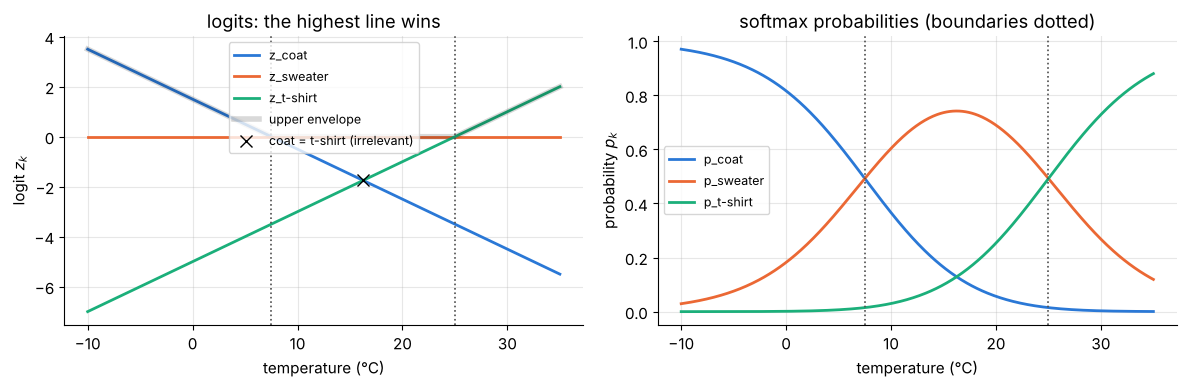

In [14]:
x_line = np.linspace(-1.0, 3.5, 451)[:, None]
Z_line = x_line @ W_hand.T + b_hand
P_line = predict_proba(x_line, W_hand, b_hand)
cut_01 = (b_hand[1] - b_hand[0]) / (W_hand[0, 0] - W_hand[1, 0])   # where z_coat = z_sweater
cut_12 = (b_hand[2] - b_hand[1]) / (W_hand[1, 0] - W_hand[2, 0])   # where z_sweater = z_tshirt
tie_02 = (b_hand[2] - b_hand[0]) / (W_hand[0, 0] - W_hand[2, 0])   # where z_coat = z_tshirt
print(f"boundaries: coat|sweater at {cut_01 * 10:.2f} °C, sweater|t-shirt at {cut_12 * 10:.2f} °C, and "
      f"coat and t-shirt tie at {tie_02 * 10:.2f} °C, but there the sweater beats both")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k in range(3):
    axes[0].plot(x_line[:, 0] * 10, Z_line[:, k], color=CLASS_COLORS[k], lw=2, label=f"z_{CLASS_NAMES[k]}")
    axes[1].plot(x_line[:, 0] * 10, P_line[:, k], color=CLASS_COLORS[k], lw=2, label=f"p_{CLASS_NAMES[k]}")
axes[0].plot(x_line[:, 0] * 10, Z_line.max(axis=1), color="k", lw=4, alpha=0.15, label="upper envelope")
axes[0].plot([tie_02 * 10], [W_hand[0, 0] * tie_02 + b_hand[0]], "kx", ms=9, label="coat = t-shirt (irrelevant)")
for ax, loc in zip(axes, ["upper center", "center left"]):
    for c in (cut_01, cut_12):
        ax.axvline(c * 10, color="0.3", ls=":", lw=1.2)
    ax.set_xlabel("temperature (°C)")
    ax.legend(fontsize=9, loc=loc)
axes[0].set_ylabel("logit $z_k$")
axes[0].set_title("logits: the highest line wins")
axes[1].set_ylabel("probability $p_k$")
axes[1].set_title("softmax probabilities (boundaries dotted)")
plt.tight_layout()
plt.show()

Now a 2-D model with $K = 3$ and hand-picked parameters. Left: the decision regions, the three full
pairwise lines $z_j = z_k$ (dashed, only the solid black parts are real boundaries) and the triple
point (star).
Middle and right: the model's **confidence** $\max_k p_k$ for the parameters $(\mathbf W, \mathbf b)$ and for
$(3\mathbf W, 3\mathbf b)$: same regions, much sharper transitions.

triple point: [0.0795 0.3824] | logits there: [-0.0487 -0.0487 -0.0487] | probabilities: [0.3333 0.3333 0.3333]


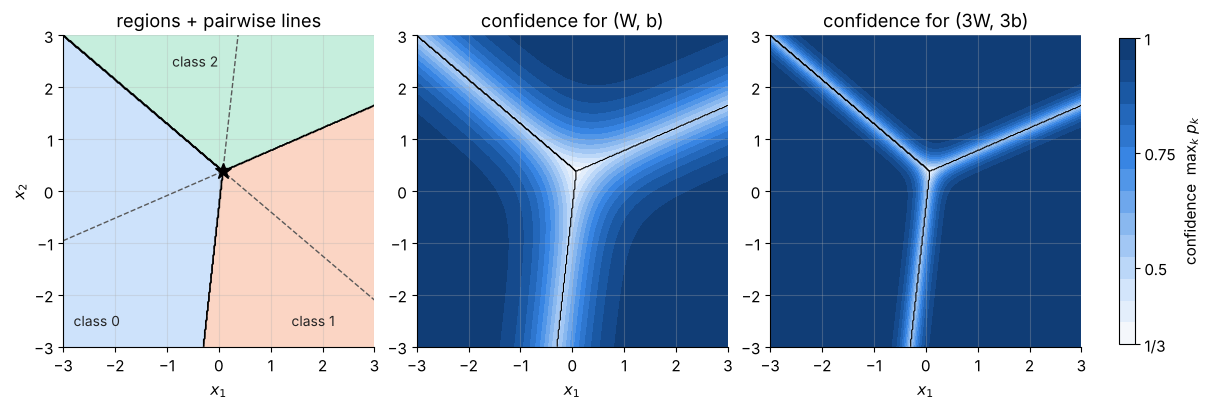

In [15]:
W2d = np.array([[-1.5, -0.6], [1.2, -0.9], [0.2, 1.4]])
b2d = np.array([0.3, 0.2, -0.6])
# triple point: solve z0 = z1 and z1 = z2, i.e. (w0 - w1).x = b1 - b0 and (w1 - w2).x = b2 - b1
A = np.vstack([W2d[0] - W2d[1], W2d[1] - W2d[2]])
x_triple = np.linalg.solve(A, np.array([b2d[1] - b2d[0], b2d[2] - b2d[1]]))
print("triple point:", x_triple.round(4), "| logits there:", (W2d @ x_triple + b2d).round(4),
      "| probabilities:", softmax(W2d @ x_triple + b2d).round(4))

g1, g2 = np.meshgrid(np.linspace(-3, 3, 301), np.linspace(-3, 3, 301))
grid2d = np.column_stack([g1.ravel(), g2.ravel()])
REGION_CMAP = ListedColormap(["#cde2fb", "#fbd5c4", "#c6eedd"])   # light tints of the class colours

def draw_pairwise_lines(ax, W, b):
    """Dashed full lines z_j = z_k for every pair of classes (2-D inputs)."""
    xs = np.linspace(-3, 3, 2)
    for j, k in [(0, 1), (1, 2), (0, 2)]:
        dw, db = W[j] - W[k], b[j] - b[k]            # dw[0]*x1 + dw[1]*x2 + db = 0
        if abs(dw[1]) > 1e-12:
            ax.plot(xs, -(dw[0] * xs + db) / dw[1], "--", color="0.35", lw=1)
        else:
            ax.axvline(-db / dw[0], ls="--", color="0.35", lw=1)

labels2d = predict(grid2d, W2d, b2d).reshape(g1.shape)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.1), constrained_layout=True)
axes[0].contourf(g1, g2, labels2d, levels=[-0.5, 0.5, 1.5, 2.5], cmap=REGION_CMAP)
draw_pairwise_lines(axes[0], W2d, b2d)
axes[0].contour(g1, g2, labels2d, levels=[0.5, 1.5], colors="k", linewidths=1.2)
axes[0].plot(*x_triple, "k*", ms=12)
for k, pos in enumerate([(-2.8, -2.6), (1.4, -2.6), (-0.9, 2.4)]):
    axes[0].text(*pos, f"class {k}", fontsize=10, color="0.15")
axes[0].set_title("regions + pairwise lines")
for ax, scale in [(axes[1], 1), (axes[2], 3)]:
    conf = predict_proba(grid2d, scale * W2d, scale * b2d).max(axis=1).reshape(g1.shape)
    im = ax.contourf(g1, g2, conf, levels=np.linspace(1 / 3, 1, 15), cmap=SEQ_CMAP)
    ax.contour(g1, g2, labels2d, levels=[0.5, 1.5], colors="k", linewidths=0.8)
    ax.set_title("confidence for (W, b)" if scale == 1 else f"confidence for ({scale}W, {scale}b)")
cbar = fig.colorbar(im, ax=axes[1:], shrink=0.85, label="confidence  max$_k$ $p_k$")
cbar.set_ticks([1 / 3, 0.5, 0.75, 1.0], labels=["1/3", "0.5", "0.75", "1"])
for ax in axes:
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
plt.show()

Notice that the confidence is lowest (exactly $1/3$) at the triple point and close to $1/2$ along the
boundaries, where two classes share the probability. Scaling the parameters does not move a single
boundary. It only changes how quickly the model becomes sure of itself.

### ✏️ Exercise 4: who wins where? (1-D decision regions)

For a 1-D model with $K$ classes, logit $k$ is a line $z_k(x) = w_k x + b_k$ and the winner is the
highest line. Write `regions_1d(w, b)` that returns `(order, cuts)`:
- `order`: the classes that win *somewhere*, listed from left ($x\to-\infty$) to right ($x\to+\infty$).
- `cuts`: the `len(order) - 1` increasing positions where the winner changes.

For the hand-made wardrobe model, `regions_1d([-2, 0, 2], [1.5, 0, -5])` should give `([0, 1, 2], [0.75, 2.5])`.
Hints: at $x \to -\infty$ the line with the **smallest slope** wins. From the current winner $k$, the next
winner is the line with a larger slope that crosses line $k$ first (smallest crossing point to the right).
You may assume no two slopes are equal.

In [16]:
# ✏️ Exercise 4
def regions_1d(w, b):
    """Return (order, cuts) describing which class wins on which interval of the real line."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex4():
    order, cuts = regions_1d([-2.0, 0.0, 2.0], [1.5, 0.0, -5.0])
    assert list(order) == [0, 1, 2] and np.allclose(cuts, [0.75, 2.5]), f"got {order}, {cuts}"
    order, cuts = regions_1d([-2.0, 0.0, 2.0], [1.5, -3.0, -5.0])     # the sweater never wins here
    assert list(order) == [0, 2] and np.allclose(cuts, [1.625]), f"masked middle class: got {order}, {cuts}"
    r = np.random.default_rng(3)
    for _ in range(100):                                              # compare with brute force
        K = int(r.integers(2, 7))
        w, b = r.normal(size=K), 3 * r.normal(size=K)
        order, cuts = regions_1d(w, b)
        cuts = np.asarray(cuts, dtype=float)
        assert len(order) == len(cuts) + 1, "need exactly one cut between consecutive winners"
        assert np.all(np.diff(cuts) > 0), "cuts must be increasing"
        edges = np.concatenate([[-1e6], cuts, [1e6]])
        for x_mid, k in zip((edges[:-1] + edges[1:]) / 2, order):
            assert np.argmax(w * x_mid + b) == k, f"class {k} does not win at x = {x_mid:.3f}"

run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def regions_1d(w, b):
    w, b = np.asarray(w, dtype=float), np.asarray(b, dtype=float)
    k = int(np.argmin(w))                    # winner far to the left: smallest slope
    order, cuts, x_prev = [k], [], -np.inf
    while True:
        best_x, best_j = np.inf, None
        for j in range(len(w)):
            if w[j] > w[k]:                  # only a steeper line can overtake line k to the right
                x_cross = (b[k] - b[j]) / (w[j] - w[k])
                if x_cross >= x_prev and x_cross < best_x:
                    best_x, best_j = x_cross, j
        if best_j is None:                   # nobody overtakes: k wins all the way to +infinity
            return order, cuts
        order.append(best_j); cuts.append(best_x)
        k, x_prev = best_j, best_x
```
The winners form the *upper envelope* of the lines, and slopes increase from left to right along it.
Competitive programmers know this structure as the "convex hull trick". A class whose line never reaches
the envelope (the masked sweater in the second test) gets an empty region.
</details>

### 3.3 The parameters are not unique (over-parameterization)

Take any vector $\mathbf v \in \mathbb R^D$ and number $c$, and add them to **every** class:
$\mathbf w_k \to \mathbf w_k + \mathbf v$, $b_k \to b_k + c$. Every logit changes by the same amount
$\mathbf v^\top\mathbf x + c$, so by shift invariance (P5) **every probability stays exactly the same**:

$$
\operatorname{softmax}\big((\mathbf W + \mathbf 1\mathbf v^\top)\mathbf x + \mathbf b + c\mathbf 1\big) = \operatorname{softmax}(\mathbf W\mathbf x + \mathbf b)
\quad\text{for every } \mathbf x .
$$

So infinitely many parameter settings describe the same model: the parameters are **not
identifiable**. Only the differences $\mathbf w_j - \mathbf w_k$, $b_j - b_k$ matter (as we saw for $K=2$).
The model really has $(K-1)(D+1)$ "useful" parameters, not $K(D+1)$. Three standard ways to pick one
representative:

1. **Reference class:** subtract the last row from every row, so that $\mathbf w_{K-1} = \mathbf 0$ and $b_{K-1} = 0$.
   For $K = 2$ this is exactly logistic regression (Exercise 1). Statistics software often reports this form.
2. **Zero-sum:** subtract the mean row, so that $\sum_k \mathbf w_k = \mathbf 0$ and $\sum_k b_k = 0$.
3. **L2 regularization** (Sections 5 and 6) adds $\frac{\lambda}{2}\lVert\mathbf W\rVert^2$ to the loss. Since
   $\lVert\mathbf W + \mathbf 1\mathbf v^\top\rVert^2$ is smallest at $\mathbf v = -\frac1K\sum_k\mathbf w_k$, the
   penalty automatically selects the **zero-sum** weights, $\sum_k\mathbf w_k = \mathbf 0$. The biases are usually not
   penalized, so they stay free up to a common shift $b_k \to b_k + c$.

Plain gradient descent does not care either way, but as we will prove in Section 5.6, it never moves
along these "do-nothing" directions.

In [17]:
W_r = rng.normal(size=(3, 4))
b_r = rng.normal(size=3)
X_r = rng.normal(size=(5, 4))
v, c = rng.normal(size=4), 2.5
P_orig = predict_proba(X_r, W_r, b_r)
variants = {
    "original": (W_r, b_r),
    "add v to every row, c to every bias": (W_r + v, b_r + c),
    "reference class (last row = 0)": (W_r - W_r[-1], b_r - b_r[-1]),
    "zero-sum (subtract mean row)": (W_r - W_r.mean(axis=0), b_r - b_r.mean()),
}
rows = []
for name, (Wv, bv) in variants.items():
    rows.append([name, f"{np.abs(predict_proba(X_r, Wv, bv) - P_orig).max():.1e}", round(np.linalg.norm(Wv), 4)])
display(pd.DataFrame(rows, columns=["parameters", "max |P - P_original|", "||W|| (Frobenius)"]))

,parameters,max |P - P_original|,||W|| (Frobenius)
0,original,0.0e+00,4.0153
1,"add v to every row, c to every bias",1.1e-16,4.6721
2,reference class (last row = 0),1.1e-16,5.9682
3,zero-sum (subtract mean row),1.1e-16,3.7787


All four parameter sets give the same probabilities (differences around $10^{-16}$ are rounding errors),
and the zero-sum version has the smallest norm, as claimed.

### ✏️ Exercise 5: the reference-class form

Write `to_reference_class(W, b)` that returns an equivalent model `(W_ref, b_ref)` (same probabilities
for every input) whose **last** class has zero weights and zero bias.

In [18]:
# ✏️ Exercise 5
def to_reference_class(W, b):
    """Equivalent parameters with W_ref[-1] == 0 and b_ref[-1] == 0."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex5():
    r = np.random.default_rng(5)
    W, b = r.normal(size=(4, 3)), r.normal(size=4)
    W_ref, b_ref = to_reference_class(W, b)
    W_ref, b_ref = np.asarray(W_ref), np.asarray(b_ref)
    assert W_ref.shape == W.shape and b_ref.shape == b.shape, "shapes must not change"
    assert np.allclose(W_ref[-1], 0) and np.isclose(b_ref[-1], 0), "the last class must have zero parameters"
    X = r.normal(size=(10, 3))
    assert np.allclose(predict_proba(X, W_ref, b_ref), predict_proba(X, W, b)), "probabilities changed"
    assert np.allclose(W[-1], np.random.default_rng(5).normal(size=(4, 3))[-1]), "do not modify W in place"

run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def to_reference_class(W, b):
    return W - W[-1], b - b[-1]      # broadcasting subtracts the last row from every row
```
This adds $\mathbf v = -\mathbf w_{K-1}$ to every weight vector and $c = -b_{K-1}$ to every bias, which
changes no probability (Section 3.3). Using `W - W[-1]` creates a new array, so the caller's `W` is untouched.
</details>

## 4. The loss: categorical cross-entropy

### 4.1 One-hot targets

The model outputs a probability *vector*, so it is convenient to write the label as a vector too.
The **one-hot** encoding of label $y$ is the length-$K$ vector $\mathbf y$ with $y_k = 1$ if $k = y$ and
$0$ otherwise. For the wardrobe, sweater $= 1 \mapsto (0, 1, 0)$. You can read $\mathbf y$ as the
"perfectly certain" probability distribution that puts all its mass on the true class. One-hot
vectors let us write per-class formulas as sums: e.g. $\sum_k y_k\, a_k = a_y$ picks out the
entry of the true class.

> **Common pitfall.** Never feed class numbers $0, 1, 2$ into a model as if they were *quantities*
> (as in "t-shirt = 2 × sweater"). Class labels are names. One-hot vectors treat all classes symmetrically.

In [19]:
def one_hot(y, K):
    """One-hot matrix (N x K) for integer labels y (N,)."""
    return np.eye(K)[np.asarray(y)]

y_example = np.array([2, 0, 1, 1])
print("labels:", y_example)
print(one_hot(y_example, 3))

labels: [2 0 1 1]
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]]


### 4.2 From maximum likelihood to cross-entropy

The model claims $P(y = k \mid \mathbf x) = p_k$: a **categorical distribution** over the $K$ classes
(a $K$-sided loaded die). The probability it assigns to the label we actually observed can be written
with the one-hot vector as

$$
P(y_i \mid \mathbf x_i) \;=\; p_{i,y_i} \;=\; \prod_{k=0}^{K-1} p_{ik}^{\,y_{ik}}
\qquad(\text{all factors are } p^0 = 1 \text{ except the true class}).
$$

Treating the samples as independent, the **likelihood** of the whole training set is the product
$\prod_i p_{i,y_i}$. *Maximum likelihood* says: choose $\mathbf W, \mathbf b$ to make the observed labels as
probable as possible. Taking $-\frac1N\log$ of the likelihood turns this into the equivalent
**minimization** problem

$$
\mathcal L(\mathbf W, \mathbf b) \;=\; -\frac1N\sum_{i=1}^{N}\log p_{i,y_i}
\;=\; -\frac1N\sum_{i=1}^{N}\sum_{k=0}^{K-1} y_{ik}\log p_{ik} .
$$

The inner sum $H(\mathbf y, \mathbf p) = -\sum_k y_k \log p_k$ is the **cross-entropy** between the target
distribution $\mathbf y$ and the prediction $\mathbf p$, hence the name *categorical cross-entropy*.
For $K = 2$ it is exactly the binary cross-entropy of logistic regression.

**Why the logarithm?**
1. *Products become sums.* $0.9^{1000} \approx 1.7\times10^{-46}$, and with a million samples the likelihood
   underflows to 0 in floating point. The log-likelihood is a perfectly ordinary sum.
2. *Same optimum.* $\log$ is increasing, so maximizing the likelihood and the log-likelihood are equivalent.
   the minus sign and the $\frac1N$ just turn it into an average "cost" to minimize.
3. *The right penalties.* $-\log p$ is nearly 0 for a confident correct answer, about 0.7 for a coin flip
   ($p = 0.5$), and grows without bound as the true class's probability goes to 0. A confident mistake is
   punished hard.
4. *A beautiful gradient.* Combined with softmax it yields $\partial\mathcal L/\partial\mathbf z = \mathbf p - \mathbf y$ (Section 5).

**Why only the probability of the correct class?** The other classes are not ignored: because the
probabilities sum to one, the only way to raise $p_{y}$ is to take probability away from the wrong classes.

> **Going deeper.** Cross-entropy is a *proper scoring rule*: if at some input the true class
> frequencies are $\mathbf q$, the expected loss of predicting $\mathbf p$ is
> $-\sum_k q_k\log p_k = H(\mathbf q) + \mathrm{KL}(\mathbf q\,\Vert\,\mathbf p)$, where the Kullback–Leibler divergence
> $\mathrm{KL} \ge 0$ vanishes only when $\mathbf p = \mathbf q$. So the loss is minimized by predicting the
> *honest* probabilities, not by exaggerating, the basis for the calibration discussion in Section 9.

,p_y (probability of the true class),loss = -ln(p_y)
0,0.99,0.0101
1,0.9,0.1054
2,0.5,0.6931
3,0.3333,1.0986
4,0.1,2.3026
5,0.01,4.6052
6,1e-06,13.8155


confident and right  p = [0.05, 0.15, 0.8]  ->  loss = -ln(0.8) = 0.2231
unsure               p = [0.3, 0.4, 0.3]  ->  loss = -ln(0.3) = 1.2040
confident and wrong  p = [0.7, 0.29, 0.01]  ->  loss = -ln(0.01) = 4.6052


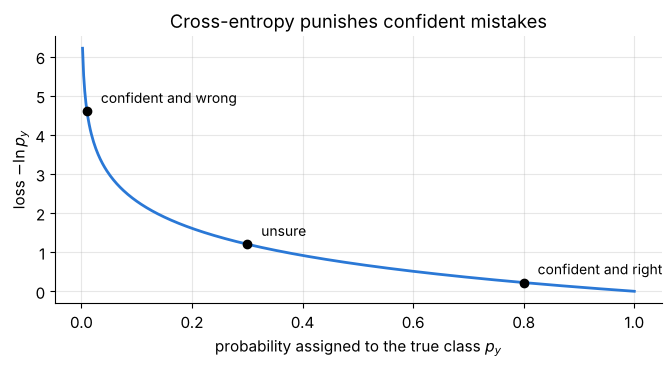

In [20]:
p_values = np.array([0.99, 0.9, 0.5, 1 / 3, 0.1, 0.01, 1e-6])
display(pd.DataFrame({"p_y (probability of the true class)": [f"{p:.4g}" for p in p_values],
                      "loss = -ln(p_y)": (-np.log(p_values)).round(4)}))

# Three predictions for the same t-shirt day (true class y = 2)
preds = {"confident and right": [0.05, 0.15, 0.80], "unsure": [0.30, 0.40, 0.30],
         "confident and wrong": [0.70, 0.29, 0.01]}
for name, p in preds.items():
    print(f"{name:20s} p = {p}  ->  loss = -ln({p[2]}) = {-np.log(p[2]):.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
pp = np.linspace(0.002, 1, 500)
ax.plot(pp, -np.log(pp), color=CLASS_COLORS[0], lw=2)
for p_true, (name, p) in zip([0.80, 0.30, 0.01], preds.items()):
    ax.plot(p_true, -np.log(p_true), "o", color="k", ms=6)
    ax.annotate(name, (p_true, -np.log(p_true)), textcoords="offset points", xytext=(10, 6), fontsize=10)
ax.set_xlabel("probability assigned to the true class $p_y$")
ax.set_ylabel("loss $-\\ln p_y$")
ax.set_title("Cross-entropy punishes confident mistakes")
plt.tight_layout()
plt.show()

### 4.3 Two baselines every model must beat

* **The know-nothing model.** With $\mathbf W = \mathbf 0, \mathbf b = \mathbf 0$ all logits are 0, every
  $p_k = 1/K$, and the loss is $-\log(1/K) = \log K$: $\log 3 \approx 1.0986$ for the wardrobe,
  $\log 10 \approx 2.3026$ for digits. A freshly initialized model that shows a very different loss
  usually has a bug (wrong labels, a forgotten softmax, a sum instead of a mean, ...).
* **The class-frequency model.** The best prediction that ignores $\mathbf x$ is the vector of class
  frequencies $\boldsymbol\pi$ (the proportion of each class in the training set), with loss
  $-\sum_k \pi_k \log\pi_k$, the **entropy** of the labels. A useful model must do better than this.

In [21]:
freq = np.bincount(y_days) / len(y_days)
print(f"wardrobe data: log K = {np.log(3):.4f}. Class frequencies {freq.round(4)} -> "
      f"entropy = {-(freq * np.log(freq)).sum():.4f}")
P_fit = softmax_model.predict_proba(x_days[:, None])
print(f"loss of the fitted softmax model (Section 1.3 preview) on the same days: "
      f"{-np.mean(np.log(P_fit[np.arange(len(y_days)), y_days])):.4f}")

wardrobe data: log K = 1.0986. Class frequencies [0.44   0.2667 0.2933] -> entropy = 1.0735
loss of the fitted softmax model (Section 1.3 preview) on the same days: 0.2278


### 4.4 Cross-entropy straight from the logits

Combining the loss with log-softmax gives a formula that never computes $\mathbf p$ at all:

$$
\ell(\mathbf z, y) = -\log p_y = -\big(z_y - \operatorname{LSE}(\mathbf z)\big) = \operatorname{LSE}(\mathbf z) - z_y .
$$

It is exact and stable for any logits, which is why libraries implement cross-entropy as a function of
**logits**. PyTorch's `nn.CrossEntropyLoss` (and `F.cross_entropy`) takes raw logits and integer labels
and applies log-softmax internally.

In [22]:
def cross_entropy(Z, y):
    """Mean categorical cross-entropy from logits Z (N x K) and integer labels y (N,)."""
    Z = np.atleast_2d(Z)
    return -np.mean(log_softmax(Z)[np.arange(len(Z)), y])

Z_demo = np.array([[0.0, 800.0], [2.0, -1.0]])     # sample 0 is a catastrophic mistake
y_demo = np.array([0, 0])
with np.errstate(divide="ignore"):                  # log(0) warning silenced on purpose
    naive = -np.mean(np.log(softmax(Z_demo)[np.arange(2), y_demo]))
clipped = -np.mean(np.log(np.clip(softmax(Z_demo)[np.arange(2), y_demo], 1e-15, 1)))
print(f"naive  -mean(log(softmax))  = {naive}")
print(f"clipped at 1e-15            = {clipped:.4f}   <- silently wrong")
print(f"from logits (LSE - z_y)     = {cross_entropy(Z_demo, y_demo):.4f}   <- exact: (800 + 0.0486) / 2")
print(f"PyTorch F.cross_entropy     = {F.cross_entropy(torch.tensor(Z_demo), torch.tensor(y_demo)).item():.4f}")

# The classic PyTorch bug: applying softmax yourself and then CrossEntropyLoss (softmax applied twice)
Z_ok = torch.tensor([[4.0, 1.0, -2.0]])
y_ok = torch.tensor([0])
print(f"\ncorrect: CrossEntropyLoss(logits)           = {nn.CrossEntropyLoss()(Z_ok, y_ok).item():.4f}")
print(f"bug:     CrossEntropyLoss(softmax(logits))  = {nn.CrossEntropyLoss()(torch.softmax(Z_ok, 1), y_ok).item():.4f}"
      "   <- treats probabilities as logits")

naive  -mean(log(softmax))  = inf
clipped at 1e-15            = 17.2937   <- silently wrong
from logits (LSE - z_y)     = 400.0243   <- exact: (800 + 0.0486) / 2


PyTorch F.cross_entropy     = 400.0243

correct: CrossEntropyLoss(logits)           = 0.0509


bug:     CrossEntropyLoss(softmax(logits))  = 0.5838   <- treats probabilities as logits


The double-softmax bug does not crash. It just quietly squeezes all "logits" into $[0, 1]$, so the
loss can never get close to 0 and the gradients become tiny. Remember: **logits in, loss out**.

### ✏️ Exercise 6: cross-entropy from logits

Implement `ce_from_logits(Z, y)`: the **mean** cross-entropy for logits `Z` of shape `(N, K)` and integer
labels `y` of shape `(N,)`, computed stably (no `softmax` followed by `log`). Do not call the notebook's
`cross_entropy`, `log_softmax`, `scipy` or `torch`.

In [23]:
# ✏️ Exercise 6
def ce_from_logits(Z, y):
    """Mean categorical cross-entropy computed directly from logits."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex6():
    assert np.isclose(ce_from_logits(np.zeros((5, 4)), np.array([0, 1, 2, 3, 0])), np.log(4)), \
        "all-zero logits must give log K"
    big = ce_from_logits(np.array([[0.0, 800.0]]), np.array([0]))
    assert np.isfinite(big) and np.isclose(big, 800.0), f"expected 800 for logits [0, 800] and label 0, got {big}"
    r = np.random.default_rng(6)
    Z, y = r.normal(0, 3, size=(8, 5)), r.integers(0, 5, size=8)
    ref = -np.mean(scipy_log_softmax(Z, axis=1)[np.arange(8), y])
    assert np.isclose(ce_from_logits(Z, y), ref), "value differs from the reference (did you take a mean?)"

run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ce_from_logits(Z, y):
    Z = np.asarray(Z, dtype=float)
    m = Z.max(axis=1)
    lse = m + np.log(np.exp(Z - m[:, None]).sum(axis=1))   # log-sum-exp of every row
    return np.mean(lse - Z[np.arange(len(Z)), y])           # LSE(z) - z_y, averaged
```
`Z[np.arange(N), y]` is NumPy's *fancy indexing*: it picks entry `y[i]` from row `i`, the true-class logit.
</details>

**Quick check.**
1. A model gives probability $0.25$ to the correct class of one sample. What is the loss of that sample?
2. For the same sample, model A predicts $(0.5,\ 0.4999,\ 0.0001)$ and model B predicts $(0.4,\ 0.3,\ 0.3)$.
   Which one has the lower cross-entropy if the sample is of class 0? And if it is of class 2?

<details>
<summary>Answer</summary>

1. $-\ln 0.25 = \ln 4 \approx 1.386$.
2. Class 0: A pays $-\ln 0.5 \approx 0.693$ and B pays $-\ln 0.4 \approx 0.916$, so A wins. Class 2: A pays
   $-\ln 0.0001 \approx 9.21$ while B pays only $-\ln 0.3 \approx 1.204$. Cross-entropy severely punishes a model
   that practically rules out a class that then happens.
</details>

## 5. The gradient, step by step

To train the model with gradient descent we need the partial derivative of the loss with respect to
every parameter: the $K\times D$ entries of $\mathbf W$ and the $K$ entries of $\mathbf b$. The loss is
built in layers, so we use the chain rule, one layer at a time.

### 5.1 The plan

For a single sample (we drop the sample index $i$ for now) the computation is a chain:

```
  W (K x D), b (K)  --->  z = W x + b  --->  p = softmax(z)  --->  loss = - sum_k y_k log p_k
     parameters             K logits          K probabilities           one number
```

Every logit $z_k$ appears in the denominator of **every** probability $p_j$, so changing one logit moves all
$K$ probabilities at once. The smart strategy is to first compute the derivative of the loss with respect to
the logits (the $K$-vector $\boldsymbol\delta = \partial\ell/\partial\mathbf z$, often called the **error signal**) and only
then go back to $\mathbf W$ and $\mathbf b$. The multivariable chain rule adds up all the paths from $z_k$ to the
loss (one path through each $p_j$):

$$
\frac{\partial \ell}{\partial z_k} = \sum_{j=0}^{K-1} \frac{\partial \ell}{\partial p_j}\,\frac{\partial p_j}{\partial z_k}.
$$

### 5.2 Step 1: the loss with respect to the probabilities

In $\ell = -\sum_j y_j \log p_j$ the probability $p_j$ appears only in the $j$-th term, so

$$
\frac{\partial \ell}{\partial p_j} = -\frac{y_j}{p_j}
\qquad(\text{which is } -1/p_y \text{ for the true class } j = y \text{ and } 0 \text{ for every other class}).
$$

### 5.3 Step 2: the softmax Jacobian

Write $S = \sum_l e^{z_l}$, so that $p_j = e^{z_j}/S$ and $\partial S/\partial z_k = e^{z_k}$. We use the quotient rule
$(u/v)' = (u'v - uv')/v^2$. There are two cases, because $z_k$ appears in the *numerator* of $p_j$ only when $j = k$.

**Case $j = k$** (numerator and denominator both depend on $z_k$):

$$
\frac{\partial p_k}{\partial z_k} = \frac{e^{z_k}\,S - e^{z_k}\,e^{z_k}}{S^2}
= \frac{e^{z_k}}{S}\Big(1 - \frac{e^{z_k}}{S}\Big) = p_k(1 - p_k).
$$

**Case $j \ne k$** (only the denominator depends on $z_k$):

$$
\frac{\partial p_j}{\partial z_k} = \frac{0\cdot S - e^{z_j}\,e^{z_k}}{S^2}
= -\frac{e^{z_j}}{S}\cdot\frac{e^{z_k}}{S} = -p_j\,p_k .
$$

With the Kronecker delta ($\delta_{jk} = 1$ if $j = k$ and $0$ otherwise) both cases read
$\partial p_j/\partial z_k = p_j(\delta_{jk} - p_k)$. The $K \times K$ matrix of all these derivatives, the
**Jacobian** $\mathbf J$ with entries $J_{jk} = \partial p_j/\partial z_k$, is therefore

$$
\mathbf J = \operatorname{diag}(\mathbf p) - \mathbf p\mathbf p^\top .
$$

For $K = 2$ the diagonal entry $p_1(1 - p_1)$ is the familiar derivative of the sigmoid, $\sigma'(t) = \sigma(t)\,(1-\sigma(t))$.

Reading the Jacobian:
- **Positive diagonal, negative off-diagonal.** Raising $z_k$ raises $p_k$ and lowers every other probability:
  the competition between classes from Section 1, now as a formula.
- **Symmetric:** $\partial p_j/\partial z_k = \partial p_k/\partial z_j = -p_jp_k$ for $j\ne k$.
- **Every row sums to zero:** $\mathbf J\mathbf 1 = \mathbf p - \mathbf p\,(\mathbf p^\top\mathbf 1) = \mathbf p - \mathbf p = \mathbf 0$. Pushing all
  logits up together changes nothing (shift invariance, P5, once more). In particular $\mathbf J$ is singular.
- **Positive semidefinite:** $\mathbf v^\top\mathbf J\mathbf v = \sum_k p_k v_k^2 - \big(\sum_k p_k v_k\big)^2$. This is the
  *variance* of a random quantity that equals $v_k$ with probability $p_k$, hence never negative. (In fact
  $\mathbf J$ is exactly the covariance matrix of the one-hot vector of a class drawn at random from $\mathbf p$.)

> **Olympiad tip.** A faster route to the same result: $\log p_j = z_j - \operatorname{LSE}(\mathbf z)$ and
> $\partial\operatorname{LSE}/\partial z_k = e^{z_k}/S = p_k$, so $\partial \log p_j/\partial z_k = \delta_{jk} - p_k$. Multiply by
> $p_j$ (because $\partial p_j = p_j\,\partial \log p_j$) and the Jacobian appears in one line. Taking logs before
> differentiating is often the quickest way through products and quotients.

Let us check the formula at the 26 °C logits $\mathbf z = (-1.2,\ 0.9,\ 1.6)$ of Section 2.1, against **central
finite differences** $\partial p_j/\partial z_k \approx \big[p_j(\mathbf z + \varepsilon\mathbf e_k) - p_j(\mathbf z - \varepsilon\mathbf e_k)\big]/(2\varepsilon)$
(where $\mathbf e_k$ is the $k$-th unit vector) and against PyTorch's automatic differentiation.

In [24]:
def softmax_jacobian(z):
    """K x K Jacobian of softmax at the logit vector z: J[j, k] = dp_j/dz_k = p_j (delta_jk - p_k)."""
    p = softmax(z)
    return np.diag(p) - np.outer(p, p)

def numerical_jacobian(f, z, eps=1e-6):
    """Central-difference Jacobian of a vector-valued function f at z (column k approximates df/dz_k)."""
    z = np.asarray(z, dtype=float)
    columns = []
    for k in range(len(z)):
        step = np.zeros_like(z)
        step[k] = eps
        columns.append((f(z + step) - f(z - step)) / (2 * eps))
    return np.column_stack(columns)

J_day = softmax_jacobian(z_day)
J_fd = numerical_jacobian(softmax, z_day)
J_torch = torch.autograd.functional.jacobian(lambda t: torch.softmax(t, dim=0), torch.tensor(z_day)).numpy()
display(pd.DataFrame(J_day, index=[f"p_{c}" for c in CLASS_NAMES],
                     columns=[f"d/dz_{c}" for c in CLASS_NAMES]).round(4))
print(f"max |formula - finite differences| = {np.abs(J_day - J_fd).max():.1e}")
print(f"max |formula - PyTorch autograd|   = {np.abs(J_day - J_torch).max():.1e}")
print("row sums:", J_day.sum(axis=1).round(12), "| symmetric:", np.allclose(J_day, J_day.T))
print("eigenvalues:", np.linalg.eigvalsh(J_day).round(4))

,d/dz_coat,d/dz_sweater,d/dz_t-shirt
p_coat,0.0375,-0.0125,-0.0251
p_sweater,-0.0125,0.2172,-0.2047
p_t-shirt,-0.0251,-0.2047,0.2298


max |formula - finite differences| = 3.8e-11
max |formula - PyTorch autograd|   = 2.8e-17
row sums: [0. 0. 0.] | symmetric: True
eigenvalues: [0.     0.056  0.4286]


The diagonal entries are positive, everything else is negative, rows sum to zero, and the eigenvalues are
$\ge 0$ with one of them exactly $0$ (up to rounding), all as predicted.

### ✏️ Exercise 7: backpropagating through softmax without building the Jacobian

Deep-learning libraries never build the $K\times K$ Jacobian: for a language model whose output layer chooses
among $K = 50{,}000$ tokens it would have 2.5 billion entries. They only need the **vector–Jacobian product**:
given the gradient $\mathbf g = \partial\ell/\partial\mathbf p$ of some loss with respect to the probabilities, return
$\partial\ell/\partial\mathbf z = \mathbf J^\top\mathbf g$ (chain rule: $\partial\ell/\partial z_k = \sum_j g_j\,J_{jk}$).

Using $\mathbf J = \operatorname{diag}(\mathbf p) - \mathbf p\mathbf p^\top$, show on paper that
$\mathbf J^\top\mathbf g = \mathbf p\odot\big(\mathbf g - (\mathbf p^\top\mathbf g)\,\mathbf 1\big)$, where $\odot$ is elementwise multiplication.
Then implement `softmax_backward(z, g)` using only $O(K)$ time and memory, with no $K\times K$ matrix.

In [25]:
# ✏️ Exercise 7
def softmax_backward(z, g):
    """Return J^T g, the gradient with respect to the logits z, given g = dLoss/dp (both of shape (K,))."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex7():
    r = np.random.default_rng(7)
    for K in (2, 3, 7):
        z, g = r.normal(0, 2, size=K), r.normal(size=K)
        out = np.asarray(softmax_backward(z, g), dtype=float)
        assert out.shape == (K,), f"expected shape ({K},), got {out.shape}"
        assert np.allclose(out, softmax_jacobian(z).T @ g), "J^T g is not right"
    z, y = np.array([1.0, -0.5, 2.0, 0.3]), np.array([0.0, 0.0, 1.0, 0.0])
    p = softmax(z)
    assert np.allclose(softmax_backward(z, -y / p), p - y), "with g = -y/p you should get p - y"
    assert np.allclose(softmax_backward(z, np.ones(4)), 0.0), "a gradient that is equal for all p_k must give 0"

run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

Entry $k$ of $\mathbf J^\top\mathbf g$ is $\sum_j J_{jk}\,g_j = \sum_j p_j(\delta_{jk} - p_k)\,g_j = p_k g_k - p_k\sum_j p_j g_j = p_k\big(g_k - \mathbf p^\top\mathbf g\big)$.

```python
def softmax_backward(z, g):
    p = softmax(z)
    return p * (g - p @ g)      # p @ g is the scalar p^T g, and broadcasting does the rest
```
This is what `torch.softmax` does in its backward pass. The third test shows shift invariance from the
other side: if the loss reacts equally to every $p_k$, the logits receive no gradient at all.
</details>

### 5.4 Step 3: the loss with respect to the logits ($\mathbf p - \mathbf y$)

**Way 1: chain rule through the Jacobian.** Plug Steps 1 and 2 into the chain rule and split off the $j = k$ term:

$$
\frac{\partial \ell}{\partial z_k}
= \underbrace{\Big(-\frac{y_k}{p_k}\Big)\,p_k(1-p_k)}_{j\,=\,k}
\;+\; \sum_{j\ne k}\underbrace{\Big(-\frac{y_j}{p_j}\Big)(-p_j\, p_k)}_{j\,\ne\, k}
= -y_k + y_k\, p_k + p_k\sum_{j\neq k} y_j
= -y_k + p_k\underbrace{\sum_{j} y_j}_{=\,1}
= p_k - y_k .
$$

The only property of $\mathbf y$ that we used is that its entries **sum to one**.

**Way 2: straight from the logits.** In Section 4.4 we wrote the loss as
$\ell = \operatorname{LSE}(\mathbf z) - z_y = \operatorname{LSE}(\mathbf z) - \sum_k y_k z_k$. The gradient of log-sum-exp *is* the softmax,
$\partial\operatorname{LSE}/\partial z_k = e^{z_k}/\sum_j e^{z_j} = p_k$, so immediately

$$
\frac{\partial \ell}{\partial z_k} = p_k - y_k,
\qquad\text{that is,}\qquad
\boldsymbol\delta = \frac{\partial \ell}{\partial \mathbf z} = \mathbf p - \mathbf y .
$$

All the complicated pieces cancel. What remains is **"prediction minus target"**, exactly the form we met in
linear regression ($\hat y - y$) and logistic regression ($p - y$). What the error signal tells gradient
descent (which moves *against* the gradient):
- for the **true class**, $\delta_y = p_y - 1 < 0$: push $z_y$ **up**, the harder the less probability it gets now.
- for every **wrong class**, $\delta_k = p_k > 0$: push $z_k$ **down**, in proportion to the probability it steals.
- the entries sum to zero and each lies in $(-1, 1)$: the signal is bounded, so one bad sample cannot cause a huge step.
- the signal is never exactly zero, because softmax never outputs an exact one-hot vector. This will matter
  when the classes can be separated perfectly (Section 6.7).

> **Going deeper.** "Prediction minus target" is no coincidence. Linear, logistic and softmax regression are all
> *generalized linear models* with their natural (canonical) link function, and for every such model the
> gradient of the negative log-likelihood with respect to the linear score is "expected target minus observed target".

In [26]:
y_sweater = one_hot([1], 3)[0]                   # pretend the 26 °C day was in fact a sweater day
p_vec = softmax(z_day)
delta_formula = p_vec - y_sweater                # p - y
delta_chain = J_day.T @ (-y_sweater / p_vec)     # Way 1: J^T times dLoss/dp
delta_fd = numerical_jacobian(lambda z: np.array([cross_entropy(z, np.array([1]))]), z_day)[0]
print("p - y              :", delta_formula.round(6))
print("chain rule J^T g   :", delta_chain.round(6))
print("finite differences :", delta_fd.round(6))
print("sum of the entries :", round(float(delta_formula.sum()), 12))

p - y              : [ 0.039  -0.6811  0.6421]
chain rule J^T g   : [ 0.039  -0.6811  0.6421]
finite differences : [ 0.039  -0.6811  0.6421]
sum of the entries : 0.0


### 5.5 Step 4: from the logits to $\mathbf W$ and $\mathbf b$

The logits are $z_j = \sum_{d} W_{jd}\,x_d + b_j$. The weight $W_{kd}$ (class $k$, feature $d$) appears in **only
one** logit, namely $z_k$:

$$
\frac{\partial z_j}{\partial W_{kd}} = \begin{cases} x_d & j = k\\ 0 & j\ne k\end{cases},
\qquad\qquad
\frac{\partial z_j}{\partial b_k} = \begin{cases} 1 & j = k\\ 0 & j\ne k\end{cases}.
$$

So the chain-rule sum over $j$ collapses to a single term:

$$
\frac{\partial \ell}{\partial W_{kd}} = \sum_j \frac{\partial \ell}{\partial z_j}\,\frac{\partial z_j}{\partial W_{kd}} = (p_k - y_k)\,x_d,
\qquad\qquad
\frac{\partial \ell}{\partial b_k} = p_k - y_k .
$$

Collecting the entries into arrays with the same shapes as the parameters:

$$
\underbrace{\frac{\partial \ell}{\partial \mathbf W}}_{K\times D} = \underbrace{(\mathbf p - \mathbf y)}_{K\times 1}\;\underbrace{\mathbf x^\top}_{1\times D},
\qquad\qquad
\underbrace{\frac{\partial \ell}{\partial \mathbf b}}_{K\times 1} = \mathbf p - \mathbf y .
$$

The weight gradient is an **outer product**: row $k$ is $(p_k - y_k)\,\mathbf x^\top$. One gradient-descent step with
learning rate $\eta$ therefore moves the true class's weight vector **toward** the input and every other class's
weight vector **away** from it:

$$
\mathbf w_y \leftarrow \mathbf w_y + \eta\,(1 - p_y)\,\mathbf x,
\qquad
\mathbf w_k \leftarrow \mathbf w_k - \eta\,p_k\,\mathbf x \quad (k \ne y).
$$

Repeated over many samples, $\mathbf w_k$ becomes a **template** that resembles the typical inputs of class $k$ and
differs from the inputs of the classes it gets confused with. You will literally see these templates for
handwritten digits in Section 8.

**Averaging over the $N$ samples** (the loss is the mean of the per-sample losses, and derivatives are linear):

$$
\nabla_{\mathbf W}\mathcal L = \frac1N\sum_{i=1}^N(\mathbf p_i - \mathbf y_i)\,\mathbf x_i^\top,
\qquad\qquad
\nabla_{\mathbf b}\mathcal L = \frac1N\sum_{i=1}^N(\mathbf p_i - \mathbf y_i).
$$

**Matrix form.** With the samples as the rows of $\mathbf X$ ($N\times D$), $\mathbf P$ and $\mathbf Y$ ($N\times K$), the sum of
outer products $\sum_i(\mathbf p_i - \mathbf y_i)\,\mathbf x_i^\top$ is exactly the matrix product $(\mathbf P - \mathbf Y)^\top\mathbf X$, so

$$
\boxed{\;\nabla_{\mathbf W}\mathcal L = \tfrac1N(\mathbf P - \mathbf Y)^\top\mathbf X \quad (K\times D),
\qquad
\nabla_{\mathbf b}\mathcal L = \tfrac1N(\mathbf P - \mathbf Y)^\top\mathbf 1_N \quad (K\times 1)\;}
$$

The bias gradient is simply the vector of column means of $\mathbf P - \mathbf Y$.

> **Common pitfall: which way round is $\mathbf W$?** We store $\mathbf W$ as $K\times D$ (one **row** per class), so
> $\mathbf Z = \mathbf X\mathbf W^\top + \mathbf b$. PyTorch's `nn.Linear` (its `weight` has shape `(out_features, in_features)`)
> and scikit-learn's `coef_` (shape `(n_classes, n_features)`) use the same convention. Many tutorials instead use
> $\boldsymbol\Theta = \mathbf W^\top$ of shape $D\times K$ and write $\mathbf Z = \mathbf X\boldsymbol\Theta + \mathbf b$. Then
> $\nabla_{\boldsymbol\Theta}\mathcal L = \frac1N\mathbf X^\top(\mathbf P - \mathbf Y)$, the same numbers, transposed. **Shape check:** a
> gradient always has the shape of its parameter, and the only way to turn an $N\times K$ and an $N\times D$ matrix
> into a $K\times D$ matrix is $(\mathbf P - \mathbf Y)^\top\mathbf X$.

**With L2 regularization** we minimize $\mathcal L_\lambda = \mathcal L + \frac\lambda2\lVert\mathbf W\rVert_F^2$, where
$\lVert\mathbf W\rVert_F^2 = \sum_{k,d}W_{kd}^2$ is the squared Frobenius norm. The penalty adds $\lambda\mathbf W$ to the weight
gradient. As usual the biases are not penalized:

$$
\nabla_{\mathbf W}\mathcal L_\lambda = \tfrac1N(\mathbf P - \mathbf Y)^\top\mathbf X + \lambda\mathbf W,
\qquad\qquad
\nabla_{\mathbf b}\mathcal L_\lambda = \nabla_{\mathbf b}\mathcal L .
$$

Here is the whole thing in code, followed by two independent checks: finite differences on every single
parameter, and PyTorch's autograd.

In [27]:
def loss_and_grads(X, y, W, b, lam=0.0):
    """Mean cross-entropy (+ lam/2 * ||W||^2) of softmax regression, and its gradients.

    X: (N, D) inputs, y: (N,) integer labels, W: (K, D) weights, b: (K,) biases.
    Returns (loss, dW with shape (K, D), db with shape (K,))."""
    N, K = X.shape[0], W.shape[0]
    Z = X @ W.T + b                                   # (N, K) logits
    loss = cross_entropy(Z, y) + 0.5 * lam * np.sum(W ** 2)
    G = (softmax(Z) - one_hot(y, K)) / N              # (N, K) error signals (P - Y) / N
    dW = G.T @ X + lam * W                            # (K, N) @ (N, D) -> (K, D)
    db = G.sum(axis=0)                                # column sums -> (K,)
    return loss, dW, db

def numerical_grads(X, y, W, b, lam=0.0, eps=1e-6):
    """Central-difference estimates of (dL/dW, dL/db), perturbing one parameter at a time."""
    loss_at = lambda W_, b_: loss_and_grads(X, y, W_, b_, lam)[0]
    dW_num, db_num = np.zeros_like(W), np.zeros_like(b)
    for idx in np.ndindex(*W.shape):
        W_plus, W_minus = W.copy(), W.copy()
        W_plus[idx] += eps
        W_minus[idx] -= eps
        dW_num[idx] = (loss_at(W_plus, b) - loss_at(W_minus, b)) / (2 * eps)
    for k in range(len(b)):
        b_plus, b_minus = b.copy(), b.copy()
        b_plus[k] += eps
        b_minus[k] -= eps
        db_num[k] = (loss_at(W, b_plus) - loss_at(W, b_minus)) / (2 * eps)
    return dW_num, db_num

def rel_error(a, b):
    """Largest absolute difference, relative to the size of the entries."""
    return np.abs(a - b).max() / max(np.abs(a).max(), np.abs(b).max(), 1e-12)

# A small random problem: N = 7 samples, D = 4 features, K = 3 classes, with regularization
X_chk, y_chk = rng.normal(size=(7, 4)), rng.integers(0, 3, size=7)
W_chk, b_chk, lam_chk = rng.normal(size=(3, 4)), rng.normal(size=3), 0.1
loss_chk, dW_chk, db_chk = loss_and_grads(X_chk, y_chk, W_chk, b_chk, lam_chk)
dW_num, db_num = numerical_grads(X_chk, y_chk, W_chk, b_chk, lam_chk)

W_t = torch.tensor(W_chk, requires_grad=True)          # the same problem in PyTorch (float64)
b_t = torch.tensor(b_chk, requires_grad=True)
loss_t = F.cross_entropy(torch.tensor(X_chk) @ W_t.T + b_t, torch.tensor(y_chk)) + 0.5 * lam_chk * (W_t ** 2).sum()
loss_t.backward()

print(f"loss: ours {loss_chk:.10f} | PyTorch {loss_t.item():.10f}")
print(f"relative error of dW: vs finite differences {rel_error(dW_chk, dW_num):.1e} | "
      f"vs autograd {rel_error(dW_chk, W_t.grad.numpy()):.1e}")
print(f"relative error of db: vs finite differences {rel_error(db_chk, db_num):.1e} | "
      f"vs autograd {rel_error(db_chk, b_t.grad.numpy()):.1e}")

loss: ours 2.5754588020 | PyTorch 2.5754588020
relative error of dW: vs finite differences 6.7e-10 | vs autograd 2.2e-16
relative error of db: vs finite differences 3.0e-10 | vs autograd 1.6e-16


Agreement to about nine or more significant digits: the formulas are right.

> **Olympiad tip.** *Gradient checking* is the standard way to debug a hand-derived gradient. Use central
> differences $[f(\theta+\varepsilon) - f(\theta-\varepsilon)]/(2\varepsilon)$, whose error shrinks like $\varepsilon^2$ (the one-sided
> version only like $\varepsilon$), work in float64 on a tiny random problem, and switch on every term of the loss
> (here $\lambda \ne 0$). A correct gradient gives a relative error of roughly $10^{-7}$ or smaller, and something
> like $10^{-2}$ means a bug.

### ✏️ Exercise 8: soft targets (label smoothing and distillation)

The derivation in Section 5.4 used only one property of $\mathbf y$: its entries sum to one. So the result
$\partial\ell/\partial\mathbf z = \mathbf p - \mathbf y$ holds for any **soft target** $\mathbf t$ (any probability vector), not just
one-hot vectors. Soft targets are common in practice: *label smoothing* replaces the one-hot target by
$(1-\varepsilon)\,\mathbf y + \varepsilon/K$ to discourage over-confidence, and *knowledge distillation* trains a small model
to match the probability vectors produced by a large one.

Implement `soft_target_loss_and_grads(X, T, W, b)`, where `T` is an $N\times K$ matrix whose rows are target
distributions. Return the mean cross-entropy $-\frac1N\sum_i\sum_k T_{ik}\log p_{ik}$ (computed stably from the logits)
and its gradients `dW` of shape $(K, D)$ and `db` of shape $(K,)$.

In [28]:
# ✏️ Exercise 8
def soft_target_loss_and_grads(X, T, W, b):
    """Mean cross-entropy with soft targets T (N x K, rows sum to 1). Returns (loss, dW, db)."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex8():
    r = np.random.default_rng(8)
    N, D, K = 6, 3, 4
    X, W, b = r.normal(size=(N, D)), r.normal(size=(K, D)), r.normal(size=K)
    T = r.dirichlet(np.ones(K), size=N)                           # random soft targets
    out = soft_target_loss_and_grads(X, T, W, b)
    assert isinstance(out, tuple) and len(out) == 3, "return a tuple (loss, dW, db)"
    loss, dW, db = out[0], np.asarray(out[1]), np.asarray(out[2])
    assert dW.shape == (K, D) and db.shape == (K,), f"shapes should be ({K}, {D}) and ({K},)"
    ref = -np.mean(np.sum(T * scipy_log_softmax(X @ W.T + b, axis=1), axis=1))
    assert np.isclose(loss, ref), f"loss {loss:.6f} differs from the reference {ref:.6f}"
    eps = 1e-6
    for (k, d) in [(0, 0), (2, 1), (3, 2)]:
        Wp, Wm = W.copy(), W.copy()
        Wp[k, d] += eps
        Wm[k, d] -= eps
        num = (soft_target_loss_and_grads(X, T, Wp, b)[0] - soft_target_loss_and_grads(X, T, Wm, b)[0]) / (2 * eps)
        assert np.isclose(dW[k, d], num, atol=1e-6), f"dW[{k},{d}] = {dW[k, d]:.6f}, finite differences say {num:.6f}"
    for k in range(K):
        bp, bm = b.copy(), b.copy()
        bp[k] += eps
        bm[k] -= eps
        num = (soft_target_loss_and_grads(X, T, W, bp)[0] - soft_target_loss_and_grads(X, T, W, bm)[0]) / (2 * eps)
        assert np.isclose(db[k], num, atol=1e-6), f"db[{k}] = {db[k]:.6f}, finite differences say {num:.6f}"
    y = r.integers(0, K, size=N)                                  # one-hot targets: must match loss_and_grads
    l1, dW1, db1 = soft_target_loss_and_grads(X, one_hot(y, K), W, b)
    l2, dW2, db2 = loss_and_grads(X, y, W, b)
    assert np.isclose(l1, l2) and np.allclose(dW1, dW2) and np.allclose(db1, db2), \
        "with one-hot targets you should reproduce loss_and_grads"
    big = soft_target_loss_and_grads(np.array([[1.0]]), np.array([[1.0, 0.0]]), np.array([[0.0], [900.0]]), np.zeros(2))[0]
    assert np.isfinite(big) and np.isclose(big, 900.0), "compute the loss stably (log-softmax), not log(softmax)"

run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def soft_target_loss_and_grads(X, T, W, b):
    N = X.shape[0]
    log_P = log_softmax(X @ W.T + b)                 # stable log-probabilities, (N, K)
    loss = -np.mean(np.sum(T * log_P, axis=1))
    G = (np.exp(log_P) - T) / N                      # (P - T) / N
    return loss, G.T @ X, G.sum(axis=0)
```
Nothing changes except that the one-hot matrix $\mathbf Y$ is replaced by $\mathbf T$. With soft targets the loss
cannot reach 0: its smallest possible value is the entropy of the targets, reached when $\mathbf P = \mathbf T$
(Section 4.2, *Going deeper*).
</details>

### 5.6 Gradient descent never moves along the "do-nothing" directions

In Section 3.3 we saw that adding the same vector $\mathbf v$ to every $\mathbf w_k$ (and the same number $c$ to every
$b_k$) changes no prediction. What does gradient descent do along these directions? Sum the gradient over the
classes. For every sample, $\sum_k (p_{ik} - y_{ik}) = 1 - 1 = 0$, therefore

$$
\sum_{k}\nabla_{\mathbf w_k}\mathcal L = \frac1N\sum_i\Big(\underbrace{\textstyle\sum_k (p_{ik} - y_{ik})}_{=\,0}\Big)\,\mathbf x_i = \mathbf 0,
\qquad\qquad
\sum_{k}\frac{\partial\mathcal L}{\partial b_k} = 0 .
$$

In matrix language: every column of $\nabla_{\mathbf W}\mathcal L$ sums to zero. A gradient-descent step changes
$\sum_k\mathbf w_k$ by $-\eta\sum_k\nabla_{\mathbf w_k}\mathcal L = \mathbf 0$, and $\sum_k b_k$ by $0$.

> **Key idea.** $\sum_k \mathbf w_k$ and $\sum_k b_k$ are **conserved** by gradient descent: they keep their initial
> values forever. Started from $\mathbf W = \mathbf 0,\ \mathbf b = \mathbf 0$, gradient descent automatically stays on the
> zero-sum representative of Section 3.3. With L2 regularization the weight step gains the extra term
> $-\eta\lambda\mathbf W$, so $\sum_k\mathbf w_k$ is multiplied by $(1 - \eta\lambda)$ at every step and decays to $\mathbf 0$ from
> *any* starting point (the unpenalized bias sum still stays where it started).

Let us verify all of this on the random problem from above.

In [29]:
def run_gd(X, y, W, b, eta, steps, lam=0.0):
    """Plain full-batch gradient descent from (W, b). Returns the final (W, b)."""
    for _ in range(steps):
        _, dW, db = loss_and_grads(X, y, W, b, lam)
        W, b = W - eta * dW, b - eta * db
    return W, b

_, dW0, db0 = loss_and_grads(X_chk, y_chk, W_chk, b_chk)          # no regularization
print("sum over classes of dL/dW (one entry per feature):", [f"{v:.1e}" for v in dW0.sum(axis=0)])
print(f"sum over classes of dL/db: {db0.sum():.1e}      (zero up to rounding errors)")

rows = []
for start, (W_start, b_start) in {"zeros": (np.zeros((3, 4)), np.zeros(3)), "random": (W_chk, b_chk)}.items():
    for lam in (0.0, 0.1):
        W_end, b_end = run_gd(X_chk, y_chk, W_start, b_start, eta=0.5, steps=300, lam=lam)
        rows.append([start, lam, clean(W_start.sum(axis=0)), clean(W_end.sum(axis=0)),
                     clean(b_start.sum()), clean(b_end.sum())])
display(pd.DataFrame(rows, columns=["init", "lambda", "sum_k w_k at start", "sum_k w_k after 300 steps",
                                    "sum_k b_k at start", "sum_k b_k after 300 steps"]))

sum over classes of dL/dW (one entry per feature): ['6.2e-17', '-1.1e-16', '-6.9e-17', '-5.6e-17']
sum over classes of dL/db: 1.1e-16      (zero up to rounding errors)


,init,lambda,sum_k w_k at start,sum_k w_k after 300 steps,sum_k b_k at start,sum_k b_k after 300 steps
0,zeros,0.0,"[0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0]",0.0000,0.0000
1,zeros,0.1,"[0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0]",0.0000,0.0000
2,random,0.0,"[-0.8129, -1.8846, -1.3063, -1.5821]","[-0.8129, -1.8846, -1.3063, -1.5821]",2.6121,2.6121
3,random,0.1,"[-0.8129, -1.8846, -1.3063, -1.5821]","[0.0, 0.0, 0.0, 0.0]",2.6121,2.6121


Without regularization both sums stay exactly where they started (zero, or whatever the random initialization
gave). With $\lambda = 0.1$ the weight sums have shrunk by the factor $(1 - 0.5\cdot 0.1)^{300} = 0.95^{300} \approx 2\times10^{-7}$
(zero to four decimals), while the bias sum, which is not penalized, is unchanged.

### 5.7 Going deeper: convexity and a safe learning rate

**Convexity.** The second derivatives of $\ell$ with respect to the logits are
$\partial^2\ell/\partial z_j\partial z_k = \partial p_j/\partial z_k$: the Hessian of the loss in $\mathbf z$ *is* the softmax Jacobian, which we
showed is positive semidefinite. So $\ell$ is a convex function of $\mathbf z$, $\mathbf z$ is a linear function of the
parameters, and an average of convex functions is convex. Hence the training loss $\mathcal L(\mathbf W, \mathbf b)$ is
**convex**: it has no bad local minima, and gradient descent with a small enough learning rate approaches the
lowest achievable loss. It is not *strictly* convex. It is perfectly flat along the do-nothing directions,
and when the classes can be separated perfectly the lowest value is never actually reached (Section 6.7).

**How small is "small enough"?** A classic theorem: if the curvature of a convex function is at most $L$ in
every direction (its gradient is "$L$-Lipschitz"), gradient descent with any learning rate $\eta < 2/L$
decreases the loss at every step and converges. For softmax regression we can bound $L$. First, no eigenvalue
of the softmax Jacobian exceeds $\frac12$: for any vector $\mathbf v$,

$$
\mathbf v^\top\mathbf J\,\mathbf v = \operatorname{Var}_{\mathbf p}(v) = \tfrac12\sum_{j\neq k}p_jp_k\,(v_j - v_k)^2
\;\le\; \sum_{j\neq k}p_jp_k\,(v_j^2 + v_k^2) = 2\sum_j p_j(1-p_j)\,v_j^2 \;\le\; \tfrac12\lVert\mathbf v\rVert^2,
$$

using $(a-b)^2 \le 2(a^2+b^2)$ and $p(1-p)\le\frac14$. Combining this with the inputs (append a constant 1 to every
$\mathbf x_i$ to account for the bias, giving the $N\times(D+1)$ matrix $\tilde{\mathbf X} = [\,\mathbf X\;\mathbf 1\,]$), one can show

$$
L \;\le\; \tfrac12\,\lambda_{\max}\!\Big(\tfrac1N\tilde{\mathbf X}^\top\tilde{\mathbf X}\Big),
\qquad\text{so every}\qquad
\eta \;<\; \frac{4}{\lambda_{\max}\big(\frac1N\tilde{\mathbf X}^\top\tilde{\mathbf X}\big)} \quad\text{is safe.}
$$

(With L2 regularization, add $\lambda$ to $L$.) This is a *sufficient* condition, not a necessary one: larger
steps often work as well, because the curvature shrinks once the predictions become confident. We will use the
bound to choose learning rates in Sections 6, 7 and 10, and as a yardstick in Section 8 (where the best rate turns
out to be well above it).

In [30]:
# The largest eigenvalue of diag(p) - p p^T never exceeds 1/2: test 5,000 random probability vectors
for K_test in (3, 10):
    P_rand = rng.dirichlet(np.full(K_test, 0.3), size=5_000)                # (5000, K) random distributions
    J_stack = P_rand[:, :, None] * np.eye(K_test) - P_rand[:, :, None] * P_rand[:, None, :]
    print(f"K = {K_test:2d}: largest eigenvalue over 5,000 random p = {np.linalg.eigvalsh(J_stack)[:, -1].max():.4f}")
p_half = np.array([0.5, 0.5, 0.0])
print("p = (1/2, 1/2, 0):  eigenvalues", np.linalg.eigvalsh(np.diag(p_half) - np.outer(p_half, p_half)).round(4),
      "<- the bound 1/2 is reached when two classes split the probability evenly")

K =  3: largest eigenvalue over 5,000 random p = 0.5000


K = 10: largest eigenvalue over 5,000 random p = 0.4840
p = (1/2, 1/2, 0):  eigenvalues [0.  0.  0.5] <- the bound 1/2 is reached when two classes split the probability evenly


**Quick check.**
1. A model predicts $\mathbf p = (0.1,\ 0.6,\ 0.3)$ for a sample of class 2. What is $\partial\ell/\partial\mathbf z$?
2. The sample's features are $\mathbf x = (2, -1)$. What is the row of $\partial\ell/\partial\mathbf W$ that belongs to class 1?
3. Why do the entries of $\partial\ell/\partial\mathbf z$ always add up to zero? Give two different reasons.

<details>
<summary>Answer</summary>

1. $\mathbf p - \mathbf y = (0.1,\ 0.6,\ 0.3 - 1) = (0.1,\ 0.6,\ -0.7)$.
2. $(p_1 - y_1)\,\mathbf x^\top = 0.6\cdot(2, -1) = (1.2,\ -0.6)$. Gradient descent moves $\mathbf w_1$ *away* from $\mathbf x$, because class 1 is stealing 60% of the probability.
3. Algebra: $\sum_k p_k = \sum_k y_k = 1$. Geometry: adding the same number to all logits does not change the loss
   (shift invariance), so the derivative of the loss in the direction $\mathbf 1 = (1, \dots, 1)$, which is
   $\sum_k \partial\ell/\partial z_k$, must be zero.
</details>

## 6. Batch gradient descent on a toy problem: by hand, then by code

### 6.1 The training procedure

Everything is in place. **Batch gradient descent** uses *all* $N$ training samples to compute each gradient and
makes one update per pass over the data, i.e. one update per **epoch**:

```
input : X (N x D), integer labels y, number of classes K, learning rate eta, number of epochs E
init  : W = zeros (K x D),  b = zeros (K)          (small random values for W also work)
repeat E times:
    Z  = X W^T + b                 (N x K) logits                       forward pass
    P  = softmax(Z), row by row    (N x K) probabilities                forward pass
    L  = -mean_i log P[i, y_i]     the loss (only needed to monitor training)
    G  = (P - Y) / N               (N x K) error signals, Y = one-hot(y)  backward pass
    dW = G^T X ;  db = column sums of G                                    backward pass
    W  = W - eta * dW ;  b = b - eta * db      (update all parameters simultaneously)
output: W, b
```

Two remarks.
- **Starting from all zeros is fine here.** In a neural network, identical initial weights make hidden units
  stay identical forever (the *symmetry* problem). Softmax regression has no hidden units: the classes receive
  *different* gradients from the very first step because their labels differ.
- The learning rate $\eta$ and the number of epochs are **hyperparameters**: you choose them, they are not
  learned. Since the loss is convex, any $\eta$ below the safe bound of Section 5.7 works.

### 6.2 A six-day outfit diary

A friend wrote down the temperature and their outfit on six days. As before, the single feature is
$x = \text{temperature}/10$, and the classes are coat (0), sweater (1) and t-shirt (2).

| day $i$ | temperature | $x_i$ | outfit | $y_i$ | one-hot $\mathbf y_i$ |
|---|---|---|---|---|---|
| 1 | −5 °C | −0.5 | coat | 0 | (1, 0, 0) |
| 2 | 5 °C | 0.5 | coat | 0 | (1, 0, 0) |
| 3 | 10 °C | 1.0 | sweater | 1 | (0, 1, 0) |
| 4 | 15 °C | 1.5 | sweater | 1 | (0, 1, 0) |
| 5 | 20 °C | 2.0 | sweater | 1 | (0, 1, 0) |
| 6 | 30 °C | 3.0 | t-shirt | 2 | (0, 0, 1) |

So $N = 6$, $D = 1$, $K = 3$: the weight matrix $\mathbf W$ is $3\times 1$ (one weight $w_k$ per class) and
$\mathbf b$ has three entries. We start from $\mathbf W = \mathbf 0,\ \mathbf b = \mathbf 0$ and use $\eta = 0.6$, which
the bound of Section 5.7 certifies as safe:

In [31]:
x_toy = np.array([-0.5, 0.5, 1.0, 1.5, 2.0, 3.0])          # temperature / 10
y_toy = np.array([0, 0, 1, 1, 1, 2])                         # 0 = coat, 1 = sweater, 2 = t-shirt
X_toy = x_toy[:, None]                                       # (6, 1): N = 6 samples, D = 1 feature
Y_toy = one_hot(y_toy, 3)                                    # (6, 3)
ETA_TOY = 0.6

X_aug = np.column_stack([X_toy, np.ones(len(X_toy))])        # [X 1]: the bias acts like a constant feature
lam_max_toy = np.linalg.eigvalsh(X_aug.T @ X_aug / len(X_aug)).max()
print(f"largest eigenvalue of (1/N) X~^T X~ = {lam_max_toy:.4f}  ->  safe if eta < 4 / {lam_max_toy:.4f} "
      f"= {4 / lam_max_toy:.3f}.  We use eta = {ETA_TOY}")

largest eigenvalue of (1/N) X~^T X~ = 3.4337  ->  safe if eta < 4 / 3.4337 = 1.165.  We use eta = 0.6


### 6.3 Epoch 1 by hand

**(a) Forward pass.** All weights and biases are zero, so every logit is $z_{ik} = 0\cdot x_i + 0 = 0$, and softmax
turns $(0, 0, 0)$ into $\mathbf p_i = (\tfrac13, \tfrac13, \tfrac13)$ for every day. The model knows nothing yet.

**(b) Loss.** Every day gives its true class probability $\frac13$, so
$\mathcal L = -\frac16\sum_{i=1}^6\log\frac13 = \ln 3 \approx 1.0986$, the "know-nothing" baseline of Section 4.3.

**(c) Gradient.** We need the error signals $\mathbf p_i - \mathbf y_i$ and their products with $x_i$:

| day | $x_i$ | outfit | $\mathbf p_i - \mathbf y_i$ | $(\mathbf p_i - \mathbf y_i)\,x_i$ |
|---|---|---|---|---|
| 1 | −0.5 | coat | $(-\frac23,\ \frac13,\ \frac13)$ | $(\frac13,\ -\frac16,\ -\frac16)$ |
| 2 | 0.5 | coat | $(-\frac23,\ \frac13,\ \frac13)$ | $(-\frac13,\ \frac16,\ \frac16)$ |
| 3 | 1.0 | sweater | $(\frac13,\ -\frac23,\ \frac13)$ | $(\frac13,\ -\frac23,\ \frac13)$ |
| 4 | 1.5 | sweater | $(\frac13,\ -\frac23,\ \frac13)$ | $(\frac12,\ -1,\ \frac12)$ |
| 5 | 2.0 | sweater | $(\frac13,\ -\frac23,\ \frac13)$ | $(\frac23,\ -\frac43,\ \frac23)$ |
| 6 | 3.0 | t-shirt | $(\frac13,\ \frac13,\ -\frac23)$ | $(1,\ 1,\ -2)$ |
| **sum** | | | $(0,\ -1,\ 1)$ | $(\frac52,\ -2,\ -\frac12)$ |

Dividing the sums by $N = 6$:

$$
\nabla_{\mathbf W}\mathcal L = \tfrac16\big(\tfrac52,\ -2,\ -\tfrac12\big)^\top = \big(\tfrac{5}{12},\ -\tfrac13,\ -\tfrac1{12}\big)^\top \approx (0.4167,\ -0.3333,\ -0.0833)^\top,
\qquad
\nabla_{\mathbf b}\mathcal L = \tfrac16(0,\ -1,\ 1)^\top \approx (0,\ -0.1667,\ 0.1667)^\top .
$$

**(d) Update.** With $\eta = 0.6$:

$$
\mathbf W \leftarrow \mathbf 0 - 0.6\,\nabla_{\mathbf W}\mathcal L = (-0.25,\ 0.20,\ 0.05)^\top,
\qquad
\mathbf b \leftarrow \mathbf 0 - 0.6\,\nabla_{\mathbf b}\mathcal L = (0,\ 0.10,\ -0.10)^\top .
$$

As promised by Section 5.6, both $\mathbf W$ and $\mathbf b$ still sum to zero.

**Reading the first step.** At zero initialization every $p_{ik} = 1/K$, and the gradient formulas simplify to

$$
\frac{\partial\mathcal L}{\partial b_k} = \frac1K - \frac{n_k}{N},
\qquad
\frac{\partial\mathcal L}{\partial w_k} = \frac1N\Big(\frac1K\sum_{i=1}^N x_i - \sum_{i:\,y_i = k} x_i\Big),
$$

where $n_k$ is the number of samples of class $k$: "uniform guess minus what the data shows".
- **Biases learn the class frequencies first.** The sweater is the most common outfit ($3/6 > 1/3$), so its bias
  goes up. The t-shirt is rare ($1/6 < 1/3$), so its bias goes down. The coat ($2/6 = 1/3$) is exactly at the
  uniform rate, so its bias does not move.
- **The coat weight becomes negative:** the colder the day, the higher the coat score. Sensible.
- **A surprise:** after one step the sweater weight ($0.20$) is larger than the t-shirt weight ($0.05$), although
  t-shirts are for the hottest days. The first step compares each class's *total* $\sum_{i:\,y_i=k}x_i$ (sweater
  $4.5$, t-shirt $3.0$) with the uniform share $\frac13\sum_i x_i = 2.5$, and the sweater wins simply because it
  has three days. Frequency dominates the first steps, and the t-shirt weight overtakes the sweater weight a few
  epochs later (we find out exactly when in Section 6.5).

### 6.4 Did the step help?

Recompute the probabilities of day 6 (30 °C, a t-shirt day) with the new parameters:

$$
\mathbf z_6 = \mathbf W x_6 + \mathbf b = (-0.25\cdot3 + 0,\ \ 0.2\cdot3 + 0.1,\ \ 0.05\cdot3 - 0.1) = (-0.75,\ 0.70,\ 0.05),
$$

$$
e^{\mathbf z_6} \approx (0.4724,\ 2.0138,\ 1.0513),\quad \text{sum} \approx 3.5374,
\quad \mathbf p_6 \approx (0.1335,\ 0.5693,\ 0.2972).
$$

The t-shirt probability *dropped* from $0.3333$ to $0.2972$, so the loss of this particular day went **up**,
from $\ln 3 \approx 1.0986$ to $-\ln 0.2972 \approx 1.2134$! Yet the *average* loss went down. Gradient descent
minimizes the average over all samples, and individual samples can temporarily get worse. Let us confirm every
number with code.

In [32]:
def train_batch_gd(X, y, K, eta, epochs, lam=0.0, record=()):
    """Full-batch gradient descent for softmax regression, starting from W = 0, b = 0.

    Returns the final (W, b) and a dict {epoch: (W, b, loss)} for every epoch listed in `record`
    (epoch 0 means "before the first update", and the loss includes the L2 penalty)."""
    N, D = X.shape
    W, b = np.zeros((K, D)), np.zeros(K)
    Y = one_hot(y, K)
    record, history = set(record), {}
    for epoch in range(epochs + 1):
        Z = X @ W.T + b                                       # forward pass: (N, K) logits
        if epoch in record:
            history[epoch] = (W.copy(), b.copy(), cross_entropy(Z, y) + 0.5 * lam * np.sum(W ** 2))
        if epoch == epochs:
            break
        G = (softmax(Z) - Y) / N                              # backward pass: (P - Y) / N
        W = W - eta * (G.T @ X + lam * W)                     # simultaneous update of W and b
        b = b - eta * G.sum(axis=0)
    return W, b, history

W_ep1, b_ep1, hist_ep1 = train_batch_gd(X_toy, y_toy, K=3, eta=ETA_TOY, epochs=1, record=[0, 1])
E_toy = softmax(np.zeros((6, 3))) - Y_toy                    # error signals at the start (all p = 1/3)
show = lambda v: "(" + ", ".join(f"{t:+.4f}" for t in v) + ")"
display(pd.DataFrame({"x": x_toy, "outfit": [CLASS_NAMES[k] for k in y_toy],
                      "p - y": [show(e) for e in E_toy], "(p - y) * x": [show(e * x) for e, x in zip(E_toy, x_toy)]},
                     index=pd.Index(range(1, 7), name="day")))
print("column sums of (p - y):     ", clean(E_toy.sum(axis=0)))
print("column sums of (p - y) * x: ", clean(E_toy.T @ x_toy))
print("after epoch 1:  W =", clean(W_ep1.ravel()), "  b =", clean(b_ep1))
print(f"average loss: before {hist_ep1[0][2]:.4f}, after {hist_ep1[1][2]:.4f}")

z6 = W_ep1 @ np.array([3.0]) + b_ep1                          # day 6 (30 °C) after one epoch
print("\nday 6: z =", clean(z6), " exp(z) =", clean(np.exp(z6)), f" sum = {np.exp(z6).sum():.4f}",
      " p =", clean(softmax(z6)))
print(f"day 6 loss: before {np.log(3):.4f}, after {-np.log(softmax(z6)[2]):.4f}")
print("predictions after epoch 1:", [CLASS_NAMES[k] for k in predict(X_toy, W_ep1, b_ep1)],
      f"-> {np.sum(predict(X_toy, W_ep1, b_ep1) == y_toy)} of 6 correct")
assert np.allclose(W_ep1.ravel(), [-0.25, 0.2, 0.05]) and np.allclose(b_ep1, [0.0, 0.1, -0.1])

,x,outfit,p - y,(p - y) * x
day,,,,
1,-0.5,coat,"(-0.6667, +0.3333, +0.3333)","(+0.3333, -0.1667, -0.1667)"
2,0.5,coat,"(-0.6667, +0.3333, +0.3333)","(-0.3333, +0.1667, +0.1667)"
3,1.0,sweater,"(+0.3333, -0.6667, +0.3333)","(+0.3333, -0.6667, +0.3333)"
4,1.5,sweater,"(+0.3333, -0.6667, +0.3333)","(+0.5000, -1.0000, +0.5000)"
5,2.0,sweater,"(+0.3333, -0.6667, +0.3333)","(+0.6667, -1.3333, +0.6667)"
6,3.0,t-shirt,"(+0.3333, +0.3333, -0.6667)","(+1.0000, +1.0000, -2.0000)"


column sums of (p - y):      [ 0. -1.  1.]
column sums of (p - y) * x:  [ 2.5 -2.  -0.5]
after epoch 1:  W = [-0.25  0.2   0.05]   b = [ 0.   0.1 -0.1]
average loss: before 1.0986, after 0.9467

day 6: z = [-0.75  0.7   0.05]  exp(z) = [0.4724 2.0138 1.0513]  sum = 3.5374  p = [0.1335 0.5693 0.2972]
day 6 loss: before 1.0986, after 1.2134
predictions after epoch 1: ['coat', 'sweater', 'sweater', 'sweater', 'sweater', 'sweater'] -> 4 of 6 correct


Code and hand computation agree. After one epoch the model predicts "sweater" for everything except the coldest
day: four of six days are right. It has learned the class frequencies and the rough trend, nothing more yet.

### ✏️ Exercise 9: one epoch with pen and paper

This is a classic exam task, so do it **by hand** (a calculator for $e^x$ is fine) and only then type in your
numbers. Another diary has four samples: $x = (-2,\ 0,\ 1,\ 3)$ with labels $y = (0,\ 1,\ 1,\ 2)$, $K = 3$.
Start from $\mathbf W = \mathbf 0,\ \mathbf b = \mathbf 0$ and run **one** epoch of batch gradient descent with $\eta = 0.6$.

1. What is the loss before the update (three decimals)?
2. What are $\mathbf W = (w_0, w_1, w_2)$ and $\mathbf b = (b_0, b_1, b_2)$ after the update?
3. With the new parameters, which class is predicted at $x = 2$, and with what probability (two decimals)?

In [33]:
# ✏️ Exercise 9
def epoch1_answers():
    """Your hand-computed answers. Replace the None values by numbers and delete the `raise` line."""
    # YOUR CODE HERE
    raise NotImplementedError
    return {"loss_before": None,
            "W_after": [None, None, None],
            "b_after": [None, None, None],
            "predicted_class_at_2": None,
            "probability_at_2": None}

def _test_ex9():
    ans = epoch1_answers()
    x_ex, y_ex = np.array([-2.0, 0.0, 1.0, 3.0]), np.array([0, 1, 1, 2])
    W_ref, b_ref, h = train_batch_gd(x_ex[:, None], y_ex, K=3, eta=0.6, epochs=1, record=[0])
    assert np.isclose(float(ans["loss_before"]), h[0][2], atol=5e-3), \
        "loss before the update: every p = 1/3, so the loss is ln 3"
    W_ans = np.asarray(ans["W_after"], dtype=float).ravel()     # a K x D array of shape (3, 1) is fine too
    b_ans = np.asarray(ans["b_after"], dtype=float).ravel()
    assert W_ans.shape == (3,) and np.allclose(W_ans, W_ref.ravel(), atol=1e-3), "W after one epoch is off"
    assert b_ans.shape == (3,) and np.allclose(b_ans, b_ref, atol=1e-3), "b after one epoch is off"
    p_ref = softmax(W_ref @ np.array([2.0]) + b_ref)
    assert ans["predicted_class_at_2"] == int(np.argmax(p_ref)), "the predicted class at x = 2 is wrong"
    assert abs(float(ans["probability_at_2"]) - p_ref.max()) < 0.01, "the probability at x = 2 is off"

run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

1. All probabilities are $\frac13$, so the loss is $\ln 3 \approx 1.0986$.
2. Error signals $\mathbf p_i - \mathbf y_i$ and products with $x_i$:

   | $x_i$ | $y_i$ | $\mathbf p_i - \mathbf y_i$ | $(\mathbf p_i - \mathbf y_i)\,x_i$ |
   |---|---|---|---|
   | −2 | 0 | $(-\frac23,\ \frac13,\ \frac13)$ | $(\frac43,\ -\frac23,\ -\frac23)$ |
   | 0 | 1 | $(\frac13,\ -\frac23,\ \frac13)$ | $(0,\ 0,\ 0)$ |
   | 1 | 1 | $(\frac13,\ -\frac23,\ \frac13)$ | $(\frac13,\ -\frac23,\ \frac13)$ |
   | 3 | 2 | $(\frac13,\ \frac13,\ -\frac23)$ | $(1,\ 1,\ -2)$ |
   | **sum** | | $(\frac13,\ -\frac23,\ \frac13)$ | $(\frac83,\ -\frac13,\ -\frac73)$ |

   Divide by $N = 4$ and multiply by $-\eta = -0.6$: $\mathbf W = (-0.4,\ 0.05,\ 0.35)$ and $\mathbf b = (-0.05,\ 0.1,\ -0.05)$.
   (Check: both sum to zero.)
3. At $x = 2$: $\mathbf z = (-0.8 - 0.05,\ 0.1 + 0.1,\ 0.7 - 0.05) = (-0.85,\ 0.20,\ 0.65)$, so
   $e^{\mathbf z} \approx (0.427,\ 1.221,\ 1.916)$ with sum $3.564$, and $\mathbf p \approx (0.12,\ 0.34,\ 0.54)$:
   class 2, with probability about $0.54$.

```python
def epoch1_answers():
    return {"loss_before": 1.0986, "W_after": [-0.4, 0.05, 0.35], "b_after": [-0.05, 0.1, -0.05],
            "predicted_class_at_2": 2, "probability_at_2": 0.54}
```
</details>

### 6.5 An exact training table, epoch by epoch

Now let the code run for 100,000 epochs and record the parameters, the loss, the probabilities for the 30 °C
day and the training accuracy at a few checkpoints. **Every number below is computed**, nothing is guessed or
smoothed.

In [34]:
TABLE_EPOCHS = [0, 1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1_000, 2_000, 5_000, 10_000, 100_000]
PLOT_EPOCHS = np.unique(np.round(np.logspace(0, 5, 150)).astype(int))     # log-spaced epochs for the plots
W_long, b_long, hist_long = train_batch_gd(X_toy, y_toy, K=3, eta=ETA_TOY, epochs=100_000,
                                           record=set(TABLE_EPOCHS) | set(PLOT_EPOCHS.tolist()))
rows = []
for ep in TABLE_EPOCHS:
    W_e, b_e, loss_e = hist_long[ep]
    p_hot = softmax(W_e @ np.array([3.0]) + b_e)                         # the 30 °C t-shirt day
    rows.append([ep, *W_e.ravel(), *b_e, loss_e, *p_hot, np.mean(predict(X_toy, W_e, b_e) == y_toy)])
toy_table = pd.DataFrame(rows, columns=["epoch", "w_coat", "w_sweater", "w_tshirt", "b_coat", "b_sweater",
                                        "b_tshirt", "loss", "p_coat(30°C)", "p_sweater(30°C)", "p_tshirt(30°C)",
                                        "train acc"]).set_index("epoch")
display(clean(toy_table))

sums = np.array([[W_e.sum(), b_e.sum()] for W_e, b_e, _ in hist_long.values()])
print(f"largest |sum_k w_k| and |sum_k b_k| over all {len(hist_long)} recorded epochs: "
      f"{np.abs(sums[:, 0]).max():.1e} and {np.abs(sums[:, 1]).max():.1e}")
_, _, hist_short = train_batch_gd(X_toy, y_toy, K=3, eta=ETA_TOY, epochs=100, record=range(101))
first_overtake = min(e for e, (W_e, _, _) in hist_short.items() if W_e[2, 0] > W_e[1, 0])
first_five = min(e for e, (W_e, b_e, _) in hist_short.items() if np.sum(predict(X_toy, W_e, b_e) == y_toy) == 5)
first_perfect = min(e for e, (W_e, b_e, _) in hist_short.items() if np.all(predict(X_toy, W_e, b_e) == y_toy))
print(f"first epoch with w_tshirt > w_sweater: {first_overtake}")
print(f"first epoch with five of six days classified correctly: {first_five}")
print(f"first epoch with all six days classified correctly: {first_perfect}")

,w_coat,w_sweater,w_tshirt,b_coat,b_sweater,b_tshirt,loss,p_coat(30°C),p_sweater(30°C),p_tshirt(30°C),train acc
epoch,,,,,,,,,,,
0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0986,0.3333,0.3333,0.3333,0.3333
1,-0.2500,0.2000,0.0500,0.0000,0.1000,-0.1000,0.9467,0.1335,0.5693,0.2972,0.6667
2,-0.3811,0.2596,0.1215,0.0543,0.1279,-0.1821,0.8921,0.0839,0.6171,0.2991,0.6667
3,-0.4784,0.2855,0.1929,0.1201,0.1378,-0.2579,0.8518,0.0617,0.6214,0.3169,0.6667
5,-0.6300,0.3178,0.3123,0.2567,0.1472,-0.4038,0.7886,0.0398,0.6128,0.3474,0.6667
10,-0.9028,0.3681,0.5347,0.5640,0.1636,-0.7276,0.6820,0.0193,0.5851,0.3956,0.6667
20,-1.2772,0.4215,0.8556,1.0171,0.2184,-1.2355,0.5641,0.0073,0.5339,0.4588,0.6667
50,-1.9745,0.4862,1.4883,1.8532,0.4262,-2.2794,0.4111,0.0011,0.4249,0.5740,1.0000
100,-2.7049,0.5497,2.1551,2.7432,0.6748,-3.4180,0.3057,0.0001,0.3266,0.6733,1.0000


largest |sum_k w_k| and |sum_k b_k| over all 138 recorded epochs: 3.0e-13 and 2.7e-13
first epoch with w_tshirt > w_sweater: 6
first epoch with five of six days classified correctly: 25
first epoch with all six days classified correctly: 29


Reading the table from top to bottom:

- **Loss.** It falls quickly at first ($1.0986 \to 0.9467$ after one epoch, $0.4111$ after 50), then ever more
  slowly: $0.0713$ after 1,000 epochs, $0.0085$ after 10,000 and $0.0009$ after 100,000.
- **Accuracy.** At epoch 0 all logits tie and `argmax` picks the first class (coat) for every day, so 2 of 6 are
  right. From epoch 1 to epoch 24 the model is stuck at 4 of 6 (it predicts "sweater" for the 5 °C coat day and the
  30 °C t-shirt day). At epoch 25 the 5 °C day becomes "coat" (5 of 6), and epoch 29 is the first at which all six
  days are classified correctly.
- **Weights.** The t-shirt weight overtakes the sweater weight at epoch 6. From then on the slopes are ordered
  $w_{\text{coat}} < w_{\text{sweater}} < w_{\text{t-shirt}}$, exactly the order the lines need so that the sweater wins in
  the middle of the temperature range (compare Exercise 4). The biases have the opposite order and make the
  coat win on cold days and the t-shirt only on hot ones.
- **The 30 °C day.** Its t-shirt probability first dips ($0.3333 \to 0.2972$, the frequency effect of Section 6.3),
  then climbs past one half between epochs 20 and 50 and reaches $0.9890$ after 10,000 epochs and $0.9989$ after 100,000.
- **Zero sums.** $\sum_k w_k$ and $\sum_k b_k$ stay at zero up to floating-point rounding, as proven in Section 5.6.

### 6.6 Pictures of the training run

Left: the loss on log–log axes. Middle: the six parameters (log-scaled epoch axis). Right: the predicted outfit
for every temperature (vertical axis) as training proceeds (horizontal axis), with the six diary days as dotted
lines in their class colours.

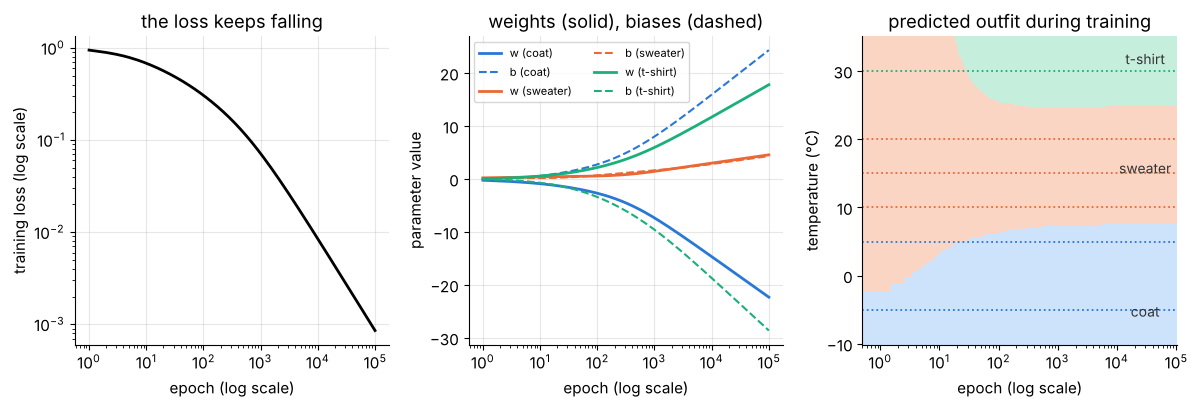

In [35]:
loss_curve = np.array([hist_long[e][2] for e in PLOT_EPOCHS])
W_curve = np.array([hist_long[e][0].ravel() for e in PLOT_EPOCHS])     # (n_epochs, 3)
b_curve = np.array([hist_long[e][1] for e in PLOT_EPOCHS])             # (n_epochs, 3)
temps_grid = np.linspace(-10, 35, 226)                                 # °C
region_map = np.array([predict((temps_grid / 10)[:, None], *hist_long[e][:2]) for e in PLOT_EPOCHS]).T

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
axes[0].loglog(PLOT_EPOCHS, loss_curve, color="k", lw=2)
axes[0].set(xlabel="epoch (log scale)", ylabel="training loss (log scale)", title="the loss keeps falling")
for k in range(3):
    axes[1].plot(PLOT_EPOCHS, W_curve[:, k], color=CLASS_COLORS[k], lw=2, label=f"w ({CLASS_NAMES[k]})")
    axes[1].plot(PLOT_EPOCHS, b_curve[:, k], color=CLASS_COLORS[k], lw=1.5, ls="--", label=f"b ({CLASS_NAMES[k]})")
axes[1].set_xscale("log")
axes[1].set(xlabel="epoch (log scale)", ylabel="parameter value", title="weights (solid), biases (dashed)")
axes[1].legend(fontsize=8, ncol=2)
axes[2].pcolormesh(PLOT_EPOCHS, temps_grid, region_map, cmap=REGION_CMAP, vmin=0, vmax=2, shading="nearest")
for x_i, y_i in zip(x_toy, y_toy):
    axes[2].axhline(10 * x_i, color=CLASS_COLORS[y_i], lw=1.3, ls=":")
for name, t in [("coat", -6), ("sweater", 15), ("t-shirt", 31)]:
    axes[2].text(3e4, t, name, ha="center", fontsize=10, color="0.2")
axes[2].set_xscale("log")
axes[2].set(xlabel="epoch (log scale)", ylabel="temperature (°C)", title="predicted outfit during training")
axes[2].grid(False)
plt.tight_layout()
plt.show()

In the right panel you can watch the model's ideas evolve. After the first epoch it predicts "sweater" (the most
frequent class) everywhere above about −2 °C and "coat" only below. The coat region then grows on the cold side. At
epoch 19 a t-shirt region appears at the hot end (above 34 °C). At epoch 25 the coat region reaches the 5 °C day,
and at epoch 29 the growing t-shirt region covers the 30 °C day. Later the two boundaries barely move, while the
weights in the middle panel keep growing. Which brings us to the most important lesson of this toy problem.

### 6.7 Separable data: the loss never reaches zero

Since epoch 29 every training day is classified correctly, yet the loss keeps decreasing and the weights keep
growing. Will gradient descent ever stop?

The six days are **linearly separable**: some choice of $\mathbf W, \mathbf b$ classifies all of them correctly.
Take any such choice and multiply all parameters by a factor $c > 1$. The decision regions stay the same
(Section 3.2), but every margin $z_{y_i} - z_k$ is multiplied by $c$, so every $p_{i,y_i}$ moves closer to 1 and
the loss moves closer to 0. The loss can therefore be made as small as we like, but no finite parameters reach
$\mathcal L = 0$: **the minimum does not exist**, the gradient $\frac1N(\mathbf P - \mathbf Y)^\top\mathbf X$ never becomes zero, and
gradient descent walks off towards infinity forever, ever more slowly.

What *does* converge is the **direction** of the parameter vector. A beautiful result (Soudry et al., 2018) says
that on separable data, gradient descent on the cross-entropy converges in direction to the **maximum-margin**
classifier: among all parameters that give every correct logit a lead of at least 1 over every wrong logit, the
one with the smallest norm, the same idea as a support vector machine. Let us compute that classifier for our
six days (a small constrained optimization problem) and compare.

In [36]:
def boundaries_toy(W, b):
    """Temperatures (°C) where the coat/sweater and the sweater/t-shirt logits tie.
    (Meaningful once the three classes win, in this order, from cold to hot.)"""
    w = W.ravel()
    return 10 * (b[1] - b[0]) / (w[0] - w[1]), 10 * (b[2] - b[1]) / (w[1] - w[2])

def max_margin_1d(x, y, K):
    """Hard-margin multiclass linear classifier for 1-D inputs: minimize (||w||^2 + ||b||^2) / 2 subject to
    z_{y_i} - z_k >= 1 for every sample i and every wrong class k. Solved numerically with SLSQP."""
    wrong = np.arange(K)[None, :] != y[:, None]                        # (N, K) mask of the wrong classes
    def margins(theta):
        Z = np.outer(x, theta[:K]) + theta[K:]                         # (N, K) logits
        return (Z[np.arange(len(y)), y][:, None] - Z)[wrong] - 1.0     # every entry must be >= 0
    res = minimize(lambda th: 0.5 * th @ th, np.zeros(2 * K), method="SLSQP",
                   constraints=[{"type": "ineq", "fun": margins}], options={"ftol": 1e-12, "maxiter": 500})
    return res.x[:K], res.x[K:]

w_mm, b_mm = max_margin_1d(x_toy, y_toy, K=3)
theta_mm = np.concatenate([w_mm, b_mm])
print("maximum-margin classifier: w =", clean(w_mm), " b =", clean(b_mm),
      " boundaries (°C):", clean(np.array(boundaries_toy(w_mm, b_mm)), 2))
rows = []
for ep in [100, 1_000, 10_000, 100_000]:
    W_e, b_e, loss_e = hist_long[ep]
    theta = np.concatenate([W_e.ravel(), b_e])
    cos = theta @ theta_mm / (np.linalg.norm(theta) * np.linalg.norm(theta_mm))
    rows.append([ep, np.linalg.norm(W_e), loss_e, *boundaries_toy(W_e, b_e), np.degrees(np.arccos(min(cos, 1.0)))])
display(clean(pd.DataFrame(rows, columns=["epoch", "||W||", "loss", "coat|sweater (°C)", "sweater|t-shirt (°C)",
                                          "angle to max-margin (degrees)"]).set_index("epoch")))

maximum-margin classifier: w = [-3.3333  0.6667  2.6667]  b = [ 3.6667  0.6667 -4.3333]  boundaries (°C): [ 7.5 25. ]


,||W||,loss,coat|sweater (°C),sweater|t-shirt (°C),angle to max-margin (degrees)
epoch,,,,,
100,3.5019,0.3057,6.3556,25.4929,2.3415
1000,9.5718,0.0713,7.3007,24.7238,0.6106
10000,18.9889,0.0085,7.4133,24.8175,0.4877
100000,28.9178,0.0009,7.4435,24.8780,0.3728


- $\lVert\mathbf W\rVert$ grows by about 10 every time the number of epochs is multiplied by 10 ($9.6 \to 19.0 \to 28.9$):
  the parameters grow **logarithmically** and never settle.
- The boundaries creep towards 7.5 °C and 25 °C, the boundaries of the maximum-margin classifier. These are exactly
  the midpoints of the gaps between neighbouring classes: between the 5 °C coat day and the 10 °C sweater day,
  and between the 20 °C sweater day and the 30 °C t-shirt day. The angle between the parameter vector and the
  maximum-margin direction shrinks towards 0, but very slowly.

> **Common pitfall.** "The training loss is still going down, so the model is still getting better." On separable
> training data, a falling loss after 100% training accuracy mostly means **growing over-confidence**: the
> predicted probabilities are pushed towards 0 and 1 without changing a single decision. This hurts the
> meaning of the probabilities (Section 9), and with real data it can hurt test accuracy too.

**The cure: L2 regularization.** Adding $\frac\lambda2\lVert\mathbf W\rVert_F^2$ makes the objective blow up as
$\lVert\mathbf W\rVert \to \infty$. The bias differences $b_j - b_k$ cannot run off either: a class whose bias fell far
behind the others would give its own training days a probability near 0, hence a huge loss, and every class has
training days. So the minimum is attained at a finite point. The minimizing $\mathbf W$ is unique, because the
regularized objective is strictly convex in $\mathbf W$. The unpenalized biases are unique only up to adding the same
constant to all of them, and gradient descent started from $\mathbf b = \mathbf 0$ keeps $\sum_k b_k = 0$ (Section 5.6).
Gradient descent now converges. Let us train for 20,000 epochs with three values of $\lambda$ and watch
$\lVert\mathbf W\rVert$ settle.

,||W|| @ 1k,||W|| @ 10k,||W|| @ 20k,data loss,coat|sweater (°C),sweater|t-shirt (°C),p_tshirt(30°C)
lambda,,,,,,,
0.001,8.4048,10.8549,10.8690,0.0480,7.4926,25.0376,0.9578
0.010,4.8018,4.8669,4.8669,0.1928,7.1731,25.3904,0.8181
0.100,1.7166,1.7166,1.7166,0.4856,6.1459,29.3899,0.5066


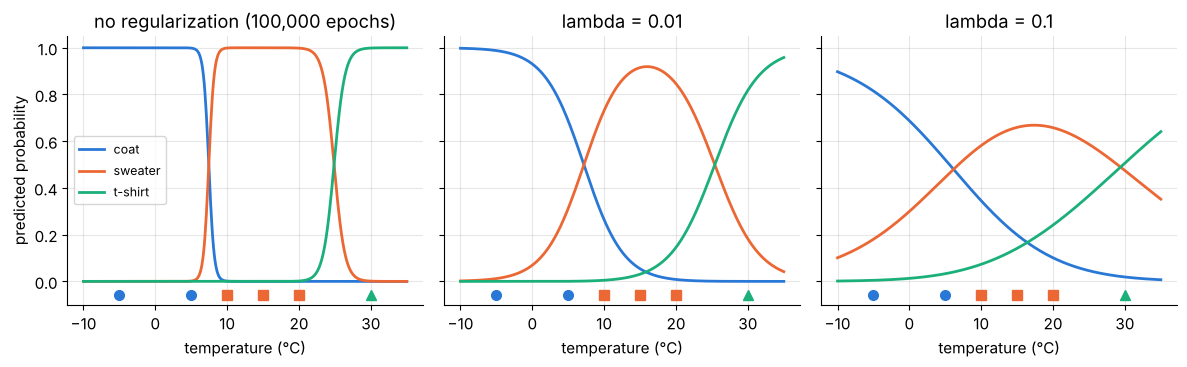

In [37]:
LAMBDAS_TOY = [0.001, 0.01, 0.1]
reg_runs = {lam: train_batch_gd(X_toy, y_toy, K=3, eta=ETA_TOY, epochs=20_000, lam=lam,
                                record=[1_000, 10_000, 20_000]) for lam in LAMBDAS_TOY}
rows = []
for lam, (W_reg, b_reg, hist_reg) in reg_runs.items():
    rows.append([lam, *[np.linalg.norm(hist_reg[e][0]) for e in (1_000, 10_000, 20_000)],
                 cross_entropy(X_toy @ W_reg.T + b_reg, y_toy), *boundaries_toy(W_reg, b_reg),
                 softmax(W_reg @ np.array([3.0]) + b_reg)[2]])
display(clean(pd.DataFrame(rows, columns=["lambda", "||W|| @ 1k", "||W|| @ 10k", "||W|| @ 20k", "data loss",
                                          "coat|sweater (°C)", "sweater|t-shirt (°C)", "p_tshirt(30°C)"])
              .set_index("lambda")))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
temps_fine = np.linspace(-10, 35, 451)
panels = [("no regularization (100,000 epochs)", W_long, b_long),
          ("lambda = 0.01", *reg_runs[0.01][:2]), ("lambda = 0.1", *reg_runs[0.1][:2])]
for ax, (title, W_m, b_m) in zip(axes, panels):
    P_m = predict_proba((temps_fine / 10)[:, None], W_m, b_m)
    for k in range(3):
        ax.plot(temps_fine, P_m[:, k], color=CLASS_COLORS[k], lw=2, label=CLASS_NAMES[k])
    for x_i, y_i in zip(x_toy, y_toy):
        ax.plot(10 * x_i, -0.06, marker=CLASS_MARKERS[y_i], color=CLASS_COLORS[y_i], ms=7, ls="none")
    ax.set_title(title)
    ax.set_xlabel("temperature (°C)")
    ax.set_ylim(-0.1, 1.05)
axes[0].set_ylabel("predicted probability")
axes[0].legend(fontsize=9, loc="center left")
plt.tight_layout()
plt.show()

With $\lambda = 0.01$ and $\lambda = 0.1$ the norm stops changing well before 10,000 epochs: gradient descent has
converged to the regularized minimum. With the weak $\lambda = 0.001$ the minimum lies far away (large weights) and
the approach is slower, but $\lVert\mathbf W\rVert$ still levels off instead of growing forever. Stronger
regularization means smaller weights, softer probability curves (the t-shirt probability of the 30 °C day drops
to about one half for $\lambda = 0.1$) and a higher *data* loss, the price paid for more modest predictions.
Which $\lambda$ is best cannot be decided on the training data. That is the job of a validation set (Section 8).

> **Going deeper.** Stopping gradient descent early is another (implicit) form of regularization: after about 50
> epochs the toy model already has sensible boundaries and moderate weights. And the maximum-margin result is one
> piece of the answer to a famous puzzle about neural networks: why models trained far beyond 100% training
> accuracy can still generalize: gradient descent itself prefers "large-margin" solutions. (This is proved for
> linear models like ours. For deep networks it is only part of the story.)

**Quick check.**
1. A dataset has $K = 4$ classes with frequencies $(0.1,\ 0.2,\ 0.3,\ 0.4)$. Starting from all-zero parameters, what is $\nabla_{\mathbf b}\mathcal L$ in the first epoch?
2. Training accuracy is 100% and the training loss keeps decreasing. Is the classifier still improving?
3. Why can one gradient step *increase* the loss of an individual training sample?

<details>
<summary>Answer</summary>

1. $\partial\mathcal L/\partial b_k = \frac1K - \frac{n_k}{N}$, so $\nabla_{\mathbf b}\mathcal L = (0.15,\ 0.05,\ -0.05,\ -0.15)$: the step raises
   the biases of the frequent classes and lowers those of the rare ones.
2. Its decisions on the training set no longer change. If the data are separable, it is mostly becoming more
   confident (larger weights). Whether that helps or hurts on new data must be checked on a validation set.
3. Gradient descent follows the gradient of the **average** loss. A step that helps most samples can hurt a few,
   like the 30 °C day in Section 6.4, whose t-shirt probability fell because the frequent sweater class was boosted.
</details>

## 7. Watching softmax regression learn in 2-D

With one feature, decision regions are intervals. With two features we can watch them as areas of the plane.
We generate four classes: three "outer" clouds of points arranged around a fourth, central cloud. The central
class is the interesting one: no single straight line separates it from the rest (the rest *surrounds* it),
so a one-vs-rest model is in trouble. For softmax regression, the region of the central class can simply be
the intersection of three half-planes (Section 3.2), i.e. a triangle.

N = 300, D = 2, K = 4 | safe learning rates (Section 5.7): eta < 1.409. We use eta = 1.0


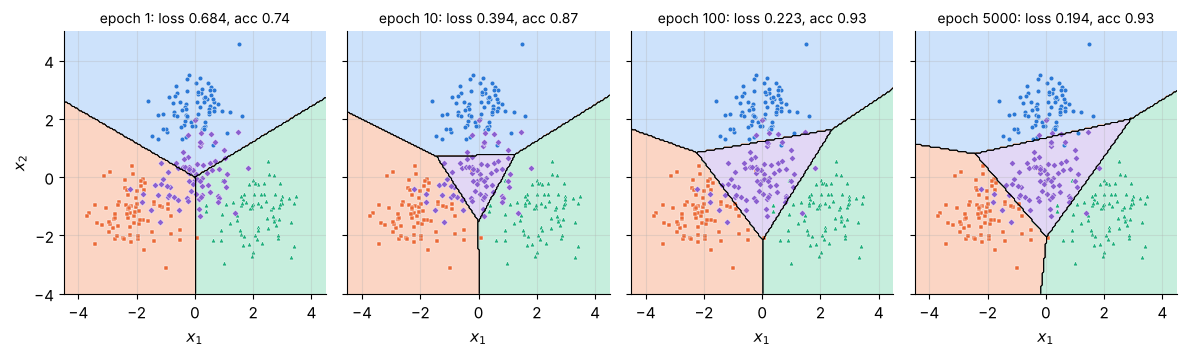

In [38]:
COLORS4 = CLASS_COLORS + ["#8b5fd0"]                     # a fourth colour and marker for this section
MARKERS4 = CLASS_MARKERS + ["D"]
REGION_CMAP4 = ListedColormap(["#cde2fb", "#fbd5c4", "#c6eedd", "#e2d7f5"])

rng_2d = np.random.default_rng(SEED)                      # a dedicated generator: this dataset never changes
centers_2d = np.array([[0.0, 2.4], [-2.1, -1.2], [2.1, -1.2], [0.0, 0.0]])   # class 3 sits in the middle
X_2d = np.vstack([c + 0.75 * rng_2d.normal(size=(75, 2)) for c in centers_2d])
y_2d = np.repeat(np.arange(4), 75)
X_2d_aug = np.column_stack([X_2d, np.ones(len(X_2d))])
print(f"N = {len(X_2d)}, D = 2, K = 4 | safe learning rates (Section 5.7): eta < "
      f"{4 / np.linalg.eigvalsh(X_2d_aug.T @ X_2d_aug / len(X_2d)).max():.3f}. We use eta = 1.0")

SNAPSHOTS_2D = [1, 10, 100, 5_000]
W_2d, b_2d, hist_2d = train_batch_gd(X_2d, y_2d, K=4, eta=1.0, epochs=5_000, record=SNAPSHOTS_2D)

g1_2d, g2_2d = np.meshgrid(np.linspace(-4.5, 4.5, 181), np.linspace(-4, 5, 181))
grid_2d = np.column_stack([g1_2d.ravel(), g2_2d.ravel()])

def draw_points(ax, X, y, classes=None, s=12):
    """Scatter the samples with one colour and marker per class."""
    for k in (np.unique(y) if classes is None else classes):
        ax.scatter(*X[y == k].T, s=s, marker=MARKERS4[k], color=COLORS4[k], edgecolor="white", linewidth=0.3)

def draw_region_outlines(ax, labels, K, lw=0.7):
    """Black outline of every decision region (labels = predicted class on the grid)."""
    for k in range(K):
        ax.contour(g1_2d, g2_2d, (labels == k).astype(float), levels=[0.5], colors="k", linewidths=lw)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True)
for ax, ep in zip(axes, SNAPSHOTS_2D):
    W_e, b_e, loss_e = hist_2d[ep]
    labels_e = predict(grid_2d, W_e, b_e).reshape(g1_2d.shape)
    ax.contourf(g1_2d, g2_2d, labels_e, levels=[-0.5, 0.5, 1.5, 2.5, 3.5], cmap=REGION_CMAP4)
    draw_region_outlines(ax, labels_e, K=4)
    draw_points(ax, X_2d, y_2d)
    ax.set_title(f"epoch {ep}: loss {loss_e:.3f}, acc {np.mean(predict(X_2d, W_e, b_e) == y_2d):.2f}", fontsize=10)
    ax.set_xlabel("$x_1$")
    ax.set_aspect("equal")
axes[0].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

After a single epoch the three outer classes already own sensible wedges of the plane, but the central class
(purple diamonds) owns nothing. Why? The classes are balanced, so the first gradient leaves every bias at zero
($\partial\mathcal L/\partial b_k = \frac1K - \frac{n_k}{N} = 0$, Section 6.3), and the central class's weights barely move
because its points average to about $(0, 0)$. So $z_3 \approx 0$ everywhere, while the three outer logits (whose sum
is about zero) always include one that is at least zero. From the second epoch on, the misclassified central
points keep raising the central bias, and the **bias** is what carves out the central region: class 3 wins
wherever no outer class has a strong score. By epoch 100 the regions are essentially final, and the remaining
epochs only fine-tune.

Below, the final probability map of every class. The outer classes have "ramps" (large in one direction), the
central class has a "hill", something a single sigmoid of a linear function can never produce.

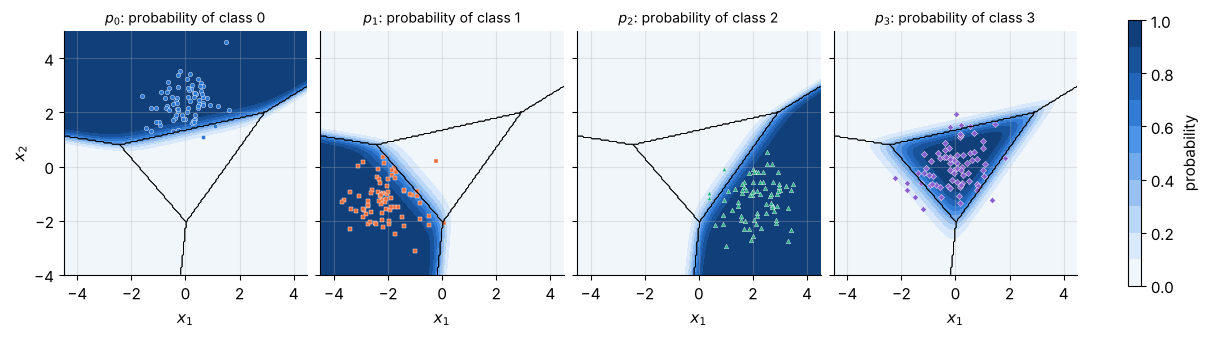

corner where classes 0, 1, 3 tie at [-2.431  0.804]: tied logit 4.610, class 2 only -13.831
corner where classes 0, 2, 3 tie at [2.935 2.008]: tied logit 4.186, class 1 only -12.557
corner where classes 1, 2, 3 tie at [ 0.023 -2.055]: tied logit 4.994, class 0 only -14.983
-> the region of class 3 is a triangle with area 9.15


In [39]:
P_grid_2d = predict_proba(grid_2d, W_2d, b_2d)
labels_2d = predict(grid_2d, W_2d, b_2d).reshape(g1_2d.shape)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True, constrained_layout=True)
for k, ax in enumerate(axes):
    im = ax.contourf(g1_2d, g2_2d, P_grid_2d[:, k].reshape(g1_2d.shape), levels=np.linspace(0, 1, 11), cmap=SEQ_CMAP)
    draw_region_outlines(ax, labels_2d, K=4, lw=0.6)
    draw_points(ax, X_2d, y_2d, classes=[k], s=10)
    ax.set_title(f"$p_{k}$: probability of class {k}", fontsize=10)
    ax.set_xlabel("$x_1$")
    ax.set_aspect("equal")
axes[0].set_ylabel("$x_2$")
fig.colorbar(im, ax=axes, shrink=0.8, label="probability")
plt.show()

# The region of the central class: its corners are the points where class 3 ties with two outer classes
corners = []
for j, k in [(0, 1), (0, 2), (1, 2)]:
    A_jk = np.vstack([W_2d[3] - W_2d[j], W_2d[3] - W_2d[k]])          # solve z_3 = z_j and z_3 = z_k
    v = np.linalg.solve(A_jk, [b_2d[j] - b_2d[3], b_2d[k] - b_2d[3]])
    z_v = W_2d @ v + b_2d
    third = ({0, 1, 2} - {j, k}).pop()
    print(f"corner where classes {j}, {k}, 3 tie at {clean(v, 3)}: tied logit {z_v[3]:.3f}, class {third} only {z_v[third]:.3f}")
    corners.append(v)
d1, d2 = corners[1] - corners[0], corners[2] - corners[0]
print(f"-> the region of class 3 is a triangle with area {0.5 * abs(d1[0] * d2[1] - d1[1] * d2[0]):.2f}")

### 7.1 Comparison with scikit-learn and with one-vs-rest

scikit-learn's `LogisticRegression` fits exactly this model when there are more than two classes (it is
"multinomial" by default). With `C=np.inf` it uses no regularization, and its L-BFGS solver (a quasi-Newton
method that uses curvature information) needs far fewer iterations than our plain gradient descent. We also fit
a one-vs-rest model made of four independent logistic regressions.

training loss: ours (5,000 GD epochs) 0.19416 | scikit-learn 0.19416 (43 L-BFGS iterations)
largest probability difference on the training points: 0.0031
scikit-learn's weights and biases sum to zero over the classes too: [0. 0.] 0.0
training accuracy: softmax (ours) 0.933 | scikit-learn 0.933 | one-vs-rest 0.907
  one-vs-rest detector 'class 0 or not?': accuracy 0.980, average P(class 0) on its own points 0.943
  one-vs-rest detector 'class 1 or not?': accuracy 0.970, average P(class 1) on its own points 0.885
  one-vs-rest detector 'class 2 or not?': accuracy 0.983, average P(class 2) on its own points 0.942
  one-vs-rest detector 'class 3 or not?': accuracy 0.750, average P(class 3) on its own points 0.250
the 'class 3 or not?' detector outputs values between 0.227 and 0.266 on all 300 points
central points labelled 3: one-vs-rest 0.707 | softmax 0.840


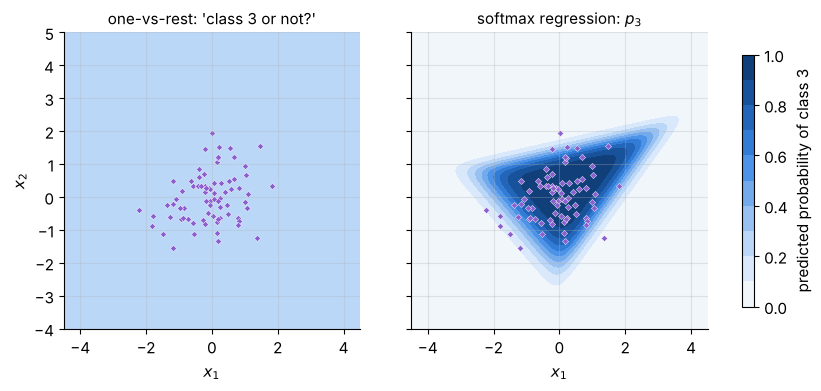

In [40]:
sk_2d = LogisticRegression(C=np.inf, max_iter=5000, tol=1e-10).fit(X_2d, y_2d)
ovr_2d = OneVsRestClassifier(LogisticRegression(C=np.inf, max_iter=5000)).fit(X_2d, y_2d)
P_ours_2d = predict_proba(X_2d, W_2d, b_2d)
print(f"training loss: ours (5,000 GD epochs) {cross_entropy(X_2d @ W_2d.T + b_2d, y_2d):.5f} | "
      f"scikit-learn {cross_entropy(X_2d @ sk_2d.coef_.T + sk_2d.intercept_, y_2d):.5f} "
      f"({sk_2d.n_iter_[0]} L-BFGS iterations)")
print(f"largest probability difference on the training points: {np.abs(P_ours_2d - sk_2d.predict_proba(X_2d)).max():.4f}")
print("scikit-learn's weights and biases sum to zero over the classes too:",
      clean(sk_2d.coef_.sum(axis=0), 6), clean(sk_2d.intercept_.sum(), 6))
print(f"training accuracy: softmax (ours) {np.mean(predict(X_2d, W_2d, b_2d) == y_2d):.3f} | "
      f"scikit-learn {sk_2d.score(X_2d, y_2d):.3f} | one-vs-rest {ovr_2d.score(X_2d, y_2d):.3f}")
for k, est in enumerate(ovr_2d.estimators_):
    print(f"  one-vs-rest detector 'class {k} or not?': accuracy {est.score(X_2d, (y_2d == k).astype(int)):.3f}, "
          f"average P(class {k}) on its own points {est.predict_proba(X_2d[y_2d == k])[:, 1].mean():.3f}")
p_det3 = ovr_2d.estimators_[3].predict_proba(X_2d)[:, 1]
print(f"the 'class 3 or not?' detector outputs values between {p_det3.min():.3f} and {p_det3.max():.3f} on all 300 points")
print(f"central points labelled 3: one-vs-rest {np.mean(ovr_2d.predict(X_2d[y_2d == 3]) == 3):.3f} | "
      f"softmax {np.mean(predict(X_2d[y_2d == 3], W_2d, b_2d) == 3):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8), sharey=True, constrained_layout=True)
maps = [(ovr_2d.estimators_[3].predict_proba(grid_2d)[:, 1], "one-vs-rest: 'class 3 or not?'"),
        (P_grid_2d[:, 3], "softmax regression: $p_3$")]
for ax, (vals, title) in zip(axes, maps):
    im = ax.contourf(g1_2d, g2_2d, vals.reshape(g1_2d.shape), levels=np.linspace(0, 1, 11), cmap=SEQ_CMAP)
    draw_points(ax, X_2d, y_2d, classes=[3], s=10)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("$x_1$")
    ax.set_aspect("equal")
axes[0].set_ylabel("$x_2$")
fig.colorbar(im, ax=axes, shrink=0.85, label="predicted probability of class 3")
plt.show()

What we learn from this comparison:

- **Our gradient descent and scikit-learn find the same model.** Both reach a loss of 0.19416, and the
  probabilities agree to within 0.0031. Plain gradient descent is still creeping along a very flat valley after
  5,000 epochs, while L-BFGS converged in a few dozen iterations. For a convex problem this small, second-order
  style solvers are the practical choice, but they compute exactly the same thing.
- scikit-learn's solution is also zero-sum: its solver starts from zeros and, like gradient descent, only ever
  moves in directions built from gradients, which have zero class sums (Section 5.6).
- **One-vs-rest is worse (0.907 vs 0.933), and the reason is the central class.** Its detector "class 3 or not?"
  has accuracy 0.750 (exactly the fraction of points that are *not* class 3) and its output is almost
  constant (between 0.23 and 0.27 on every training point): a ring of "no" around a blob of "yes" cannot be
  separated by one straight line, so the best logistic regression nearly ignores the input and predicts the
  base rate 0.25. The one-vs-rest classifier
  still labels about 71% of the central points correctly, but only by luck: its argmax picks class 3 wherever
  all three outer detectors happen to fall below 0.25. Softmax regression lets the classes compete and gives
  class 3 a proper hill of probability.

**Quick check.**
1. In a 2-D softmax regression with $K$ classes, how many straight sides can the region of one class have at most?
2. Can a class end up with an empty region, i.e. never be predicted?
3. Why is the best "class 3 or not?" logistic regression a constant?

<details>
<summary>Answer</summary>

1. At most $K - 1$: the region is an intersection of $K-1$ half-planes, one per competing class (some of them may
   be redundant). With $K = 4$ the central region above is a triangle.
2. Yes, if its logit is never the largest anywhere, like the masked sweater in the second test of Exercise 4.
   Its probabilities are still positive everywhere, and it just never wins.
3. At the optimum of a logistic regression the gradient vanishes: $\sum_i (p_i - y_i) = 0$ and $\sum_i (p_i - y_i)\,\mathbf x_i = \mathbf 0$.
   For the flat prediction $p_i = 0.25$ the first equation holds, and the second becomes
   $0.25\sum_i \mathbf x_i = \sum_{i:\,y_i = 3}\mathbf x_i$, i.e. "the class-3 points have the same mean as all points", which is true here
   by symmetry, as both means are close to the origin. So the (almost) flat sigmoid is the optimum: a single
   linear score cannot detect a class that differs from the others in *spread* but not in *mean*.
</details>

## 8. Real data: handwritten digits

Time for a real problem. scikit-learn ships with a small dataset of handwritten digits: 1,797 grayscale
images of $8 \times 8$ pixels, each showing one digit from 0 to 9. The images were made by scanning digits on
a finer $32\times 32$ grid and then counting, inside every $4\times 4$ block, how many of the 16 tiny cells
contain ink. So each of the 64 "pixels" is an integer from 0 (no ink) to 16 (fully inked).

Our model treats an image as a vector $\mathbf x \in \mathbb R^{64}$ (the rows of the image laid end to end), so
$D = 64$, $K = 10$, and $\mathbf W$ is a $10 \times 64$ matrix with $10 \cdot 64 + 10 = 650$ parameters.
Everything else is exactly the model of Sections 3–6.

### 8.1 The data and a three-way split

X: (1797, 64), y: (1797,), pixel range [0.0, 1.0]
images per class: [178 182 177 183 181 182 181 179 174 180]


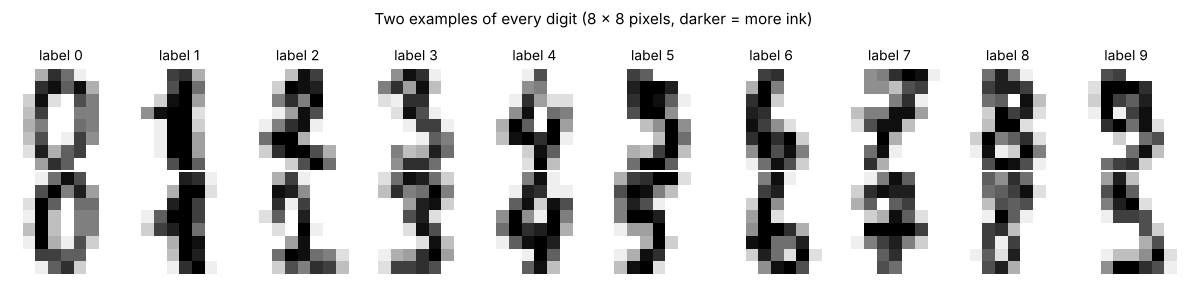

In [41]:
digits = load_digits()
X_digits = digits.data / 16.0           # (1797, 64) pixel values scaled from 0..16 to [0, 1]
y_digits = digits.target                # (1797,) integer labels 0..9
K_DIG = 10
print(f"X: {X_digits.shape}, y: {y_digits.shape}, pixel range [{X_digits.min()}, {X_digits.max()}]")
print("images per class:", np.bincount(y_digits))

def image_panel(ax, img, **imshow_kwargs):
    """Show an 8 x 8 image without ticks or frame (the row and column labels stay possible)."""
    ax.imshow(img.reshape(8, 8), **imshow_kwargs)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig, axes = plt.subplots(2, 10, figsize=(12, 2.9))
for k in range(10):
    examples = np.flatnonzero(y_digits == k)[:2]             # the first two images of every digit
    for row, idx in enumerate(examples):
        image_panel(axes[row, k], X_digits[idx], cmap="gray_r", vmin=0, vmax=1)
    axes[0, k].set_title(f"label {k}", fontsize=10)
fig.suptitle("Two examples of every digit (8 x 8 pixels, darker = more ink)", fontsize=11)
plt.tight_layout(h_pad=1.2)
plt.show()

We split the data three ways, keeping the class proportions equal in every part (`stratify`):

| part | share | used for |
|---|---|---|
| **training set** | 60% | computing gradients, i.e. fitting $\mathbf W$ and $\mathbf b$ |
| **validation set** | 20% | choosing hyperparameters: learning rate, number of epochs, $\lambda$ |
| **test set** | 20% | one final, honest estimate of performance, looked at only once, at the very end |

Why not choose hyperparameters on the test set? Because every choice made by looking at a dataset leaks a little
information from it into the model. After trying 50 settings and keeping the best test score, that score is
optimistic: some of its quality is luck that will not repeat on new data.

The scaling step above (divide by 16) is safe to apply before splitting, because 16 is a known property of the
pixel format, not a statistic computed from the data. Standardizing with a *mean* and *standard deviation* is
different: those must be computed on the training set only (we will do that in Section 10).

In [42]:
X_rest, X_te, y_rest, y_te = train_test_split(X_digits, y_digits, test_size=0.2, stratify=y_digits,
                                              random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print(f"train {X_tr.shape}, validation {X_va.shape}, test {X_te.shape}")

X_tr_aug = np.column_stack([X_tr, np.ones(len(X_tr))])
eta_safe_dig = 4 / np.linalg.eigvalsh(X_tr_aug.T @ X_tr_aug / len(X_tr)).max()
print(f"safe full-batch learning rate from Section 5.7: eta < {eta_safe_dig:.3f}")
print(f"loss of the all-zero model (uniform guess) = ln 10 = {np.log(10):.4f}")

train (1077, 64), validation (360, 64), test (360, 64)
safe full-batch learning rate from Section 5.7: eta < 0.347
loss of the all-zero model (uniform guess) = ln 10 = 2.3026


### 8.2 Mini-batch gradient descent

Full-batch gradient descent (Section 6) computes the gradient on all $N$ training samples before taking a single
step. With $N = 1{,}077$ that is affordable, but for a million images it would mean one step per pass over the
data. **Mini-batch gradient descent** estimates the gradient from a small random batch $\mathcal B$ of $B$ samples:

$$
\nabla_{\mathbf W}\mathcal L \;\approx\; \frac1B\,(\mathbf P_{\mathcal B} - \mathbf Y_{\mathcal B})^\top\mathbf X_{\mathcal B} \;+\; \lambda\mathbf W,
\qquad
\nabla_{\mathbf b}\mathcal L \;\approx\; \frac1B\,(\mathbf P_{\mathcal B} - \mathbf Y_{\mathcal B})^\top\mathbf 1,
$$

where $\mathbf X_{\mathcal B}$ ($B\times D$), $\mathbf P_{\mathcal B}$ and $\mathbf Y_{\mathcal B}$ ($B\times K$) hold only the rows of the
batch. This is the very same formula as before, applied to fewer rows, so our `loss_and_grads` function from
Section 5.5 works unchanged. One **epoch** = shuffle the training set, cut it into consecutive batches, and take
one step per batch: with $B = 32$ that is $\lceil 1077/32\rceil = 34$ steps per epoch instead of one.

Two facts make this work:
- **The batch gradient is an unbiased estimate.** If the batch is drawn at random, its average gradient equals the
  full gradient *on average*. Individual steps zig-zag, but they point the right way on average.
- **The noise shrinks like $1/\sqrt B$.** Averaging $B$ independent per-sample gradients divides their standard
  deviation by $\sqrt B$. Quadrupling the batch halves the noise but makes each step four times as expensive.

Let us measure both effects: at a fixed point (the model after one epoch), compare 300 random mini-batch gradients
with the exact full-batch gradient.

In [43]:
def train_minibatch(X, y, K, eta, epochs, batch_size=32, lam=0.0, seed=SEED, X_val=None, y_val=None):
    """Mini-batch gradient descent for softmax regression, starting from W = 0, b = 0.

    Every epoch shuffles the training set and takes one step per batch of `batch_size` samples.
    Returns the final (W, b) and a DataFrame with the training (and validation) cross-entropy and
    accuracy after every epoch, and row 0 describes the model before training."""
    rng_mb = np.random.default_rng(seed)
    N, D = X.shape
    W, b = np.zeros((K, D)), np.zeros(K)
    rows = []
    for epoch in range(epochs + 1):
        if epoch > 0:
            order = rng_mb.permutation(N)                     # a fresh shuffle every epoch
            for start in range(0, N, batch_size):
                idx = order[start:start + batch_size]         # the last batch may be smaller
                _, dW, db = loss_and_grads(X[idx], y[idx], W, b, lam)
                W -= eta * dW
                b -= eta * db
        Z = X @ W.T + b
        row = {"epoch": epoch, "train_loss": cross_entropy(Z, y), "train_acc": np.mean(Z.argmax(axis=1) == y)}
        if X_val is not None:
            Z_val = X_val @ W.T + b
            row.update(val_loss=cross_entropy(Z_val, y_val), val_acc=np.mean(Z_val.argmax(axis=1) == y_val))
        rows.append(row)
    return W, b, pd.DataFrame(rows).set_index("epoch")


W_one, b_one, _ = train_minibatch(X_tr, y_tr, K_DIG, eta=0.5, epochs=1)
_, gW_full, gb_full = loss_and_grads(X_tr, y_tr, W_one, b_one)
g_full = np.concatenate([gW_full.ravel(), gb_full])
rng_noise = np.random.default_rng(0)
rows = []
for B in [1, 8, 32, 128, 512]:
    cosines, rel_errors = [], []
    for _ in range(300):
        idx = rng_noise.choice(len(X_tr), size=B, replace=False)
        _, gW_b, gb_b = loss_and_grads(X_tr[idx], y_tr[idx], W_one, b_one)
        g_b = np.concatenate([gW_b.ravel(), gb_b])
        cosines.append(g_b @ g_full / (np.linalg.norm(g_b) * np.linalg.norm(g_full)))
        rel_errors.append(np.linalg.norm(g_b - g_full) / np.linalg.norm(g_full))
    rows.append([B, np.mean(cosines), np.mean(rel_errors)])
noise_table = pd.DataFrame(rows, columns=["batch size B", "mean cosine with full gradient",
                                          "mean relative error"]).set_index("batch size B")
display(noise_table.round(3))

,mean cosine with full gradient,mean relative error
batch size B,,
1,0.079,7.409
8,0.315,2.730
32,0.585,1.408
128,0.831,0.674
512,0.970,0.257


With $B = 1$ (pure *stochastic* gradient descent) a single gradient is almost useless on its own: its cosine
with the true direction is only 0.08, and its error is seven times larger than the gradient itself. Every
eightfold increase of $B$ cuts the error by roughly $\sqrt 8 \approx 2.8$ (7.41 → 2.73), every fourfold increase by
about 2 (2.73 → 1.41 → 0.67). The jump from 128 to 512 shrinks the error even faster, because 512 is almost half
of the whole training set, and batches that large start to overlap with each other and with the full data. Yet
even $B = 32$, whose individual gradients are rather noisy (cosine 0.59), trains very well: the errors of
successive steps point in random directions and largely cancel, while the true gradient adds up.

> **Key idea.** Mini-batch gradient descent trades exact gradients for many more, cheaper steps. Batch sizes
> between 16 and 512 are typical in practice. The batch size and the learning rate interact (noisier steps need
> smaller learning rates).

### 8.3 A learning-rate study

We now train with batch size 32, no regularization, for 60 epochs, changing only the learning rate. We include
rates far above the "safe" full-batch bound of 0.347, to see what really happens.

,train loss,train acc,val loss,val acc,best val loss,at epoch,||W||
eta,,,,,,,
0.01,0.7179,0.9266,0.7491,0.9167,0.7491,60,5.3899
0.10,0.1853,0.9656,0.2209,0.9500,0.2209,60,13.4359
0.50,0.0784,0.9879,0.1318,0.9639,0.1318,60,21.4613
2.00,0.0365,0.9944,0.1120,0.9639,0.1063,55,32.5587
8.00,0.0134,0.9963,0.1531,0.9639,0.1401,22,58.1955
32.00,0.0000,1.0000,0.5590,0.9500,0.5590,60,220.9000


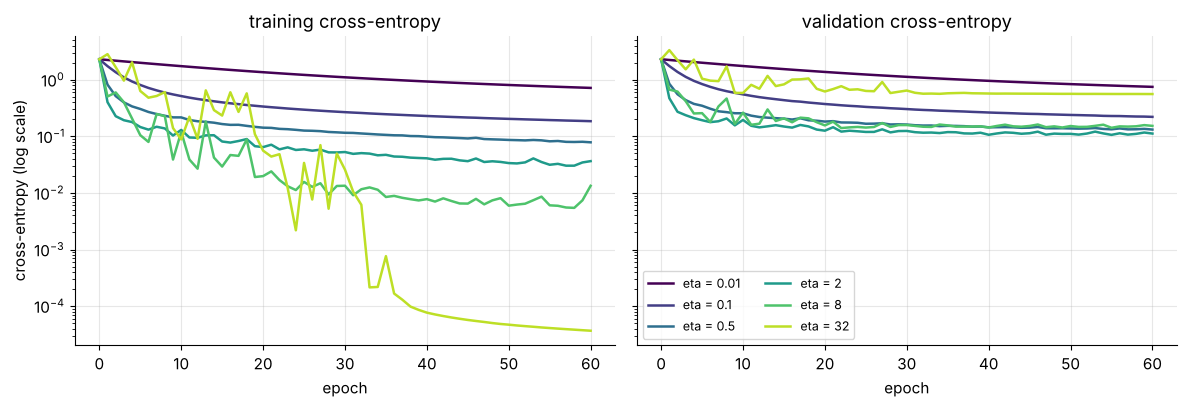

In [44]:
LR_STUDY = [0.01, 0.1, 0.5, 2.0, 8.0, 32.0]
lr_runs = {eta: train_minibatch(X_tr, y_tr, K_DIG, eta=eta, epochs=60, X_val=X_va, y_val=y_va)
           for eta in LR_STUDY}

rows = []
for eta, (W_e, b_e, hist) in lr_runs.items():
    rows.append([eta, hist.train_loss.iloc[-1], hist.train_acc.iloc[-1], hist.val_loss.iloc[-1],
                 hist.val_acc.iloc[-1], hist.val_loss.min(), hist.val_loss.idxmin(), np.linalg.norm(W_e)])
lr_table = pd.DataFrame(rows, columns=["eta", "train loss", "train acc", "val loss", "val acc",
                                       "best val loss", "at epoch", "||W||"]).set_index("eta")
display(lr_table.round(4))

lr_colors = plt.cm.viridis(np.linspace(0, 0.9, len(LR_STUDY)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for color, (eta, (_, _, hist)) in zip(lr_colors, lr_runs.items()):
    axes[0].plot(hist.index, hist.train_loss, color=color, lw=1.8, label=f"eta = {eta:g}")
    axes[1].plot(hist.index, hist.val_loss, color=color, lw=1.8, label=f"eta = {eta:g}")
for ax, name in zip(axes, ["training", "validation"]):
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_title(f"{name} cross-entropy")
axes[0].set_ylabel("cross-entropy (log scale)")
axes[1].legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

How to read the study:

- **Too small** ($\eta = 0.01$): after 60 epochs the training loss is still 0.72. The model is learning, just
  very slowly. Gradient descent is not wrong here, only impatient-making.
- **Reasonable** ($\eta = 0.1$ to $2$): the validation loss falls to between 0.22 and 0.11, and the best value in
  the table, 0.106, is reached with $\eta = 2$, almost six times the "safe" full-batch bound. The bound is a
  worst-case guarantee. It assumes maximal curvature everywhere (two classes splitting the probability
  50/50), which a model that is already fairly confident no longer has.
- **Large** ($\eta = 8$ and $32$): the *training* loss keeps improving (with $\eta = 32$ it essentially reaches zero
  and the training accuracy is 100%), but the validation loss does not follow. With $\eta = 8$ it bottoms out at
  epoch 22 and then creeps up again, and with $\eta = 32$ it stays above 0.55 throughout, five times worse than the best
  value in the table, while the validation *accuracy* barely changes (0.950).

The last point is worth pausing on. Unlike linear regression, softmax regression does not "explode" with a large
learning rate: the gradient is bounded ($|p_k - y_k| \le 1$), so huge steps simply race toward the
huge-weight solutions of Section 6.7. The 1,077 training digits turn out to be linearly separable, so the
training loss can be pushed to zero by growing $\lVert\mathbf W\rVert$ forever (look at the last column). The
predictions become extremely confident, and the few validation digits that are misclassified now cost an
enormous $-\log p$ each. Accuracy hides this. Cross-entropy reveals it.

> **Common pitfall.** Judging a classifier only by its training loss. A falling training loss together with a
> rising validation loss is the classic signature of **overfitting**. Here it comes from overconfidence, not
> from wrong decisions.

### 8.4 Two ways to regularize: stop early, or penalize large weights

The study suggests two remedies against overconfidence.

1. **Early stopping.** Track the validation loss after every epoch and keep the parameters from the best epoch, or
   simply give training a modest budget. Stopping early limits how far the weights can grow.
2. **L2 regularization** (Section 6.7). Minimize $\mathcal L_\lambda = \mathcal L + \frac\lambda2\lVert\mathbf W\rVert^2$. The penalty makes
   huge weights expensive, so even on separable data the minimum is attained at finite weights.

We take the best run of the study ($\eta = 2$, 60 epochs, $B = 32$) and repeat it with increasing $\lambda$. Nothing
else changes (the $\lambda = 0$ run is reused from the study). Because mini-batch gradient descent with a constant
learning rate never settles exactly at the minimum, we also compute the **exact minimizer** of $\mathcal L_\lambda$ for
every $\lambda > 0$: we hand our `loss_and_grads` to SciPy's general-purpose L-BFGS optimizer, a quasi-Newton method
that only needs a function returning the loss and its gradient. (For $\lambda = 0$ no minimizer exists, since the
training digits are separable.)

mini-batch GD (eta = 2, 60 epochs)                           exact minimizer (L-BFGS)                 
                               train loss val loss val acc    ||W||                 val loss val acc    ||W||
lambda                                                                                                       
0.0000                             0.0365   0.1120  0.9639  32.5587                      NaN     NaN      NaN
0.0001                             0.0555   0.1192  0.9667  27.5583                   0.1014  0.9694  29.3307
0.0003                             0.0941   0.1455  0.9611  22.2014                   0.1235  0.9750  21.8567
0.0010                             0.1782   0.2186  0.9472  16.1418                   0.1778  0.9722  15.6459
0.0030                             0.2466   0.2868  0.9472  12.0051                   0.2717  0.9583  11.4652

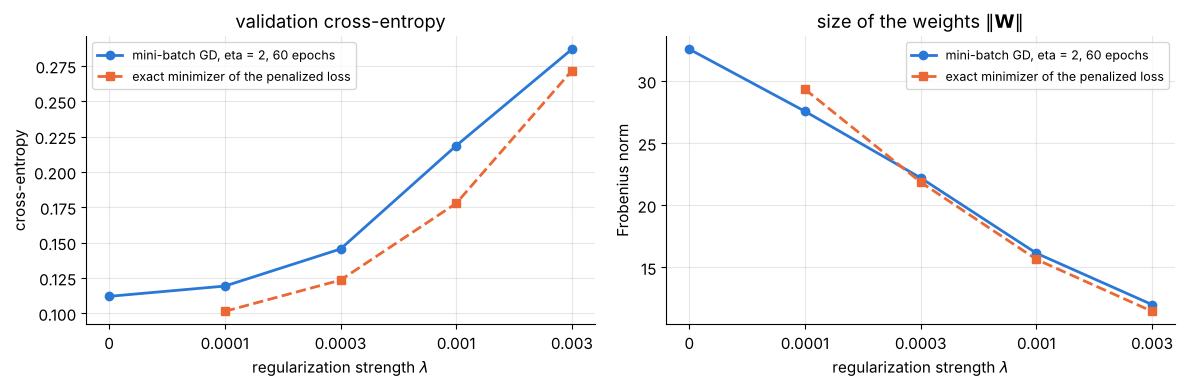

In [45]:
def fit_lbfgs(X, y, K, lam):
    """Minimize mean cross-entropy + lam/2 ||W||^2 with SciPy's L-BFGS, using OUR loss and gradient."""
    N, D = X.shape

    def objective(theta):                         # theta = all K*D weights followed by the K biases
        W, b = theta[:K * D].reshape(K, D), theta[K * D:]
        loss, dW, db = loss_and_grads(X, y, W, b, lam)
        return loss, np.concatenate([dW.ravel(), db])

    result = minimize(objective, np.zeros(K * (D + 1)), jac=True, method="L-BFGS-B",
                      options={"maxiter": 2000, "gtol": 1e-8})
    return result.x[:K * D].reshape(K, D), result.x[K * D:], result


ETA_FINAL = 2.0
LAMBDAS_DIG = [0.0, 1e-4, 3e-4, 1e-3, 3e-3]
reg_runs_dig = {lam: lr_runs[ETA_FINAL] if lam == 0 else
                train_minibatch(X_tr, y_tr, K_DIG, eta=ETA_FINAL, epochs=60, lam=lam, X_val=X_va, y_val=y_va)
                for lam in LAMBDAS_DIG}
exact_dig = {lam: fit_lbfgs(X_tr, y_tr, K_DIG, lam) for lam in LAMBDAS_DIG if lam > 0}

rows = []
for lam in LAMBDAS_DIG:
    W_e, b_e, hist = reg_runs_dig[lam]
    row = [hist.train_loss.iloc[-1], hist.val_loss.iloc[-1], hist.val_acc.iloc[-1], np.linalg.norm(W_e)]
    if lam > 0:
        W_x, b_x, _ = exact_dig[lam]
        row += [cross_entropy(X_va @ W_x.T + b_x, y_va), np.mean(predict(X_va, W_x, b_x) == y_va), np.linalg.norm(W_x)]
    else:
        row += [np.nan, np.nan, np.nan]
    rows.append(row)
reg_cols = pd.MultiIndex.from_tuples([("mini-batch GD (eta = 2, 60 epochs)", c) for c in
                                      ["train loss", "val loss", "val acc", "||W||"]]
                                     + [("exact minimizer (L-BFGS)", c) for c in ["val loss", "val acc", "||W||"]])
reg_table = pd.DataFrame(rows, columns=reg_cols, index=pd.Index(LAMBDAS_DIG, name="lambda"))
display(reg_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pos = np.arange(len(LAMBDAS_DIG))
for ax, col, title in [(axes[0], "val loss", "validation cross-entropy"), (axes[1], "||W||", "size of the weights $\\|\\mathbf{W}\\|$")]:
    ax.plot(pos, reg_table[("mini-batch GD (eta = 2, 60 epochs)", col)], "o-", color=CLASS_COLORS[0], lw=2,
            label="mini-batch GD, eta = 2, 60 epochs")
    ax.plot(pos, reg_table[("exact minimizer (L-BFGS)", col)], "s--", color=CLASS_COLORS[1], lw=2,
            label="exact minimizer of the penalized loss")
    ax.set_xticks(pos, [f"{lam:g}" for lam in LAMBDAS_DIG])
    ax.set_xlabel("regularization strength $\\lambda$")
    ax.set_title(title)
    ax.legend(fontsize=9)
axes[0].set_ylabel("cross-entropy")
axes[1].set_ylabel("Frobenius norm")
plt.tight_layout()
plt.show()

The table tells two different stories, and both are worth understanding.

- **The penalty itself works.** Look at the exact minimizers: as $\lambda$ grows, the weights shrink steadily
  (from 29.3 to 11.5), and the validation loss is lowest for the smallest penalty in the grid, $\lambda = 10^{-4}$
  (0.101), slightly better than anything early stopping achieved in the learning-rate study (0.106 at the best
  epoch). Larger penalties shrink the weights too much and push both losses up: they add *bias*.
- **Our mini-batch runs with $\lambda > 0$ look worse than they should.** At $\lambda = 10^{-3}$, for example, the mini-batch
  model has a validation loss of 0.219, while the exact minimizer of the *same* objective reaches 0.178. The
  penalty is not to blame, the optimizer is: with $\lambda > 0$ the predictions stay uncertain, so the curvature of
  the loss stays high, and a constant step of $\eta = 2$ (six times the safe bound) makes the iterates bounce
  around the minimum instead of settling in it. (Section 8.7 measures the gap in the objective directly.)

The general lesson: the learning rate, the batch size, the number of epochs and $\lambda$ all pull on the same rope,
how large and how confident the weights get, and they interact. Only the validation set can tell you which
combination works, and an unconverged optimizer can make a good regularizer look bad.

For the rest of this notebook we keep the best of our own mini-batch runs, $\eta = 2$ and $\lambda = 0$ after 60
epochs (regularized only by its short training), as the final digit classifier. The exact $\lambda = 10^{-4}$ model
would be a fine choice too. On the test set both get exactly the same accuracy.

In [46]:
W_dig, b_dig, hist_dig = reg_runs_dig[0.0]
LAM_BEST = 0.0
W_x4, b_x4, _ = exact_dig[1e-4]
print(f"final model: eta = {ETA_FINAL:g}, lambda = {LAM_BEST:g}, 60 epochs | validation loss "
      f"{hist_dig.val_loss.iloc[-1]:.4f}, validation accuracy {hist_dig.val_acc.iloc[-1]:.4f}")
print(f"test accuracy: final model {np.mean(predict(X_te, W_dig, b_dig) == y_te):.4f} | "
      f"exact lambda = 1e-4 model {np.mean(predict(X_te, W_x4, b_x4) == y_te):.4f}")

final model: eta = 2, lambda = 0, 60 epochs | validation loss 0.1120, validation accuracy 0.9639
test accuracy: final model 0.9583 | exact lambda = 1e-4 model 0.9583


> **Going deeper.** Regularization and large learning rates do not mix freely. With $\lambda > 0$ the weights stay
> moderate, the predictions stay uncertain, the curvature stays high, and a step size like 32, which only
> "worked" because huge weights made the loss surface nearly flat, now makes training oscillate wildly (try it:
> with $\eta = 32$ and $\lambda = 10^{-3}$ the training loss ends above 10). Learning-rate *schedules* that shrink $\eta$ over time are the usual
> remedy. They let mini-batch gradient descent settle into the minimum.

### 8.5 The final exam: test accuracy, confusion matrix, precision and recall

All decisions are made, so we may finally look at the test set, and only once. Accuracy alone says how often the model is
right. The **confusion matrix** says *which* mistakes it makes. Entry $C_{jk}$ counts the test images whose true
class is $j$ and whose predicted class is $k$: the diagonal holds the correct predictions, everything off the
diagonal is a mistake.

test accuracy 0.9583 (345 of 360), test cross-entropy 0.1192
same matrix as scikit-learn's confusion_matrix: True


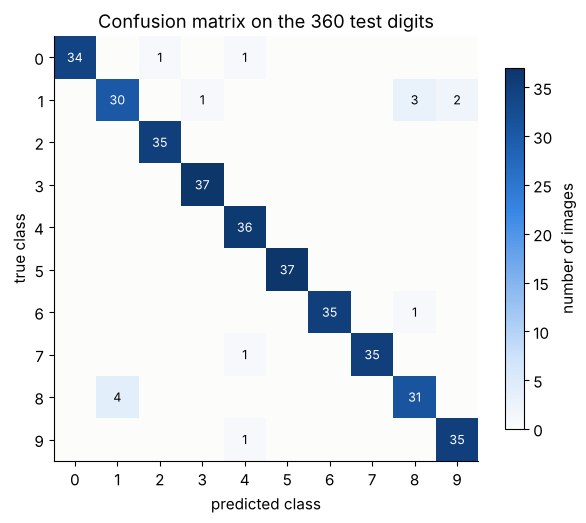

mistakes (count, true -> predicted): 4 x 8->1, 3 x 1->8, 2 x 1->9, 1 x 9->4, 1 x 7->4, 1 x 6->8, 1 x 1->3, 1 x 0->4, 1 x 0->2


In [47]:
def confusion_counts(y_true, y_pred, K):
    """K x K matrix C with C[j, k] = number of samples of true class j predicted as class k."""
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (y_true, y_pred), 1)            # add 1 at every (true, predicted) pair, repeats included
    return C

pred_te = predict(X_te, W_dig, b_dig)
P_te = predict_proba(X_te, W_dig, b_dig)
C_te = confusion_counts(y_te, pred_te, K_DIG)
print(f"test accuracy {np.mean(pred_te == y_te):.4f} ({np.sum(pred_te == y_te)} of {len(y_te)}), "
      f"test cross-entropy {cross_entropy(X_te @ W_dig.T + b_dig, y_te):.4f}")
print("same matrix as scikit-learn's confusion_matrix:", np.array_equal(C_te, confusion_matrix(y_te, pred_te)))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(C_te, cmap=SEQ_CMAP)
for j in range(K_DIG):
    for k in range(K_DIG):
        if C_te[j, k]:
            ax.text(k, j, C_te[j, k], ha="center", va="center", fontsize=9,
                    color="white" if C_te[j, k] > C_te.max() / 2 else "black")
ax.set_xticks(range(K_DIG))
ax.set_yticks(range(K_DIG))
ax.grid(False)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("Confusion matrix on the 360 test digits")
fig.colorbar(im, ax=ax, shrink=0.85, label="number of images")
plt.tight_layout()
plt.show()

off_diag = [(C_te[j, k], j, k) for j in range(K_DIG) for k in range(K_DIG) if j != k and C_te[j, k] > 0]
print("mistakes (count, true -> predicted):", ", ".join(f"{c} x {j}->{k}" for c, j, k in sorted(off_diag, reverse=True)))

The model gets 345 of the 360 test digits right (95.8%), close to its validation accuracy (96.4%): we did not
fool ourselves while tuning on the validation set. The mistakes are far from random. Seven of the 15 errors
are confusions between 1 and 8 (four 8s read as 1, three 1s read as 8), and two more 1s are read as 9. A
linear model compares *ink patterns*, and some writers' 1s, 8s and 9s put much of their ink in the same places.

For each class $k$ two numbers summarize a column and a row of the matrix:

$$
\text{precision}_k = \frac{C_{kk}}{\sum_j C_{jk}} = \frac{\text{correct "}k\text{" predictions}}{\text{all "}k\text{" predictions}},
\qquad
\text{recall}_k = \frac{C_{kk}}{\sum_j C_{kj}} = \frac{\text{correctly found }k\text{'s}}{\text{all true }k\text{'s}} .
$$

Precision answers "when the model says 8, how often is it really an 8?", and recall answers "of all the real 8s, how
many did the model find?". The **F1 score** $= 2\,\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$ is their harmonic mean,
which is high only if both are high. Averaging a metric over the classes with equal weight gives its
**macro average**. With balanced classes, as here, it is close to the plain accuracy.

,precision,recall,F1,support
digit,,,,
0,1.000,0.944,0.971,36
1,0.882,0.833,0.857,36
2,0.972,1.000,0.986,35
3,0.974,1.000,0.987,37
4,0.923,1.000,0.960,36
5,1.000,1.000,1.000,37
6,1.000,0.972,0.986,36
7,1.000,0.972,0.986,36
8,0.886,0.886,0.886,35


macro averages: precision 0.958, recall 0.958, F1 0.958


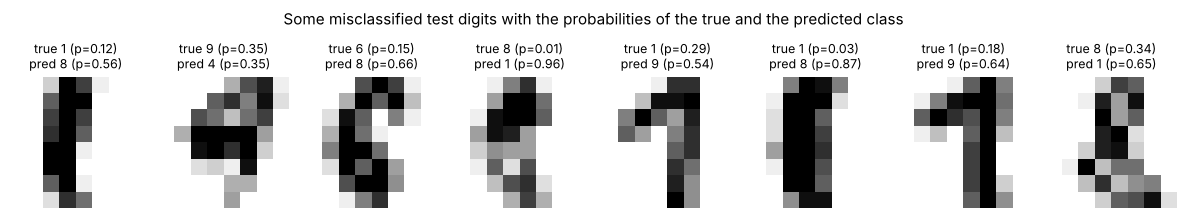

In [48]:
prec_te, rec_te, f1_te, support_te = precision_recall_fscore_support(y_te, pred_te, zero_division=0)
per_class = pd.DataFrame({"precision": prec_te, "recall": rec_te, "F1": f1_te, "support": support_te},
                         index=pd.Index(range(K_DIG), name="digit"))
display(per_class.round(3))
print(f"macro averages: precision {prec_te.mean():.3f}, recall {rec_te.mean():.3f}, F1 {f1_te.mean():.3f}")

wrong = np.flatnonzero(pred_te != y_te)
fig, axes = plt.subplots(1, len(wrong[:8]), figsize=(12, 2.4))
for ax, i in zip(np.atleast_1d(axes), wrong[:8]):
    image_panel(ax, X_te[i], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"true {y_te[i]} (p={P_te[i, y_te[i]]:.2f})\npred {pred_te[i]} (p={P_te[i, pred_te[i]]:.2f})",
                 fontsize=9)
fig.suptitle("Some misclassified test digits with the probabilities of the true and the predicted class", fontsize=11)
plt.tight_layout()
plt.show()

Digit 1 is the weakest class: its recall of 0.833 means that 6 of the 36 ones in the test set were missed, and its
precision of 0.882 means that 4 of the 34 images called "1" were something else (all of them 8s). Digit 8 comes next
(precision and recall 0.886). The digits 2, 3, 4 and 5 were all found (recall 1.0). Notice also how differently
sure the model is about its mistakes: some are near ties (the 9 read as a 4 gets 0.35 for both), but the fourth
image, an 8 read as a 1, gets probability 0.96 for the wrong class. Section 9 asks whether such confidences can be
trusted.

### ✏️ Exercise 10: precision, recall and F1 from a confusion matrix

Write `precision_recall_f1(C)` that takes a $K\times K$ confusion matrix (rows = true class, columns = predicted
class) and returns three arrays of length $K$. If a class is never predicted (or never occurs), define the
corresponding precision (or recall) as 0, and an F1 score with precision + recall = 0 as 0, exactly like
scikit-learn's `zero_division=0`.

In [49]:
# ✏️ Exercise 10
def precision_recall_f1(C):
    """Per-class (precision, recall, F1) from a confusion matrix C[true, predicted]."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex10():
    C = np.array([[5, 1, 0], [2, 3, 1], [0, 0, 4]])
    p, r, f = precision_recall_f1(C)
    assert np.allclose(p, [5 / 7, 3 / 4, 4 / 5]), f"precision should divide by COLUMN sums, got {p}"
    assert np.allclose(r, [5 / 6, 3 / 6, 1.0]), f"recall should divide by ROW sums, got {r}"
    assert np.allclose(f, [10 / 13, 0.6, 8 / 9]), f"F1 is the harmonic mean 2pr/(p+r), got {f}"
    p, r, f = precision_recall_f1(np.array([[3, 0], [2, 0]]))         # class 1 is never predicted
    assert np.all(np.isfinite(p)) and np.allclose(p, [0.6, 0.0]), f"never-predicted class -> precision 0, got {p}"
    assert np.allclose(f, [0.75, 0.0]), f"got F1 = {f}"
    p, r, f = precision_recall_f1(C_te)                                 # the digit classifier from above
    assert np.allclose(p, prec_te) and np.allclose(r, rec_te) and np.allclose(f, f1_te), "disagrees with scikit-learn"

run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def precision_recall_f1(C):
    C = np.asarray(C, dtype=float)
    tp = np.diag(C)                                    # correct predictions of each class
    predicted, actual = C.sum(axis=0), C.sum(axis=1)   # column sums, row sums
    zeros = np.zeros_like(tp)
    precision = np.divide(tp, predicted, out=zeros.copy(), where=predicted > 0)
    recall = np.divide(tp, actual, out=zeros.copy(), where=actual > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=zeros.copy(), where=denom > 0)
    return precision, recall, f1
```
Precision divides the diagonal by the column sums (everything *predicted* as $k$), recall by the row sums
(everything that *is* $k$). `np.divide(..., where=...)` skips the divisions by zero and leaves the 0 from `out`.
</details>

### 8.6 What did the model learn? Weight templates

Each logit is a dot product, $z_k = \mathbf w_k^\top\mathbf x + b_k = \sum_{\text{pixels } j} w_{kj}\,x_j + b_k$. So the 64 weights of
class $k$ can be drawn as an $8\times 8$ image: a **template**. Ink on a red pixel (positive weight) raises the score
of class $k$, and ink on a blue pixel (negative weight) lowers it. Classifying a digit means asking which template the
image matches best, after adding the class bias.

Below, the templates of the final model (top row) and of the most strongly regularized model from Section 8.4
(bottom row). Each row has its own color scale, symmetric around zero (white).

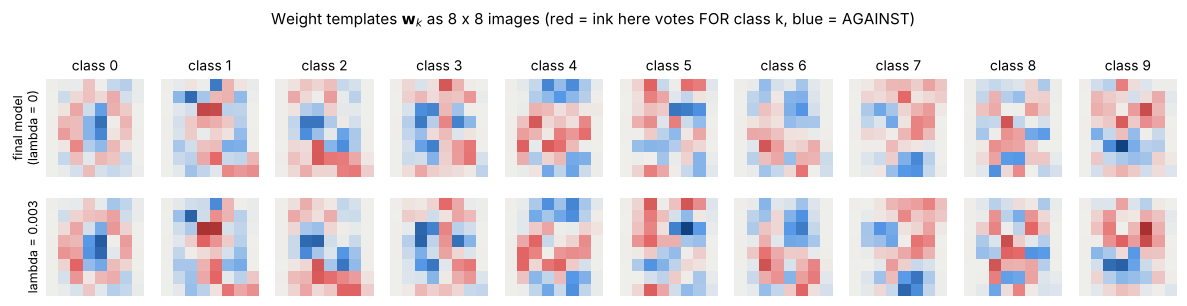

correlation of w_k with (mean image of class k - mean image of all digits): [0.94 0.79 0.84 0.77 0.76 0.76 0.91 0.8  0.77 0.69]
4 pixels are blank in every training image. All their weights are exactly 0: True
zero-sum check (Section 5.6): max |sum_k w_k| = 1.6e-14, |sum_k b_k| = 4.3e-15


In [50]:
template_models = [("final model\n(lambda = 0)", W_dig), ("lambda = 0.003", reg_runs_dig[3e-3][0])]
fig, axes = plt.subplots(2, 10, figsize=(12, 3.3))
for row, (name, W_m) in enumerate(template_models):
    vmax = np.abs(W_m).max()
    for k in range(K_DIG):
        image_panel(axes[row, k], W_m[k], cmap=DIV_CMAP, vmin=-vmax, vmax=vmax)
        if row == 0:
            axes[row, k].set_title(f"class {k}", fontsize=10)
    axes[row, 0].set_ylabel(name, fontsize=9)
fig.suptitle("Weight templates $\\mathbf{w}_k$ as 8 x 8 images (red = ink here votes FOR class k, blue = AGAINST)",
             fontsize=11)
plt.tight_layout()
plt.show()

# How closely does each template resemble "what is special about class k"?
mean_all = X_tr.mean(axis=0)
similarity = [np.corrcoef(W_dig[k], X_tr[y_tr == k].mean(axis=0) - mean_all)[0, 1] for k in range(K_DIG)]
print("correlation of w_k with (mean image of class k - mean image of all digits):", clean(np.array(similarity), 2))
blank = np.flatnonzero(X_tr.max(axis=0) == 0)
print(f"{len(blank)} pixels are blank in every training image. All their weights are exactly 0: "
      f"{bool(np.all(W_dig[:, blank] == 0))}")
print(f"zero-sum check (Section 5.6): max |sum_k w_k| = {np.abs(W_dig.sum(axis=0)).max():.1e}, "
      f"|sum_k b_k| = {abs(b_dig.sum()):.1e}")

How to read the templates:

- The **0** template is a red ring around a blue center: ink in the middle of the image is evidence *against* a
  zero, because a zero is hollow.
- The **1** template rewards a vertical stroke through the central columns.
- The **3** template is blue along the left edge, where a 3 has no ink but many other digits (0, 2, 5, 6, 8) do.

The templates are **discriminative**: they encode what *distinguishes* a class from the others, not what the class
looks like on its own. That is why each $\mathbf w_k$ correlates strongly (0.69 to 0.94) with "mean image of class $k$
minus mean image of all digits" (the part of the digit that is special) rather than with the digit itself.
Pixels that are blank in every training image receive a zero gradient forever ($x_j = 0$ in $(\mathbf p - \mathbf y)\mathbf x^\top$), so their
weights stay exactly 0: these are the white pixels at the edges of the templates. With $\lambda = 0.003$
the weights are almost three times smaller in norm (each row of the figure has its own color scale), but the
patterns are the same: the penalty shrinks the templates more than it reshapes them. And, as the last line
confirms, the weights of all classes still add up to zero, exactly as Section 5.6 predicted for a zero start.

### 8.7 Cross-checks: scikit-learn and PyTorch

**scikit-learn.** `LogisticRegression` minimizes $C\sum_i \ell_i + \frac12\lVert\mathbf W\rVert^2$ (a *sum* of losses, with the
penalty weight moved to the loss). Dividing by $CN$ gives our objective $\frac1N\sum_i\ell_i + \frac{1}{2CN}\lVert\mathbf W\rVert^2$, so

$$
\lambda = \frac{1}{C\,N} \qquad\Longleftrightarrow\qquad C = \frac{1}{\lambda N}.
$$

Like us, it does not penalize the biases. Its default solver, L-BFGS, solves the problem *exactly* (up to a
tolerance), whereas mini-batch gradient descent with a constant learning rate keeps jittering around the minimum.
So the like-for-like comparison is with our *exact* minimizer from Section 8.4 (our `loss_and_grads` + L-BFGS). We use
$\lambda = 10^{-3}$. With $\lambda = 0$ no exact minimizer exists.

In [51]:
LAM_CMP = 1e-3
W_lb, b_lb, res_lb = exact_dig[LAM_CMP]           # computed in Section 8.4
sk_dig = LogisticRegression(C=1 / (LAM_CMP * len(X_tr)), max_iter=5000, tol=1e-8).fit(X_tr, y_tr)
Wb_sgd = reg_runs_dig[LAM_CMP][:2]                 # (W, b) of our mini-batch run with the same lambda (Section 8.4)

rows = []
for name, (W_m, b_m) in [("ours: mini-batch GD, 60 epochs", Wb_sgd), ("ours: loss_and_grads + L-BFGS", (W_lb, b_lb)),
                         ("scikit-learn LogisticRegression", (sk_dig.coef_, sk_dig.intercept_))]:
    rows.append([name, loss_and_grads(X_tr, y_tr, W_m, b_m, LAM_CMP)[0], np.mean(predict(X_te, W_m, b_m) == y_te),
                 np.abs(predict_proba(X_te, W_m, b_m) - sk_dig.predict_proba(X_te)).max()])
display(pd.DataFrame(rows, columns=["model (lambda = 0.001)", "training objective", "test accuracy",
                                    "max |P - P_sklearn| on test"]).set_index("model (lambda = 0.001)").round(6))
print(f"L-BFGS iterations: ours {res_lb.nit}, scikit-learn {sk_dig.n_iter_[0]}")

,training objective,test accuracy,max |P - P_sklearn| on test
model (lambda = 0.001),,,
"ours: mini-batch GD, 60 epochs",0.308431,0.936111,0.514968
ours: loss_and_grads + L-BFGS,0.253523,0.955556,0.000796
scikit-learn LogisticRegression,0.253523,0.955556,0.000000


L-BFGS iterations: ours 128, scikit-learn 278


**PyTorch.** In PyTorch, softmax regression is a single `nn.Linear(D, K)` layer, which conveniently stores its
weight matrix with shape (out_features, in_features) = $(K, D)$, exactly like our $\mathbf W$, followed by
`nn.CrossEntropyLoss`. To check that the two implementations really do the same arithmetic, we replay our final
training run step for step: zero initialization, 64-bit floats, the same learning rate and **the same shuffles**
(we draw the permutations from a generator with the same seed).

In [52]:
def train_torch(X, y, K, eta, epochs, batch_size=32, lam=0.0, seed=SEED):
    """train_minibatch rebuilt from PyTorch parts: nn.Linear + nn.CrossEntropyLoss + torch.optim.SGD."""
    model = nn.Linear(X.shape[1], K, dtype=torch.float64)   # model.weight: (K, D), model.bias: (K,)
    nn.init.zeros_(model.weight)
    nn.init.zeros_(model.bias)
    loss_fn = nn.CrossEntropyLoss()                          # expects RAW logits and integer class labels
    optimizer = torch.optim.SGD([{"params": [model.weight], "weight_decay": lam},   # L2 on the weights only
                                 {"params": [model.bias], "weight_decay": 0.0}], lr=eta)
    X_t, y_t = torch.from_numpy(X), torch.as_tensor(y, dtype=torch.long)
    rng_mb = np.random.default_rng(seed)                     # the very same shuffles as train_minibatch
    for epoch in range(epochs):
        order = rng_mb.permutation(len(X))
        for start in range(0, len(X), batch_size):
            idx = torch.from_numpy(order[start:start + batch_size])
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[idx]), y_t[idx])        # forward: logits -> mean cross-entropy
            loss.backward()                                  # autograd computes dL/dW and dL/db
            optimizer.step()                                 # W -= eta * (grad + lam * W), b -= eta * grad
    return model


torch_model = train_torch(X_tr, y_tr, K_DIG, eta=ETA_FINAL, epochs=60, lam=LAM_BEST)
print(f"max |W_torch - W_ours| = {np.abs(torch_model.weight.detach().numpy() - W_dig).max():.1e}, "
      f"max |b_torch - b_ours| = {np.abs(torch_model.bias.detach().numpy() - b_dig).max():.1e}")
with torch.no_grad():
    acc_torch = (torch_model(torch.from_numpy(X_te)).argmax(dim=1).numpy() == y_te).mean()
print(f"test accuracy: PyTorch {acc_torch:.4f} | ours {np.mean(pred_te == y_te):.4f}")

# A classic bug: putting a softmax layer in front of CrossEntropyLoss (which applies log-softmax itself)
perfect = torch.full((1, K_DIG), -30.0, dtype=torch.float64)
perfect[0, 3] = 30.0                                          # an extremely confident, correct prediction of "3"
target = torch.tensor([3])
print(f"loss of a perfect prediction: correct usage {F.cross_entropy(perfect, target).item():.4f} | "
      f"with an extra softmax {F.cross_entropy(torch.softmax(perfect, dim=1), target).item():.4f} "
      f"(= ln(1 + 9/e) = {np.log(1 + 9 / np.e):.4f})")

max |W_torch - W_ours| = 5.8e-15, max |b_torch - b_ours| = 2.4e-15
test accuracy: PyTorch 0.9583 | ours 0.9583
loss of a perfect prediction: correct usage 0.0000 | with an extra softmax 1.4612 (= ln(1 + 9/e) = 1.4612)


Three implementations, one model:

- Our gradient plugged into L-BFGS and scikit-learn reach the same regularized minimum: the training objectives
  agree to six decimals and the test probabilities differ by less than 0.001. Our *mini-batch* run with
  the same $\lambda$ has a visibly higher objective: after 60 epochs with a constant, fairly large learning rate it is
  still jittering around the minimum rather than sitting in it. (Decaying the learning rate, or averaging the last
  iterates, removes most of that gap.)
- PyTorch, fed the same shuffles, reproduces our final weights to about $10^{-14}$, i.e. to rounding error. Every
  formula we derived by hand is exactly what the library computes with autograd.

> **Common pitfall.** `nn.CrossEntropyLoss` (and `F.cross_entropy`) expects **raw logits**: it applies log-softmax
> itself, in the stable way of Section 2.4. Adding your own softmax layer in front of it computes a softmax of
> probabilities. Training then still runs, but the loss is squeezed into a narrow range: as shown above, even a
> perfect prediction costs $\ln(1 + 9/e) \approx 1.46$ with 10 classes, and the gradients become tiny. Apply softmax
> only when you need probabilities for *reporting*. Two smaller traps: hard labels must be integer class indices of
> type `torch.long` (a float tensor is accepted only with the same shape `(N, K)` as the logits, and is then read as
> soft targets, one probability per class, as in Exercise 8. Label smoothing even has a built-in `label_smoothing`
> argument), and `weight_decay` applies to *every* parameter in the optimizer, biases included, unless you use
> parameter groups as above.

### ✏️ Exercise 11: one epoch of mini-batch gradient descent

Write `minibatch_epoch(X, y, W, b, eta, batch_size, order)` that visits the samples in the given `order`
(a permutation of $0,\dots,N-1$), cuts it into consecutive batches of `batch_size` (the last one may be smaller),
takes one gradient step per batch and returns the new `(W, b)`. Use `loss_and_grads` (no regularization) and
do not modify the input arrays in place.

In [53]:
# ✏️ Exercise 11
def minibatch_epoch(X, y, W, b, eta, batch_size, order):
    """One epoch of mini-batch gradient descent in the given sample order. Returns the new (W, b)."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex11():
    rng_t = np.random.default_rng(7)
    X, y = rng_t.normal(size=(10, 3)), rng_t.integers(0, 4, size=10)
    W0, b0 = rng_t.normal(size=(4, 3)), rng_t.normal(size=4)
    W0_copy, b0_copy = W0.copy(), b0.copy()
    W1, b1 = minibatch_epoch(X, y, W0, b0, 0.3, batch_size=10, order=np.arange(10))
    W_ref, b_ref = run_gd(X, y, W0, b0, 0.3, steps=1)
    assert np.allclose(W1, W_ref) and np.allclose(b1, b_ref), "batch_size = N must give one full-batch step"
    assert np.array_equal(W0, W0_copy) and np.array_equal(b0, b0_copy), "do not modify W and b in place"
    order = rng_t.permutation(10)
    W2, b2 = minibatch_epoch(X, y, W0, b0, 0.3, batch_size=4, order=order)
    W_ref, b_ref = W0, b0
    for chunk in (order[:4], order[4:8], order[8:]):                  # batches of 4, 4 and 2 samples
        W_ref, b_ref = run_gd(X[chunk], y[chunk], W_ref, b_ref, 0.3, steps=1)
    assert np.allclose(W2, W_ref) and np.allclose(b2, b_ref), "wrong result with batch_size = 4 (steps of 4 + 4 + 2)"

run_check("Exercise 11", _test_ex11)

⏳ Exercise 11: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def minibatch_epoch(X, y, W, b, eta, batch_size, order):
    W, b = W.copy(), b.copy()                  # never change the caller's arrays
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]  # slicing past the end simply gives a shorter last batch
        _, dW, db = loss_and_grads(X[idx], y[idx], W, b)
        W -= eta * dW
        b -= eta * db
    return W, b
```
Each step uses the parameters produced by the previous step. That is what makes it different from averaging
the batch gradients and taking one big step.
</details>

**Quick check.**
1. During mini-batch training, the loss on the current batch goes *up* from one step to the next. Is something wrong?
2. A classmate tries 200 hyperparameter settings, picks the one with the best *test* accuracy and reports 99.5%.
   What is wrong with that number?
3. You double the batch size from 32 to 64 on the 1,077 training digits. How many steps does one epoch take now, and
   by roughly what factor does the noise of each gradient estimate shrink?

<details>
<summary>Answer</summary>

1. Not necessarily. Each step follows the gradient of a *different* batch, and consecutive batches contain different
   samples, so their losses are not comparable, and even the full training loss may rise for a single step. Judge
   training by the trend of the per-epoch loss.
2. The test set was used to *choose* the model, so it is no longer an unbiased estimate: among 200 settings, some
   win partly by luck on those particular test images. Choose on a validation set (or by cross-validation) and
   report the test score of the single chosen model.
3. $\lceil 1077/64\rceil = 17$ steps instead of 34. The standard deviation of an average of $B$ independent per-sample
   gradients scales like $1/\sqrt B$, so the noise shrinks by a factor of about $\sqrt 2 \approx 1.41$.
</details>

## 9. Top-$k$ accuracy, calibration and temperature scaling

A softmax classifier outputs a whole probability distribution, not just a label. This section shows two ways to
use more of that output: scoring the *ranking* of the classes (top-$k$ accuracy), and checking whether the
probabilities mean what they say (calibration).

### 9.1 Top-$k$ accuracy

A prediction is **top-$k$ correct** if the true class is among the $k$ classes with the largest probabilities.
Top-1 accuracy is ordinary accuracy. Top-$k$ accuracy matters whenever a person or a later system picks from a
short list of suggestions: a phone keyboard offers three words, a search engine shows ten results, and image
benchmarks with a thousand classes traditionally report top-5 accuracy, because some images honestly contain
several of the classes.

In [54]:
def top_k_accuracy(P, y, k):
    """Fraction of samples whose true class is among the k largest entries of their row of P (N x K)."""
    top_k = np.argsort(-P, axis=1)[:, :k]                   # the k most probable classes of every sample
    return np.mean(np.any(top_k == y[:, None], axis=1))

rows = [[k, top_k_accuracy(P_te, y_te, k), top_k_accuracy_score(y_te, P_te, k=k)] for k in [1, 2, 3, 5]]
display(pd.DataFrame(rows, columns=["k", "top-k accuracy (ours)", "scikit-learn"]).set_index("k").round(4))

,top-k accuracy (ours),scikit-learn
k,,
1,0.9583,0.9583
2,0.9861,0.9861
3,0.9944,0.9944
5,0.9972,0.9972


On the test set the true digit is the model's first choice 95.8% of the time and among its first two choices
98.6% of the time: most mistakes are "near misses" where the right answer came second. Top-$k$ accuracy can only
grow with $k$ and reaches 1 at $k = K$.

> **Common pitfall.** A high top-5 accuracy on a 10-class problem is not impressive: guessing five classes at
> random already gives 50%. Always compare a top-$k$ score with its chance level $k/K$.

### ✏️ Exercise 12: the rank of the true class

Write `true_class_rank(P, y)` that returns, for every sample, the position of the true class when the classes
are sorted from most to least probable (1 = the model's first choice, $K$ = its last). Then the top-$k$
accuracy for *every* $k$ at once is simply `np.mean(rank <= k)`. You may assume there are no ties within a row.

In [55]:
# ✏️ Exercise 12
def true_class_rank(P, y):
    """Rank (1 = most probable) of the true class y[i] in every row P[i] of an N x K probability matrix."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex12():
    P = np.array([[0.1, 0.7, 0.2], [0.5, 0.3, 0.2], [0.25, 0.15, 0.6]])
    ranks = np.asarray(true_class_rank(P, np.array([1, 2, 1])))      # a Python list is fine too
    assert np.array_equal(ranks, [1, 3, 3]), f"expected ranks [1, 3, 3], got {ranks}"
    ranks = np.asarray(true_class_rank(P_te, y_te))
    assert ranks.shape == y_te.shape, f"expected one rank per sample, got shape {ranks.shape}"
    for k in (1, 2, 3):
        assert np.isclose(np.mean(ranks <= k), top_k_accuracy_score(y_te, P_te, k=k)), f"top-{k} accuracy disagrees"

run_check("Exercise 12", _test_ex12)

⏳ Exercise 12: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def true_class_rank(P, y):
    p_true = P[np.arange(len(y)), y]                  # probability of the true class, shape (N,)
    return 1 + np.sum(P > p_true[:, None], axis=1)    # 1 + number of classes that beat it
```
No sorting is needed: the rank of the true class is one plus the number of classes with a larger probability.
This takes $O(NK)$ operations instead of the $O(NK\log K)$ of a full sort.
</details>

### 9.2 Can we trust the probabilities? Calibration

When a weather forecaster says "70% chance of rain" on many days, it should rain on about 70% of those days. A
classifier is **calibrated** if the same holds for its confidence: among all predictions made with confidence
around 0.9, about 90% should be correct. Here the **confidence** of a prediction is the probability of the
predicted class, $\max_k p_k$.

A **reliability diagram** checks this directly. Sort the test predictions into bins by confidence
($[0.0, 0.1), [0.1, 0.2), \dots, [0.9, 1.0]$), and compare, in every bin, the average confidence with the
fraction of correct predictions. A calibrated model has points on the diagonal. The **expected calibration
error** summarizes the diagram in one number, a weighted average of the gaps:

$$
\text{ECE} = \sum_{\text{bins } m} \frac{n_m}{N}\,\Big|\,\text{accuracy}_m - \text{confidence}_m\,\Big| .
$$

We compare two digit models with almost the same test accuracy: our final model ($\eta = 2$) and the overtrained
$\eta = 32$ model from the learning-rate study.

In [56]:
def reliability_table(P, y, n_bins=10):
    """Per-bin count, mean confidence and accuracy of the predictions, plus the expected calibration error."""
    conf = P.max(axis=1)
    correct = P.argmax(axis=1) == y
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)   # bin m covers [m/n_bins, (m+1)/n_bins)
    rows = []
    for m in range(n_bins):
        in_bin = bins == m
        if in_bin.any():                                          # skip empty bins
            rows.append([m / n_bins, in_bin.sum(), conf[in_bin].mean(), correct[in_bin].mean()])
    table = pd.DataFrame(rows, columns=["bin start", "count", "mean confidence", "accuracy"])
    ece = np.sum(table["count"] / len(y) * np.abs(table["accuracy"] - table["mean confidence"]))
    return table, ece

W_over, b_over = lr_runs[32.0][:2]                       # the overconfident model from Section 8.3
logits = {"final model (eta = 2)": (X_va @ W_dig.T + b_dig, X_te @ W_dig.T + b_dig),
          "overtrained model (eta = 32)": (X_va @ W_over.T + b_over, X_te @ W_over.T + b_over)}
rows = []
for name, (Z_val, Z_test) in logits.items():
    P_test = softmax(Z_test)
    rows.append([name, np.mean(P_test.argmax(axis=1) == y_te), P_test.max(axis=1).mean(),
                 cross_entropy(Z_test, y_te), reliability_table(P_test, y_te)[1]])
display(pd.DataFrame(rows, columns=["model", "test accuracy", "mean confidence", "test cross-entropy",
                                    "ECE"]).set_index("model").round(4))

table_over, _ = reliability_table(softmax(logits["overtrained model (eta = 32)"][1]), y_te)
print("reliability table of the overtrained model on the test set:")
display(table_over.round(3))

,test accuracy,mean confidence,test cross-entropy,ECE
model,,,,
final model (eta = 2),0.9583,0.9547,0.1192,0.0207
overtrained model (eta = 32),0.9583,0.9930,0.5838,0.0396


reliability table of the overtrained model on the test set:


,bin start,count,mean confidence,accuracy
0,0.4,1,0.431,1.000
1,0.6,1,0.682,1.000
2,0.7,3,0.766,0.000
3,0.8,4,0.849,0.500
4,0.9,351,0.999,0.972


Both models classify the same share of test digits correctly (95.8%), but they *talk* very differently. The
overtrained model's average confidence is 0.993: it claims to be right 99.3% of the time while being right
95.8% of the time, and its cross-entropy is about five times larger (0.584 vs 0.119), because most of its
mistakes are made with near-certainty: 10 of its 15 errors have confidence above 0.9 (the last row of the table:
351 predictions, 97.2% correct). The final model's average confidence, 0.955, is close to its accuracy.

Accuracy cannot see any of this. Cross-entropy and calibration can, and they matter whenever probabilities
drive decisions: "send the low-confidence digits to a human", "only act if the model is 99% sure", or
combining the classifier's output with other evidence through Bayes' rule.

### 9.3 Temperature scaling

Recall the temperature from Section 2.2: $\operatorname{softmax}(\mathbf z / T)$ with $T > 1$ flattens the probabilities and $T < 1$
sharpens them, while the **ranking of the classes never changes** (dividing by a positive number preserves the
order of the logits). That makes temperature the perfect *post-hoc* calibration knob:

1. train the model as usual.
2. on the **validation** set, find the single number $T > 0$ that minimizes the cross-entropy of $\operatorname{softmax}(\mathbf z/T)$.
3. from now on report $\operatorname{softmax}(\mathbf z/T)$.

Accuracy, top-$k$ accuracy and the confusion matrix are untouched. Only the confidence is rescaled. Because there
is just one parameter, a few hundred validation samples are plenty, and overfitting the validation set is hardly
possible. We optimize over $\log T$ so that $T$ stays positive automatically.

In [57]:
def fit_temperature(Z_val, y_val):
    """Temperature T > 0 minimizing the cross-entropy of softmax(Z_val / T) (a 1-D search over log T)."""
    result = minimize_scalar(lambda log_T: cross_entropy(Z_val / np.exp(log_T), y_val),
                             bounds=(-4.0, 4.0), method="bounded")
    return float(np.exp(result.x))

rows, temperatures = [], {}
for name, (Z_val, Z_test) in logits.items():
    T = temperatures[name] = fit_temperature(Z_val, y_va)
    P_before, P_after = softmax(Z_test), softmax(Z_test / T)
    rows.append([name, T, cross_entropy(Z_val, y_va), cross_entropy(Z_val / T, y_va),
                 cross_entropy(Z_test, y_te), cross_entropy(Z_test / T, y_te),
                 reliability_table(P_before, y_te)[1], reliability_table(P_after, y_te)[1],
                 np.mean(P_before.argmax(1) == y_te), np.mean(P_after.argmax(1) == y_te)])
cols = pd.MultiIndex.from_tuples([("", "T"), ("val CE", "before"), ("val CE", "after"), ("test CE", "before"),
                                  ("test CE", "after"), ("test ECE", "before"), ("test ECE", "after"),
                                  ("test acc", "before"), ("test acc", "after")])
display(pd.DataFrame([r[1:] for r in rows], columns=cols, index=[r[0] for r in rows]).round(4))

val CE         test CE         test ECE         test acc        
                                   T before   after  before   after   before   after   before   after
final model (eta = 2)         0.9165  0.112  0.1112  0.1192  0.1186   0.0207  0.0190   0.9583  0.9583
overtrained model (eta = 32)  6.3760  0.559  0.1443  0.5838  0.1516   0.0396  0.0128   0.9583  0.9583

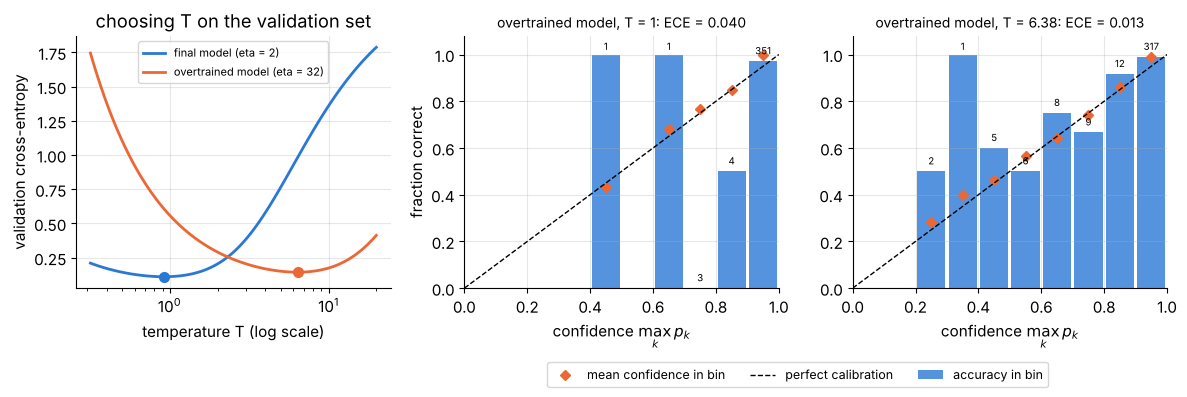

In [58]:
T_grid = np.logspace(-0.5, 1.3, 120)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for (name, (Z_val, _)), color in zip(logits.items(), CLASS_COLORS):
    axes[0].plot(T_grid, [cross_entropy(Z_val / T, y_va) for T in T_grid], color=color, lw=2, label=name)
    T_opt = temperatures[name]
    axes[0].plot(T_opt, cross_entropy(Z_val / T_opt, y_va), "o", color=color, ms=7)
axes[0].set_xscale("log")
axes[0].set_xlabel("temperature T (log scale)")
axes[0].set_ylabel("validation cross-entropy")
axes[0].set_title("choosing T on the validation set")
axes[0].legend(fontsize=8)

Z_test_over = logits["overtrained model (eta = 32)"][1]
T_over = temperatures["overtrained model (eta = 32)"]
for ax, P, title in [(axes[1], softmax(Z_test_over), "overtrained model, T = 1"),
                     (axes[2], softmax(Z_test_over / T_over), f"overtrained model, T = {T_over:.2f}")]:
    table, ece = reliability_table(P, y_te)
    centers = table["bin start"] + 0.05
    ax.bar(centers, table["accuracy"], width=0.09, color=CLASS_COLORS[0], alpha=0.8, label="accuracy in bin")
    ax.plot(centers, table["mean confidence"], "D", color=CLASS_COLORS[1], ms=5, label="mean confidence in bin")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    for c, n, acc in zip(centers, table["count"], table["accuracy"]):
        ax.text(c, min(acc + 0.03, 1.02), str(n), ha="center", fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("confidence $\\max_k p_k$")
    ax.set_title(f"{title}: ECE = {ece:.3f}", fontsize=10)
axes[1].set_ylabel("fraction correct")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.67, 0.0))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Reading the results (the small numbers above the bars are the bin counts):

- For the **overtrained** model the validation set asks for a large temperature, $T \approx 6.4$: its logits are
  about six times too large. Dividing by $T$ cuts the test cross-entropy from 0.584 to 0.152 and the ECE from about
  0.040 to 0.013, while the test accuracy stays exactly the same. Before scaling, almost all predictions sit in the
  last bin. Afterwards they spread out over the bins, and the uncertain predictions are honestly labeled as such.
- The **final** model was already well calibrated. Its optimal temperature is slightly *below* one ($T \approx 0.92$),
  meaning it was, if anything, a little underconfident. The improvements are tiny.
- A caveat: with only 360 test digits, most bins hold just a handful of predictions, so the ECE itself is a
  noisy estimate. Cross-entropy on held-out data is the more reliable single number.

> **Going deeper.** Large neural networks trained with cross-entropy are often overconfident, for the same
> reason as our $\eta = 32$ model: the loss rewards ever larger logits on training data that the network can
> fit perfectly. Temperature scaling, fitted on a validation set exactly as above, is the standard first remedy
> (see the paper by Guo et al. in *Going further*). Label smoothing (Exercise 8) attacks the same problem during
> training.

### ✏️ Exercise 13: the gradient for temperature scaling

Write the scaled logits as $\beta\mathbf z$ with $\beta = 1/T$. Show that the derivative of the mean cross-entropy
$\mathcal L(\beta) = -\frac1N\sum_i \log\operatorname{softmax}(\beta\mathbf z_i)_{y_i}$ is

$$
\frac{d\mathcal L}{d\beta} = \frac1N\sum_{i=1}^{N} (\mathbf p_i - \mathbf y_i)^\top\mathbf z_i ,
\qquad \mathbf p_i = \operatorname{softmax}(\beta\mathbf z_i),
$$

(hint: chain rule with $\partial\ell/\partial(\beta\mathbf z) = \mathbf p - \mathbf y$), then implement `ce_and_dbeta(Z, y, beta)` returning the
pair $(\mathcal L(\beta),\ d\mathcal L/d\beta)$. The checker compares with finite differences and confirms that the
derivative is zero at $\beta = 1/T$ for the temperature found above.

In [59]:
# ✏️ Exercise 13
def ce_and_dbeta(Z, y, beta):
    """Mean cross-entropy of softmax(beta * Z) for labels y, and its derivative with respect to beta."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex13():
    Z_val_over = logits["overtrained model (eta = 32)"][0]
    for beta in (0.05, 0.3, 1.0):
        loss, grad = ce_and_dbeta(Z_val_over, y_va, beta)
        assert np.isclose(loss, cross_entropy(beta * Z_val_over, y_va)), f"wrong loss at beta = {beta}"
        h = 1e-6
        fd = (cross_entropy((beta + h) * Z_val_over, y_va) - cross_entropy((beta - h) * Z_val_over, y_va)) / (2 * h)
        assert np.isclose(grad, fd, rtol=1e-4, atol=1e-7), f"at beta = {beta}: got {grad}, finite differences {fd}"
    _, grad_opt = ce_and_dbeta(Z_val_over, y_va, 1 / temperatures["overtrained model (eta = 32)"])
    assert abs(grad_opt) < 1e-3, f"the derivative should vanish at the optimal temperature, got {grad_opt}"

run_check("Exercise 13", _test_ex13)

⏳ Exercise 13: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ce_and_dbeta(Z, y, beta):
    S = beta * Z                                          # scaled logits
    P = softmax(S)
    Y = one_hot(y, Z.shape[1])
    loss = cross_entropy(S, y)
    grad = np.mean(np.sum((P - Y) * Z, axis=1))           # (1/N) sum_i (p_i - y_i)^T z_i
    return loss, grad
```
Each sample's loss depends on $\beta$ only through $\mathbf s_i = \beta\mathbf z_i$, and $d\mathbf s_i/d\beta = \mathbf z_i$, so the chain rule gives
$(\partial\ell_i/\partial\mathbf s_i)^\top\mathbf z_i = (\mathbf p_i - \mathbf y_i)^\top\mathbf z_i$. In words: $\mathbf p_i^\top\mathbf z_i$ is the logit the model *expects*
under its own probabilities and $z_{i,y_i}$ the logit of the truth. At the optimal temperature the two agree on
average. With this derivative you could find $T$ by Newton's method or plain gradient descent instead of
`minimize_scalar`.
</details>

**Quick check.**
1. A model has 90% test accuracy and an average confidence of 0.99. Is it over- or underconfident, and would
   temperature scaling choose $T > 1$ or $T < 1$?
2. Why must the temperature be fitted on the validation set rather than on the training set?
3. Can temperature scaling repair a model that ranks the classes in the wrong order?

<details>
<summary>Answer</summary>

1. Overconfident: it claims 99% but delivers 90%. Its probabilities must be softened, so $T > 1$.
2. On the training set the model already looks (nearly) perfect (the training digits are even separable), so the
   best training temperature would *sharpen* the predictions ($T < 1$). Overconfidence only shows up on data the
   model has not been fitted to.
3. No. Dividing the logits by $T > 0$ never changes their order, so the ranking, the accuracy and the top-$k$
   accuracy stay the same. Temperature scaling fixes *how sure* the model is, not *what* it predicts.
</details>

## 10. More practice: the wine dataset

Our last dataset is small and tabular: 178 wines from three different grape cultivars (the classes 0, 1, 2), each
described by 13 chemical measurements such as alcohol content, color intensity and proline (an amino acid). It
is a good place to practice the one preprocessing step we have skipped so far, because its features live on
wildly different scales.

In [60]:
wine = load_wine()
X_wine, y_wine = wine.data, wine.target
print(f"X: {X_wine.shape}, wines per class: {np.bincount(y_wine)}")
feature_ranges = pd.DataFrame({"min": X_wine.min(axis=0), "max": X_wine.max(axis=0), "std": X_wine.std(axis=0)},
                              index=wine.feature_names)
display(feature_ranges.round(2))

Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_wine, y_wine, test_size=0.25, stratify=y_wine, random_state=SEED)
print(f"train {Xw_tr.shape}, test {Xw_te.shape}")

X: (178, 13), wines per class: [59 71 48]


,min,max,std
alcohol,11.03,14.83,0.81
malic_acid,0.74,5.80,1.11
ash,1.36,3.23,0.27
alcalinity_of_ash,10.60,30.00,3.33
magnesium,70.00,162.00,14.24
total_phenols,0.98,3.88,0.62
flavanoids,0.34,5.08,1.00
nonflavanoid_phenols,0.13,0.66,0.12
proanthocyanins,0.41,3.58,0.57
color_intensity,1.28,13.00,2.31


train (133, 13), test (45, 13)


Proline ranges from about 280 to 1,680, while hue stays between 0.5 and 1.7. Why does that hurt gradient
descent? The gradient for a weight is $\frac1N\sum_i (p_{ik} - y_{ik})\,x_{ij}$, so it is proportional to the size of feature $j$.
A learning rate small enough for the proline weight (huge gradients) is far too small for the hue weight (tiny
gradients). In the language of Section 5.7: the largest eigenvalue of $\frac1N\tilde{\mathbf X}^\top\tilde{\mathbf X}$ is dominated by proline, and
the safe learning rate collapses.

The cure is **standardization**: shift and scale every feature to mean 0 and standard deviation 1,

$$
x'_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j},
$$

where $\mu_j$ and $\sigma_j$ are computed **on the training set only** and then applied unchanged to the test set (and to
any future wine). Computing them on all data would let information about the test set leak into the
preprocessing.

In [61]:
def safe_learning_rate(X):
    """4 / lambda_max((1/N) [X 1]^T [X 1]): the full-batch learning-rate bound of Section 5.7."""
    X_aug = np.column_stack([X, np.ones(len(X))])
    return 4 / np.linalg.eigvalsh(X_aug.T @ X_aug / len(X)).max()

mu_w, sigma_w = Xw_tr.mean(axis=0), Xw_tr.std(axis=0)     # statistics of the TRAINING set only
Xw_tr_std = (Xw_tr - mu_w) / sigma_w
Xw_te_std = (Xw_te - mu_w) / sigma_w                     # the test set reuses the training statistics
print(f"safe learning rate: raw features eta < {safe_learning_rate(Xw_tr):.2e} | "
      f"standardized eta < {safe_learning_rate(Xw_tr_std):.3f}")
print("test-set means after standardization (close to, but not exactly, 0):", clean(Xw_te_std.mean(axis=0)[:5], 2), "...")

EPOCHS_WINE, LAM_WINE = 3_000, 0.01
record_wine = np.unique(np.round(np.logspace(0, np.log10(EPOCHS_WINE), 80)).astype(int))
W_wraw, b_wraw, hist_wraw = train_batch_gd(Xw_tr, yw_tr, K=3, eta=0.9 * safe_learning_rate(Xw_tr),
                                           epochs=EPOCHS_WINE, lam=LAM_WINE, record=record_wine)
W_wstd, b_wstd, hist_wstd = train_batch_gd(Xw_tr_std, yw_tr, K=3, eta=0.9 * safe_learning_rate(Xw_tr_std),
                                           epochs=EPOCHS_WINE, lam=LAM_WINE, record=record_wine)
for name, (W_m, b_m, X_train_m, X_test_m) in {"raw features": (W_wraw, b_wraw, Xw_tr, Xw_te),
                                               "standardized": (W_wstd, b_wstd, Xw_tr_std, Xw_te_std)}.items():
    print(f"{name:>13}: training objective {loss_and_grads(X_train_m, yw_tr, W_m, b_m, LAM_WINE)[0]:.4f}, "
          f"train accuracy {np.mean(predict(X_train_m, W_m, b_m) == yw_tr):.3f}, "
          f"test accuracy {np.mean(predict(X_test_m, W_m, b_m) == yw_te):.3f}")

sk_wine = LogisticRegression(C=1 / (LAM_WINE * len(Xw_tr)), max_iter=5000, tol=1e-10).fit(Xw_tr_std, yw_tr)
print(f"scikit-learn on the standardized data: training objective "
      f"{loss_and_grads(Xw_tr_std, yw_tr, sk_wine.coef_, sk_wine.intercept_, LAM_WINE)[0]:.4f}, "
      f"test accuracy {sk_wine.score(Xw_te_std, yw_te):.3f}, max |P_ours - P_sklearn| on test "
      f"{np.abs(predict_proba(Xw_te_std, W_wstd, b_wstd) - sk_wine.predict_proba(Xw_te_std)).max():.1e}")

safe learning rate: raw features eta < 6.06e-06 | standardized eta < 0.861
test-set means after standardization (close to, but not exactly, 0): [ 0.16  0.01 -0.02 -0.24 -0.07] ...


 raw features: training objective 0.6504, train accuracy 0.722, test accuracy 0.756
 standardized: training objective 0.0854, train accuracy 1.000, test accuracy 1.000


scikit-learn on the standardized data: training objective 0.0854, test accuracy 1.000, max |P_ours - P_sklearn| on test 1.6e-07


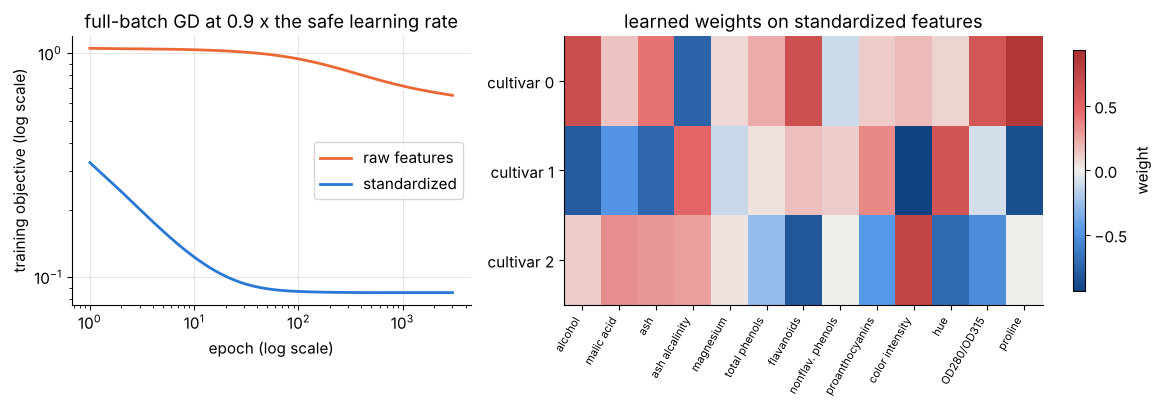

cultivar 0: largest weights proline (+0.86), alcohol (+0.67) | most negative alcalinity_of_ash (-0.75), nonflavanoid_phenols (-0.11)
cultivar 1: largest weights hue (+0.62), alcalinity_of_ash (+0.48) | most negative color_intensity (-0.94), proline (-0.87)
cultivar 2: largest weights color_intensity (+0.76), malic_acid (+0.33) | most negative flavanoids (-0.82), hue (-0.71)


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
for hist, name, color in [(hist_wraw, "raw features", CLASS_COLORS[1]), (hist_wstd, "standardized", CLASS_COLORS[0])]:
    epochs_m = sorted(hist)
    axes[0].plot(epochs_m, [hist[e][2] for e in epochs_m], color=color, lw=2, label=name)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch (log scale)")
axes[0].set_ylabel("training objective (log scale)")
axes[0].set_title("full-batch GD at 0.9 x the safe learning rate")
axes[0].legend()

vmax = np.abs(W_wstd).max()
im = axes[1].imshow(W_wstd, cmap=DIV_CMAP, vmin=-vmax, vmax=vmax, aspect="auto")
short_names = ["alcohol", "malic acid", "ash", "ash alcalinity", "magnesium", "total phenols", "flavanoids",
               "nonflav. phenols", "proanthocyanins", "color intensity", "hue", "OD280/OD315", "proline"]
axes[1].set_xticks(range(len(short_names)), short_names, rotation=60, ha="right", fontsize=8)
axes[1].set_yticks(range(3), [f"cultivar {k}" for k in range(3)])
axes[1].grid(False)
axes[1].set_title("learned weights on standardized features")
fig.colorbar(im, ax=axes[1], shrink=0.9, label="weight")
plt.tight_layout()
plt.show()

for k in range(3):
    order_k = np.argsort(W_wstd[k])
    print(f"cultivar {k}: largest weights {', '.join(f'{wine.feature_names[j]} ({W_wstd[k, j]:+.2f})' for j in order_k[::-1][:2])}"
          f" | most negative {', '.join(f'{wine.feature_names[j]} ({W_wstd[k, j]:+.2f})' for j in order_k[:2])}")

The comparison is stark. Both runs use 3,000 full-batch epochs at 90% of their own safe learning rate. On the raw
features that rate is about $6\times 10^{-6}$, and after 3,000 epochs the model is still poor (training objective 0.65,
test accuracy 0.756): the weights of the small-scale features have barely moved. After standardization the safe
rate is about 0.86, and the same budget reaches the exact minimum: scikit-learn's solution agrees to about
$10^{-7}$, with 100% accuracy on the 45 test wines.

Standardization changes the *optimization*, not the *model*: any linear function of the standardized features is
also a linear function of the raw features (the weights absorb the $1/\sigma_j$ and the bias absorbs the shifts), so
without regularization both versions can represent exactly the same classifiers. (With L2 regularization the two
are slightly different problems, since the penalty sees differently scaled weights, one more reason to put the
features on a common scale first.)

The heatmap is now interpretable *because* all features share one scale: a weight of +1 means "one standard
deviation more of this feature adds 1 to the logit of this cultivar". Reading the printout: cultivar 0 is favored
by high proline and high alcohol, cultivar 1 by low color intensity and low proline, and cultivar 2 by high color
intensity together with low flavanoids and low hue. Since only differences between the rows matter (Section 3.3),
read each column as "which cultivar does this feature favor relative to the others?".

### ✏️ Exercise 14: standardize with training statistics only

Write `standardize(X_train, X_other)` that returns the pair `(X_train_std, X_other_std)`: every column of
`X_train` is shifted and scaled to mean 0 and standard deviation 1 using **its own** mean and standard deviation,
and `X_other` is transformed with the **same** numbers. A column that is constant in the training set (standard
deviation 0) should only be shifted, not divided by zero. Use the population standard deviation
`X_train.std(axis=0)` (`ddof=0`, as in Section 10 and in scikit-learn's `StandardScaler`). The checker also accepts
the sample standard deviation (`ddof=1`, the default of pandas).

In [63]:
# ✏️ Exercise 14
def standardize(X_train, X_other):
    """Standardize X_train column by column and apply the same transformation to X_other."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test_ex14():
    A = np.array([[1.0, 10.0, 5.0], [3.0, 30.0, 5.0], [5.0, 20.0, 5.0]])     # the last column is constant
    B = np.array([[3.0, 40.0, 7.0]])
    A_copy, B_copy = A.copy(), B.copy()
    A_std, B_std = standardize(A, B)
    A_std, B_std = np.asarray(A_std, dtype=float), np.asarray(B_std, dtype=float)
    assert np.array_equal(A, A_copy) and np.array_equal(B, B_copy), "do not modify the inputs in place"
    assert np.all(np.isfinite(A_std)) and np.all(np.isfinite(B_std)), "a constant column must not produce inf/nan"
    assert np.allclose(A_std.mean(axis=0), 0), "training columns must have mean 0"
    pop_ok = np.allclose(A_std.std(axis=0, ddof=0)[:2], 1)        # population standard deviation 1 ...
    sample_ok = np.allclose(A_std.std(axis=0, ddof=1)[:2], 1)     # ... or sample standard deviation 1
    assert pop_ok or sample_ok, "non-constant training columns must have standard deviation 1"
    ddof = 0 if pop_ok else 1
    sd = A.std(axis=0, ddof=ddof)
    B_ref = (B - A.mean(axis=0)) / np.where(sd > 0, sd, 1.0)       # constant column: shift only
    assert np.allclose(B_std, B_ref), f"use the TRAINING mean and std for X_other, got {B_std}"
    sd_w = Xw_tr.std(axis=0, ddof=ddof)                            # ddof = 0 gives Xw_tr_std, Xw_te_std of Section 10
    wine_tr, wine_te = standardize(Xw_tr.copy(), Xw_te.copy())
    assert np.allclose(wine_tr, (Xw_tr - mu_w) / sd_w) and np.allclose(wine_te, (Xw_te - mu_w) / sd_w), \
        "disagrees on the wine data"

run_check("Exercise 14", _test_ex14)

⏳ Exercise 14: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def standardize(X_train, X_other):
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma = np.where(sigma > 0, sigma, 1.0)     # constant column: shift only
    return (X_train - mu) / sigma, (X_other - mu) / sigma
```
The statistics come from the training rows only. The test rows are transformed with exactly the same `mu` and
`sigma`, so the test set stays truly "unseen". scikit-learn's `StandardScaler` does the same thing (`fit` on the
training set, `transform` on everything else), including the special case of constant columns.
</details>

**Quick check.**
1. You standardize the wine features with the mean and standard deviation of *all* 178 wines, and only then split
   into training and test sets. What is the problem?
2. One feature is converted from grams to kilograms (divided by 1,000). Without regularization, do the predictions
   of the fitted softmax regression change? And with L2 regularization?
3. Why do the weights become comparable across features only after standardization?

<details>
<summary>Answer</summary>

1. Information about the test wines leaks into the preprocessing: the transformation applied to the training data
   depends on the test data. The effect is small here, but the reported test score is no longer that of a truly
   untouched test set, and with time series or tiny datasets the leak can be serious.
2. Without regularization, no: the weight of that feature can simply become 1,000 times larger, giving exactly the
   same logits (gradient descent may need far longer to get there, though). With L2 regularization, yes: the penalty
   $\frac\lambda2 w^2$ now charges a million times more for the same effect, so the optimum uses that feature less.
3. A weight converts "one unit of the feature" into logit points, and the units differ (degrees, milligrams,
   dimensionless ratios). After standardization one unit is one standard deviation for every feature, so equal
   weights mean equal influence for a typical change of the feature.
</details>

## 11. Quiz

Twelve exam-style questions. Try each one with pen and paper before opening the answer. Useful values:
$e \approx 2.718$, $e^2 \approx 7.389$, $\ln 2 \approx 0.693$, $\ln 4 \approx 1.386$.

**Q1.** A 3-class model outputs the logits $\mathbf z = (2,\ 1,\ 0)$. Its predicted probabilities are approximately

- (A) $(0.667,\ 0.333,\ 0.000)$
- (B) $(0.665,\ 0.245,\ 0.090)$
- (C) $(0.881,\ 0.731,\ 0.500)$
- (D) $(0.090,\ 0.245,\ 0.665)$

<details>
<summary>Answer</summary>

**(B).** $e^2 + e^1 + e^0 \approx 7.389 + 2.718 + 1 = 11.107$, so $\mathbf p \approx (7.389,\ 2.718,\ 1)/11.107 = (0.665,\ 0.245,\ 0.090)$.
(A) divides the logits by their sum: logits are not probabilities, and this recipe breaks for negative logits.
(C) applies a sigmoid to each logit separately (the one-vs-rest mistake of Section 1.3). These numbers sum to 2.11.
(D) has the right numbers in the wrong order: softmax is *increasing* in each logit, so the largest logit gets the
largest probability.
</details>

**Q2.** What is $\operatorname{softmax}(1001,\ 1000,\ 1000)$?

- (A) about $(0.3337,\ 0.3332,\ 0.3332)$, because the logits are almost equal in relative terms
- (B) about $(0.576,\ 0.212,\ 0.212)$
- (C) exactly $(1,\ 0,\ 0)$
- (D) undefined, because $e^{1001}$ overflows

<details>
<summary>Answer</summary>

**(B).** Softmax is shift invariant: subtracting 1000 from every logit gives $\operatorname{softmax}(1, 0, 0) = (e,\ 1,\ 1)/(e + 2) \approx (0.576,\ 0.212,\ 0.212)$.
Only *differences* of logits matter, not their ratios, so (A) is wrong. (C) would require an infinite gap between
the logits. (D) confuses the mathematical function with a naive implementation: the value is perfectly defined,
and the stable implementation (subtract the maximum first, Section 2.4) computes it without overflow.
</details>

**Q3.** A softmax regression model with one feature and $K = 3$ classes starts from $\mathbf W = \mathbf 0$ (a $3\times 1$ matrix)
and $\mathbf b = \mathbf 0$. It takes **one** gradient-descent step with learning rate $\eta = 0.3$ on the single training sample
$x = 2$ with label $y = 0$ (no regularization). After the step,

- (A) $\mathbf W = (0.4,\ -0.2,\ -0.2)^\top$, $\mathbf b = (0.2,\ -0.1,\ -0.1)$
- (B) $\mathbf W = (-0.4,\ 0.2,\ 0.2)^\top$, $\mathbf b = (-0.2,\ 0.1,\ 0.1)$
- (C) $\mathbf W = (0.6,\ 0,\ 0)^\top$, $\mathbf b = (0.3,\ 0,\ 0)$
- (D) $\mathbf W = (0.2,\ -0.1,\ -0.1)^\top$, $\mathbf b = (0.2,\ -0.1,\ -0.1)$

<details>
<summary>Answer</summary>

**(A).** All logits are 0, so $\mathbf p = (\frac13, \frac13, \frac13)$ and $\mathbf p - \mathbf y = (-\frac23, \frac13, \frac13)$. Then
$\nabla_{\mathbf W}\ell = (\mathbf p - \mathbf y)\,x = (-\frac43, \frac23, \frac23)^\top$ and $\nabla_{\mathbf b}\ell = (-\frac23, \frac13, \frac13)$. Subtracting $0.3$ times these gives (A).
(B) moves *along* the gradient (gradient ascent), which makes the loss larger. (C) uses $-\mathbf y$ instead of $\mathbf p - \mathbf y$,
forgetting that the step also pushes the wrong classes *down*. (D) forgets to multiply the weight gradient by
$x = 2$. Notice in (A) that both $\mathbf W$ and $\mathbf b$ still sum to zero over the classes, as Section 5.6 predicts.
</details>

**Q4.** A softmax regression model for 10 classes uses 64 input features. How many numbers does it store in $\mathbf W$ and $\mathbf b$?

- (A) 640
- (B) 650
- (C) 585
- (D) 74

<details>
<summary>Answer</summary>

**(B).** $\mathbf W$ is $K\times D = 10\times 64$ (640 numbers) and $\mathbf b$ has $K = 10$ entries: $K(D+1) = 650$.
(A) forgets the biases. (C) $= 9\cdot 65$ is the number of parameters that actually matter: because adding the
same vector to every row of $\mathbf W$ (and the same number to every bias) changes nothing, one class can be fixed as a
reference with all-zero parameters (Section 3.3). But the model as usually implemented stores all 650.
(D) $= 64 + 10$ would give each class a single number, not a weight per feature.
</details>

**Q5.** For $K = 2$ with logits $z_0, z_1$, the softmax probability of class 1 equals

- (A) $\sigma(z_1)$
- (B) $\sigma(z_1 - z_0)$
- (C) $\sigma(z_0 + z_1)$
- (D) $\sigma(z_1)\,/\,(\sigma(z_0) + \sigma(z_1))$

<details>
<summary>Answer</summary>

**(B).** $\dfrac{e^{z_1}}{e^{z_0} + e^{z_1}} = \dfrac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0)$: two-class softmax regression *is* logistic regression with
$\mathbf w = \mathbf w_1 - \mathbf w_0$ and $b = b_1 - b_0$ (Section 2.3). (A) ignores the competing class. It is only correct if $z_0 = 0$.
(C) depends on the sum of the logits, but softmax only depends on their difference. (D) renormalizes two
independent sigmoids. That sums to 1, but it is a different function (try $z_0 = z_1 + 10$, both large).
</details>

**Q6.** On a test set of 100 images, a model assigns probability exactly 0.25 to the correct class of every
image. Its mean categorical cross-entropy (natural logarithm) is

- (A) 0.25
- (B) 0.75
- (C) about 1.386
- (D) 2

<details>
<summary>Answer</summary>

**(C).** Each sample costs $-\ln 0.25 = \ln 4 \approx 1.386$, and so does their mean. (A) and (B) confuse the loss with
a probability or with "1 minus the probability". (D) is $\log_2 4$: the same quantity measured in *bits*. Machine
learning libraries use the natural logarithm (nats), so the answer is 1.386 there.
</details>

**Q7.** For a single sample with one-hot label $\mathbf y$, predicted probabilities $\mathbf p = \operatorname{softmax}(\mathbf z)$ and loss
$\ell = -\sum_k y_k \log p_k$, the gradient $\partial\ell/\partial\mathbf z$ is

- (A) $\mathbf y - \mathbf p$
- (B) $\mathbf p - \mathbf y$
- (C) $-\mathbf y / \mathbf p$ (elementwise)
- (D) $\operatorname{diag}(\mathbf p) - \mathbf p\mathbf p^\top$

<details>
<summary>Answer</summary>

**(B).** Section 5.4 derived it twice: via the Jacobian, and directly from $\ell = \operatorname{LSE}(\mathbf z) - z_y$. (A) has the wrong sign.
Stepping along it would *increase* the loss. (C) is the gradient with respect to the *probabilities* $\mathbf p$, one
step earlier in the chain rule. (D) is the Jacobian of the softmax itself, $\partial\mathbf p/\partial\mathbf z$. Multiplying its transpose by
(C) gives (B).
</details>

**Q8.** With samples stored as rows ($\mathbf X$ is $N\times D$, and $\mathbf P$ and $\mathbf Y$ are $N\times K$) and $\mathbf W$ of shape $K\times D$, the gradient of the
mean cross-entropy with respect to $\mathbf W$ is

- (A) $\frac1N(\mathbf P - \mathbf Y)^\top\mathbf X$
- (B) $\frac1N\mathbf X^\top(\mathbf P - \mathbf Y)$
- (C) $\frac1N(\mathbf P - \mathbf Y)\,\mathbf X$
- (D) $\frac1N\mathbf X^\top\mathbf X\,(\mathbf P - \mathbf Y)$

<details>
<summary>Answer</summary>

**(A).** It has shape $(K\times N)(N\times D) = K\times D$, the shape of $\mathbf W$, and it is the average of the per-sample outer products
$(\mathbf p_i - \mathbf y_i)\mathbf x_i^\top$. (B) is its transpose, $D\times K$, the right answer if you store the weights as a $D\times K$ matrix
(as many libraries do), but not for our $\mathbf W$. (C) multiplies an $N\times K$ by an $N\times D$ matrix, which is undefined unless $K = N$.
(D) is shape-incompatible as well and looks like a mix-up with the normal equations of linear regression.
Checking shapes catches most gradient bugs before any test is run.
</details>

**Q9.** The training set is linearly separable, and full-batch gradient descent without regularization runs
forever with a small, safe learning rate. What happens?

- (A) It converges to finite weights with training loss exactly 0.
- (B) The training loss decreases toward 0 without reaching it, and $\lVert\mathbf W\rVert$ grows without bound.
- (C) The loss diverges to $+\infty$.
- (D) The weights stop changing as soon as the training accuracy reaches 100%.

<details>
<summary>Answer</summary>

**(B).** Scaling up a separating solution always lowers the loss, but every softmax probability is strictly below
1, so the loss is never exactly 0 (Section 6.7) and no finite minimizer exists. (A) is impossible. (C) cannot
happen: with a safe learning rate each step lowers the loss. (D) is wrong because the gradient $\frac1N\sum_i(\mathbf p_i - \mathbf y_i)\mathbf x_i^\top$
is not zero while the probabilities are below 1: correct predictions are still pushed toward more confidence.
The *direction* of $\mathbf W$ does converge, to a maximum-margin solution.
</details>

**Q10.** A digit classifier labels 40 test images as "7", and 36 of those really are 7s. The test set contains 45
sevens in total. The precision and recall of class 7 are

- (A) precision 0.9, recall 0.8
- (B) precision 0.8, recall 0.9
- (C) precision 0.9, recall 0.9
- (D) precision 36/85, recall 36/85

<details>
<summary>Answer</summary>

**(A).** Precision $= 36/40 = 0.9$ (of the "7" predictions, how many are right). Recall $= 36/45 = 0.8$ (of the real 7s,
how many were found). (B) swaps the two definitions. (C) uses the same denominator twice. (D) divides by the
number of predicted *plus* actual 7s, which is not a standard metric (though $2\cdot 36/85 \approx 0.847$ is exactly the F1 score).
</details>

**Q11.** In PyTorch, a model ends with `nn.Softmax(dim=1)` and is trained with `nn.CrossEntropyLoss()`. What happens?

- (A) PyTorch raises an error, because the loss detects that the inputs are probabilities.
- (B) Training runs, but the loss is computed on a softmax *of probabilities*: it cannot get close to 0 and the
  gradients are weakened.
- (C) Nothing changes: applying softmax twice is the same as applying it once.
- (D) The loss becomes negative, because the log of a probability is negative.

<details>
<summary>Answer</summary>

**(B).** `CrossEntropyLoss` treats its input as logits and applies log-softmax itself. Feeding it probabilities in
$[0, 1]$ means the "logits" differ by at most 1, so even a perfect prediction costs $\ln(1 + (K-1)/e)$, which is 1.46
for $K = 10$ (Section 8.7). (A): no check of that kind exists. (C): softmax is not idempotent. The softmax of a
one-hot vector is far from one-hot. (D): cross-entropy is never negative, since it is minus the log of a number at
most 1.
</details>

**Q12.** Temperature scaling with $T = 3$, fitted on a validation set, is applied to a trained classifier. Which of
these can change on the test set?

- (A) the accuracy
- (B) the top-3 accuracy
- (C) the confusion matrix
- (D) the cross-entropy

<details>
<summary>Answer</summary>

**(D).** Dividing all logits of a sample by the same positive number keeps their order, so the predicted class,
the ranking of all classes and therefore (A), (B) and (C) stay exactly the same. Only the probabilities move,
toward uniform for $T > 1$, and with them the cross-entropy and the calibration error. That is precisely why
temperature scaling is safe to apply after training.
</details>

## 12. Summary and going further

**The model in one table**

| What | Formula | Shapes / remarks |
|---|---|---|
| logits | $\mathbf z = \mathbf W\mathbf x + \mathbf b$. Batch: $\mathbf Z = \mathbf X\mathbf W^\top + \mathbf b$ | $\mathbf W: K\times D$, $\mathbf b: K$, $\mathbf X: N\times D$, $\mathbf Z: N\times K$ |
| softmax | $p_k = e^{z_k} / \sum_j e^{z_j}$ | positive, sums to 1, order-preserving, shift invariant |
| stable computation | subtract $\max_k z_k$ first. $\log p_k = z_k - \operatorname{LSE}(\mathbf z)$ | never compute `log(softmax(z))` naively |
| temperature | $\operatorname{softmax}(\mathbf z / T)$ | $T \to 0$: arg max. $T \to \infty$: uniform |
| two classes | $p_1 = \sigma(z_1 - z_0)$ | softmax regression with $K = 2$ = logistic regression |
| prediction | $\hat y = \arg\max_k z_k$ | no softmax needed |
| decision boundary $j$ vs $k$ | $(\mathbf w_j - \mathbf w_k)^\top\mathbf x + (b_j - b_k) = 0$ | regions are convex polygons/polyhedra |
| non-uniqueness | $(\mathbf w_k + \mathbf c,\ b_k + d)$ for all $k$ gives the same model | gradients sum to zero over classes |
| loss | $\ell = -\log p_y = \operatorname{LSE}(\mathbf z) - z_y$, $\ \mathcal L = \frac1N\sum_i\ell_i\ (+\frac\lambda2\lVert\mathbf W\rVert^2)$ | categorical cross-entropy = negative log-likelihood |
| softmax Jacobian | $\partial\mathbf p/\partial\mathbf z = \operatorname{diag}(\mathbf p) - \mathbf p\mathbf p^\top$ | symmetric, positive semidefinite, eigenvalues $\le \frac12$ |
| error signal | $\partial\ell/\partial\mathbf z = \mathbf p - \mathbf y$ | "prediction minus target", as in logistic regression |
| gradients | $\nabla_{\mathbf W}\mathcal L = \frac1N(\mathbf P - \mathbf Y)^\top\mathbf X + \lambda\mathbf W$, $\ \nabla_{\mathbf b}\mathcal L = \frac1N(\mathbf P - \mathbf Y)^\top\mathbf 1$ | same shapes as $\mathbf W$ and $\mathbf b$ |
| gradient descent | $\mathbf W \leftarrow \mathbf W - \eta\nabla_{\mathbf W}\mathcal L$, $\ \mathbf b \leftarrow \mathbf b - \eta\nabla_{\mathbf b}\mathcal L$ | full batch, mini-batch ($B$ rows) or stochastic ($B = 1$) |
| safe learning rate | $\eta < 4/\lambda_{\max}(\frac1N\tilde{\mathbf X}^\top\tilde{\mathbf X})$ | sufficient, not necessary. Standardize features first |
| evaluation | accuracy, confusion matrix, precision/recall/F1, top-$k$, cross-entropy, ECE | look at more than accuracy |

**Key takeaways**

1. Multi-class classification needs classes that *compete*. Softmax turns $K$ scores into one probability
   distribution. Independent sigmoids do not.
2. Softmax regression is a linear model: its decision regions are bounded by straight lines (hyperplanes), and
   only *differences* of class parameters matter.
3. Cross-entropy is the negative log-likelihood of the categorical distribution, and its gradient is the
   beautifully simple $\mathbf p - \mathbf y$, which flows back to the weights as $(\mathbf p - \mathbf y)\mathbf x^\top$.
4. The loss is convex, so gradient descent cannot get stuck in a bad local minimum. On separable data the
   minimum is not attained and the weights grow forever. Early stopping or L2 regularization keep them finite.
5. Learning rate, batch size, number of epochs and $\lambda$ interact. Choose them on a validation set. Touch the
   test set once.
6. Probabilities can be wrong even when decisions are right. Check calibration. Temperature scaling fixes
   overconfidence without changing a single prediction.
7. Our from-scratch code, scikit-learn and PyTorch compute the same model, to rounding error.

**Where this leads.** Softmax regression is a neural network with no hidden layer. The next notebook puts hidden
layers with nonlinear activations *before* the softmax, so the decision regions can bend. The output layer, the
loss and the error signal $\mathbf p - \mathbf y$ stay exactly as derived here.

**Going further**

- I. Goodfellow, Y. Bengio, A. Courville, *Deep Learning*, Section 6.2.2.3 "Softmax units for Multinoulli output
  distributions": [deeplearningbook.org](https://www.deeplearningbook.org/contents/mlp.html)
- K. P. Murphy, *Probabilistic Machine Learning: An Introduction*, Chapter 10 (logistic regression, including the
  multinomial case): [free online edition](https://probml.github.io/pml-book/book1.html)
- Stanford CS231n course notes, "Linear classification" (softmax classifier, numerical stability, weight
  templates): [cs231n.github.io/linear-classify](https://cs231n.github.io/linear-classify/)
- P. Blanchard, D. J. Higham, N. J. Higham, "Accurately computing the log-sum-exp and softmax functions",
  *IMA Journal of Numerical Analysis*, 2021: [doi:10.1093/imanum/draa038](https://doi.org/10.1093/imanum/draa038)
- D. Soudry, E. Hoffer, M. S. Nacson, S. Gunasekar, N. Srebro, "The implicit bias of gradient descent on separable
  data", *JMLR*, 2018: [jmlr.org/papers/v19/18-188](https://jmlr.org/papers/v19/18-188.html)
- C. Guo, G. Pleiss, Y. Sun, K. Q. Weinberger, "On calibration of modern neural networks", ICML 2017:
  [arXiv:1706.04599](https://arxiv.org/abs/1706.04599)
- G. Hinton, O. Vinyals, J. Dean, "Distilling the knowledge in a neural network", 2015 (temperature and soft
  targets): [arXiv:1503.02531](https://arxiv.org/abs/1503.02531)
- R. Müller, S. Kornblith, G. Hinton, "When does label smoothing help?", NeurIPS 2019:
  [arXiv:1906.02629](https://arxiv.org/abs/1906.02629)
- scikit-learn user guide, logistic regression (multinomial case):
  [scikit-learn.org](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
- PyTorch documentation, `torch.nn.CrossEntropyLoss`:
  [pytorch.org](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)